# Phân loại chủ đề lời bài hát tiếng Việt

Notebook đọc bộ dữ liệu bài hát, **làm sạch văn bản**, **gán chủ đề** cho từng bài (mô hình xác suất bán giám sát; bài thiếu căn cứ được xếp vào **"Khác"**) rồi xuất ra **CSV / Excel / Parquet** và một **giao diện HTML tra cứu** chạy độc lập trên trình duyệt.

| Bước | Nội dung |
|---|---|
| 1 | Cấu hình & nạp thư viện |
| 2 | Bộ từ khóa chủ đề |
| 3 | Hàm làm sạch văn bản |
| 4 | Nạp dữ liệu (tự tìm, hoặc tự tạo dữ liệu demo) |
| 5 | Làm sạch & chuẩn hóa bảng dữ liệu |
| 6 | Tách từ & vector hóa |
| 7 | Mô hình chủ đề: Naive Bayes bán giám sát có lớp nền, phân xử từ khóa dùng chung |
| 8 | Huấn luyện thêm theo ngữ cảnh (self-training, che từ khóa) |
| 9 | Tiếng lóng & diễn ngôn ngầm (ẩn dụ, vay mượn, ngữ nghĩa ngầm) |
| 10 | PhoBERT — hiểu ngữ cảnh bằng mô hình ngôn ngữ tiếng Việt (tùy chọn, mặc định tắt) |
| 11 | Quyết định chủ đề & lớp "Khác" (gộp các mô hình) |
| 12 | Kiểm định mô hình |
| 13 | Tổng quan kết quả |
| 14 | Lưu file kết quả |
| 15 | Tạo giao diện HTML (`demo.html`) |
| 16 | Kiểm tra nhanh |

**Cách dùng:** đặt notebook trong `D:\\Dự án CNTT\\52300123\\source_code`, dữ liệu ở thư mục con `data`, rồi bấm *Run All*. CSV được cập nhật (đè file cũ cùng tên) trong `data`; web `demo.html` nằm ngay trong `source_code`. Không tạo thêm file thừa. Không cần file `.env`, không cần đường dẫn cố định — nếu không tìm thấy dữ liệu, notebook tự sinh một bộ dữ liệu demo nhỏ để vẫn chạy trọn vẹn.

**Thư viện bắt buộc:** `pandas`, `numpy`, `scipy`, `scikit-learn`.
**Tùy chọn:** `tqdm` (thanh tiến trình), `matplotlib` (biểu đồ), `openpyxl` (xuất .xlsx), `pyarrow` (xuất .parquet).

## 1. Cấu hình & nạp thư viện
Mọi tham số nằm trong lớp `CFG`. Thư mục dự án mặc định là `D:\Dự án CNTT\52300123\source_code`: dữ liệu và file kết quả nằm trong thư mục con `data`, còn `demo.html` nằm ngay trong thư mục dự án. Đổi đường dẫn bằng `CFG.PROJECT_DIR_CANDIDATES`.

In [1]:
import ast
import html
import json
import math
import zlib
import random
import re
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse
from scipy.special import logsumexp
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import StratifiedKFold

# --- Thư viện tùy chọn: thiếu thì vẫn chạy bình thường --------------------
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, **_):
        return iterable

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)


class CFG:
    # ---- Đường dẫn ---------------------------------------------------------
    # Thư mục dự án (thử lần lượt; máy khác không có thì tự dùng dữ liệu demo, không cần sửa gì)
    PROJECT_DIR_CANDIDATES = [
        r"D:\Dự án CNTT\52300123\source_code",
        r"D:\Dự Án CNTT\52300123\source_code",
    ]
    DATA_SUBDIR = "data"           # dữ liệu nằm ở <thư mục dự án>\data ; CSV/Excel/mô hình lưu cùng chỗ, demo.html lưu ở <thư mục dự án>
    DATASET_NAME = "final_dataset_with_topics_meaning"
    HTML_NAME = "demo.html"
    USE_DEMO_IF_NO_DATA = True     # không có dữ liệu -> tự tạo dữ liệu demo
    DEMO_SIZE = 400
    OPEN_HTML = False              # True -> tự mở HTML trong trình duyệt

    # ---- Làm sạch ----------------------------------------------------------
    MIN_LYRICS_CHARS = 16          # bỏ bài có lời ngắn hơn ngưỡng này

    # ---- Mô hình chủ đề: Naive Bayes bán giám sát + lớp nền -------------------------
    RANDOM_STATE = 42
    MIN_DF = 3                     # bỏ từ xuất hiện ở < 3 bài
    MAX_DF = 0.90                  # bỏ từ xuất hiện ở > 90% bài (từ chức năng)
    USE_GENRE = True               # thêm thể loại (cột genre) làm đặc trưng "thể_loại_<tên>"; web chỉ có lời nên không dùng
    GENRE_LABELS = {"thiếu nhi": "Nhạc thiếu nhi", "cách mạng": "Tình yêu quê hương, đất nước", "tôn giáo": "Khác"}   # thể loại đáng tin -> nhãn cố định
    GENRE_AUDIT = {"Nhạc thiếu nhi": ("thể_loại_thiếu_nhi", 5.0)}   # chủ đề -> (token thể loại đồng nghĩa, lift tối thiểu của hạt giống)
    USE_BIGRAMS = True             # thêm cặp từ liền kề làm đặc trưng "ngữ cảnh" (vd. "bé ngoan", "mẹ ru")
    MIN_DF_BIGRAM = 8              # cặp từ phải xuất hiện ở >= 8 bài mới được dùng
    MAX_DF_BIGRAM = 0.50
    SHARED_MIN_LOG_RATIO = math.log(2)   # từ khóa dùng chung: chủ đề tốt nhất phải hơn chủ đề kế tiếp >= 2 lần
    SEED_BOOST = 4.0               # khởi tạo: từ khóa hạt giống có khả năng xuất hiện gấp ngần ấy lần so với nền
    # (đã thử trộn phân phối chủ đề với nền kiểu Jelinek-Mercer: không cải thiện khi dùng PRESENCE_ONLY nên không giữ)
    PRESENCE_ONLY = True           # True: chỉ tính bằng chứng từ các từ CÓ trong bài | False: Bernoulli đầy đủ (bài ngắn bị hút về lớp thiếu nhi)
    PRIOR_DOCS = 100               # độ mạnh kéo xác suất của lớp về nền (số "bài ảo"). 20 thì lớp nhỏ (Tuổi trẻ ~130 bài mồi) phạt nặng mọi
                                   # cặp từ chưa thấy nên chỉ nhận ra chính bài mồi; 100 cho kết quả tốt nhất trên nhãn tay (đã thử 20/100/300/1000)
    ANCHOR_MIN_WEIGHT = 1.0        # bài "mồi": tổng trọng số từ khóa của một chủ đề >= 1 (và gấp đôi chủ đề kế); từ khóa phổ biến vượt trội bị giảm trọng số
    SELF_TRAIN_ROUNDS = 0          # số vòng tự mở rộng tập học. Đo bằng nhãn tay: chỉ 1 vòng đã làm các lớp nhỏ 'nuốt' nhạc tình (72% -> 60%) nên TẮT
    TRUSTED_LABELS_PATH = None     # (tùy chọn) CSV nhãn tay để DẠY mô hình: cột title, topic_meaning ("Khác" được chấp nhận)
    EM_TOL = 1e-3
    MIN_FEATURES = 5               # bài có < 5 từ khác nhau thuộc từ vựng -> "Khác"
    OTHER_PRIOR = 0.05             # tiên nghiệm: ~5% bài hát không thuộc chủ đề nào (chỉnh nếu bạn biết tỷ lệ thật)
    MIN_LOG_ODDS_VS_OTHER = -5.0   # bằng chứng (log) của chủ đề thắng so với lớp nền phải >= ngưỡng này, không thì vào "Khác" (chỉnh theo nhãn tay, đi cùng PRIOR_DOCS)
    MIN_LOG_BF_RUNNER_UP = math.log(3)     # bằng chứng "dương" so với chủ đề đứng thứ hai
    # ---- Huấn luyện thêm theo ngữ cảnh (self-training) ----------------------------
    CTX_ENABLED = True
    CTX_MIN_POSTERIOR = 0.90       # chỉ học từ bài mà bước 1 đã rất chắc chắn (hậu nghiệm >= 0.90)
    CTX_C = 1.0                    # độ mạnh điều chuẩn L2 của hồi quy logistic (nhỏ = điều chuẩn mạnh)
    CTX_CLASS_WEIGHT = None        # None: giữ tỷ lệ thật của nhãn giả | "balanced": ép cân bằng lớp (đẩy nhạc tình sang lớp nhỏ, kém hơn ~3 điểm)
    CTX_FOLDS = 3                  # số fold để dự đoán "ngoài mẫu" cho các bài đã dùng để học
    CTX_MAX_ITER = 150
    MIN_POOLED_POSTERIOR = 0.50    # sau khi gộp hai mô hình, chủ đề thắng phải chiếm >= 50% xác suất
    # ---- Tiếng lóng & diễn ngôn ngầm (ẩn dụ) ----------------------------------------
    IMPLICIT_ENABLED = True
    EMB_MAX_WORDS = 6000           # số từ dùng để học vector ngữ nghĩa
    EMB_DIM = 48
    EMB_CTX_SMOOTH = 0.75          # làm mượt phân phối ngữ cảnh khi tính PPMI (Levy & Goldberg, 2015)
    IMPLICIT_PRIOR_MASS = 500.0    # tiên nghiệm Dirichlet cho log-odds có trọng số (Monroe và cs., 2008)
    IMPLICIT_MIN_Z = 3.0           # z-score tối thiểu để coi một từ gắn với chủ đề (p ~ 0.001)
    SLANG_MIN_Z = 2.0              # ngưỡng thấp hơn cho từ lóng/vay mượn (hiếm nên z nhỏ hơn)
    IMPLICIT_MIN_COS = 0.20        # độ gần ngữ nghĩa tối thiểu với hạt giống của chủ đề
    IMPLICIT_MIN_DOCS = 10         # từ phải xuất hiện ở >= 10 bài của chủ đề
    IMPLICIT_SHOW = 10             # số thuật ngữ hiển thị mỗi chủ đề trong notebook
    IMPLICIT_EXPORT = 80           # số thuật ngữ mỗi chủ đề đưa vào dữ liệu và web
    # ---- PhoBERT (tùy chọn, mặc định TẮT) ------------------------------------------------
    # Cần: pip install torch transformers   (+ pip install py_vncorenlp và Java nếu muốn tách từ chuẩn)
    PHOBERT_ENABLED = True                   # dùng PhoBERT cho các bài ĐÃ CÓ vector trong cache; không có cache thì tự bỏ qua
    PHOBERT_COMPUTE_MISSING = False          # True: tính vector còn thiếu ngay trong notebook (CPU: ~1,3 bài/giây). Nên chạy phobert_embed.py thay thế
    PHOBERT_LABEL_FILES = ["labels_gold.csv", "labels_bo_sung.csv", "labels_ngau_nhien.csv"]   # nhãn tay (trong <data>) để DẠY bộ phân loại PhoBERT
    PHOBERT_MIN_HAND_LABELS = 100            # có ít nhất ngần ấy nhãn tay kèm vector -> PhoBERT dạy bằng nhãn tay và QUYẾT ĐỊNH kết quả cuối
    PHOBERT_C = 0.1                          # điều chuẩn L2 của hồi quy logistic trên vector PhoBERT (768 chiều, vài trăm nhãn)
    PHOBERT_MODEL = "vinai/phobert-base"     # giấy phép MIT. "vinai/phobert-base-v2" tốt hơn nhưng theo AGPL-3.0
    PHOBERT_SEGMENT = "auto"                 # "vncorenlp" (khuyến nghị) | "lexicon" (nhẹ, dùng bộ tách của notebook) | "auto"
    PHOBERT_VNCORENLP_DIR = "vncorenlp"      # thư mục lưu VnCoreNLP (tự tải lần đầu)
    PHOBERT_MAX_TOKENS = 256                 # PhoBERT nhận tối đa 256 token mỗi lần
    PHOBERT_CHUNK_LINES = 8                  # gộp 8 dòng lời thành một đoạn
    PHOBERT_MAX_CHUNKS = 4                   # mỗi bài lấy tối đa 4 đoạn (rải đều) để giới hạn thời gian chạy
    PHOBERT_BATCH = 32
    PHOBERT_SCOPE = "uncertain"              # "uncertain": chỉ chạy PhoBERT cho bài các mô hình nhẹ chưa chắc | "all": mọi bài
    PHOBERT_UNCERTAIN_BELOW = 0.80           # bài có xác suất gộp < 0.80 (hoặc vào Khác) được coi là chưa chắc
    PHOBERT_TRAIN_PER_CLASS = 1200           # số bài có nhãn giả chắc chắn dùng để dạy mỗi chủ đề
    PHOBERT_MAX_TARGET = 20000               # trần số bài chưa chắc được chạy PhoBERT
    PHOBERT_CACHE = True                     # lưu vector vào <data>/phobert_embeddings.npz để lần sau khỏi tính lại
    PHOBERT_ENCODER_OVERRIDE = None          # (nâng cao) hàm list[str] -> ndarray để dùng bộ mã hóa khác
    # ---- Cảm xúc chủ đạo (bước 11.1) ----
    EMOTION_ENABLED = True                   # đoán thêm cảm xúc: Vui tươi / Bình yên / Buồn / Mạnh mẽ
    EMOTION_LABEL_FILE = "labels_cam_xuc.csv"   # nhãn cảm xúc tay (cột title, emotion, nguon_mau) trong <data>
    EMOTION_C = 0.01                         # điều chuẩn L2 cho PhoBERT -> cảm xúc (đo 5-fold trên 499 nhãn: ~76% đúng, F1 4 lớp ~0,69)
    EMOTION_CLASS_WEIGHT = "balanced"        # cân bằng lớp: "Mạnh mẽ" chỉ ~5% số bài, không cân bằng thì gần như không bao giờ được chọn
    EMOTION_EXPORT_WORDS = 100000            # số đặc trưng của bộ đoán cảm xúc nhúng vào web (20.000 chỉ khớp bản đầy đủ 86%)
    HOLDOUT_FRAC = 0.30            # kiểm định: giấu 30% từ khóa hạt giống
    GOLD_PATH = None               # CSV nhãn chuẩn (cột title, topic_meaning) để chấm điểm; None -> tự dùng <data>/labels_gold.csv nếu có
    EXPORT_WORDS = 200000          # số đặc trưng nhúng vào web (mặc định: tất cả). Nhúng ít thì web thiếu bằng chứng âm của bước lọc "Khác":
                                   # đo trên mẫu 12k bài, 6.000 đặc trưng khớp notebook 87%, gần đủ thì 99,7% (file nặng thêm ~12%)

PROJECT_DIR = next((Path(p) for p in CFG.PROJECT_DIR_CANDIDATES if Path(p).is_dir()), Path(CFG.PROJECT_DIR_CANDIDATES[0]))
DATA_DIR = PROJECT_DIR / CFG.DATA_SUBDIR
OUT_DIR = DATA_DIR                 # kết quả lưu cùng thư mục với dữ liệu (đổi lại ở cell 4 nếu dùng dữ liệu demo)
print(f"Thư mục dữ liệu: {DATA_DIR}  ({'có' if DATA_DIR.is_dir() else 'không tồn tại trên máy này'})")

Thư mục dữ liệu: D:\Dự án CNTT\52300123\source_code\data  (có)


C:\Users\HP\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Bộ từ khóa chủ đề
Có **5 chủ đề + lớp "Khác"**, mỗi lớp một danh sách từ khóa dùng làm **hạt giống (seed)** để khởi tạo mô hình — mô hình sau đó tự học thêm từ ngữ cảnh đi kèm:

| # | Chủ đề |
|---|---|
| 0 | Tình yêu (gồm cả thất tình, chia ly) |
| 1 | Tình yêu quê hương, đất nước |
| 2 | Tuổi trẻ, khát vọng và sự dấn thân |
| 3 | Tình cảm gia đình và cội nguồn |
| 4 | Nhạc thiếu nhi |
| 5 | Khác — có hạt giống riêng (nhạc đạo, rap, chúc Tết, triết lý đời...) và cũng nhận các bài không đủ căn cứ |

Từ khóa được chuẩn hóa (NFC, chữ thường, bỏ trùng). Từ khóa xuất hiện ở **nhiều chủ đề** không bị bỏ đi mà được **xét theo dữ liệu ở bước 7**: nó thuộc về chủ đề nào mà các bài chứa nó nghiêng về nhiều nhất.

**Ẩn dụ & lóng:** ngoài từ khóa nghĩa đen, mỗi chủ đề có thêm bộ cụm **ẩn dụ đặc trưng** (`METAPHOR_KEYWORDS`: `bến đợi`, `giông bão`, `bếp lửa`, `cây đa`...) làm hạt giống; ẩn dụ còn lại do bước 9 tự khám phá.

**Thể loại làm hạt giống:** ba thể loại khớp gần như tuyệt đối với nhãn tay (`Thiếu Nhi` → Nhạc thiếu nhi, `Cách Mạng` → Quê hương, `Tôn Giáo` → Khác) được thêm làm hạt giống dưới dạng `thể loại ...` (bước 6 tạo token tương ứng từ cột `genre`), và ở bước 7 các bài thuộc ba thể loại này nhận **nhãn cố định** (`CFG.GENRE_LABELS`).


In [2]:
# Chủ đề -> danh sách từ khóa
# Ghi chú: các từ mơ hồ dễ xuất hiện trong bài tình yêu/tuổi trẻ (vd. "bé", "bé yêu", "em bé", "xin lỗi", "hoa hồng", "cầu vồng",
# "mưa rơi", "tuổi thơ"...) đã được GỠ khỏi chủ đề "Nhạc thiếu nhi" — chúng khiến bài tình yêu bị kéo sang thiếu nhi.
# Mô hình vẫn tự học được các từ này từ ngữ cảnh. Chỉ thêm lại những từ thực sự đặc trưng cho nhạc thiếu nhi.
TOPIC_KEYWORDS = {
    "Tình yêu": [
        "yêu", "thương", "nhớ", "thương nhớ", "hẹn hò", "nụ hôn", "vòng tay", "trái tim",
        "mối tình", "thanh xuân", "định mệnh", "duyên phận", "thề non hẹn biển", "nhung nhớ",
        "tương tư", "mộng mơ", "ngọt ngào", "ân ái", "nhẫn cưới", "lời hứa", "thủy chung",
        "sắt son", "màu hồng", "bình yên", "tình khúc", "bâng khuâng", "ngơ ngác", "thổn thức",
        "rung động", "mắt biếc", "môi mềm", "bờ vai", "nắm tay", "chung đôi", "mùa yêu",
        "tình nồng", "cơn say", "ánh mắt", "nụ cười", "vô bờ", "mãi mãi", "trọn đời", "kề bên",
        "sát cánh", "gối đầu", "nhịp đập", "tâm hồn", "hạnh phúc", "viên mãn", "mộng mị", "tình cờ",
        "gặp gỡ", "cưới", "phút giây", "khoảnh khắc", "bên nhau", "đợi chờ", "mong ngóng",
        "tỏ tình", "bắt đầu", "nồng nàn", "say đắm", "ngây ngất", "tươi đẹp", "ánh dương",
        "ánh sao", "trăng non", "vầng trăng", "mật ngọt", "vô tận", "thiết tha", "khắc cốt ghi tâm",
        "bầu trời", "đại dương", "hoàng hôn", "bình minh", "ngày nắng", "cơn gió", "chiếc lá",
        "nhánh hoa", "hạt mưa", "tiếng yêu", "âm thầm", "lắng nghe", "thấu hiểu", "bao dung",
        "che chở", "ôm ấp", "sưởi ấm", "tâm sự", "thì thầm", "hò hẹn", "nhung lụa", "đắm say",
        "cuồng nhiệt", "cháy bỏng", "tương phùng", "hội ngộ", "vẹn nguyên", "say mê", "nhẹ nhàng",
        "lung linh", "thướt tha", "hòa quyện", "nhịp cầu", "lối cũ", "phố quen", "chiều tím",
        "vầng dương", "giọt nắng", "mùa hoa", "nắng ấm", "cơn mưa", "lời ca", "tiếng hát",
        "giai điệu", "bản tình ca", "khúc hát", "gắn kết", "sợi tơ", "nhân duyên", "tiền định",
        "tin yêu", "mãi bên", "chung nhịp", "đồng điệu", "sẻ chia", "nâng niu", "trân trọng",
        "bảo bọc", "vỗ về", "ấm áp", "êm đềm", "thanh bình", "lặng lẽ", "mơ màng", "ngất ngây",
        "phê pha", "cuốn hút", "mê đắm", "khát khao", "suối nguồn", "mạch sống", "hơi thở",
        "tâm can", "hơi ấm", "đêm dài", "ngày tháng", "năm tháng", "thanh âm", "bầu bạn", "tri kỷ",
        "bạn đời", "phu vợ", "trăm năm", "đầu bạc", "răng long", "trọn vẹn", "nguyện cầu",
        "mong ước", "ước thề", "son sắt", "nghĩa tình", "bến đỗ", "nhà chung", "tổ ấm", "tương lai",
        "vui cười", "hân hoan", "tươi tắn", "rạng rỡ", "tỏa sáng", "huyền ảo", "mê hồn", "say sưa",
        "da diết", "bồi hồi", "thao thức", "chờ mong", "ngóng trông", "tình tứ", "gần gũi",
        "thân mật", "âu yếm", "quấn quýt", "tình thắm", "duyên nồng", "ngàn năm", "vĩnh cửu",
        "thất tình", "chia tay", "đau khổ", "tan vỡ", "tổn thương", "khóc", "nước mắt", "buồn bã",
        "cô đơn", "lẻ loi", "hụt hẫng", "chơi vơi", "bơ vơ", "tuyệt vọng", "đổ vỡ", "lừa dối",
        "phản bội", "người thứ ba", "kẻ đến sau", "cạn lời", "im lặng", "quay lưng", "bước đi",
        "buông tay", "buông xuôi", "đường ai nấy đi", "mỗi người một ngả", "xa cách", "xa lạ",
        "người cũ", "tình cũ", "ký ức buồn", "vết thương lòng", "sẹo lòng", "nhói đau", "quặn thắt",
        "buốt giá", "tê tái", "nghẹn ngào", "nức nở", "gục ngã", "chênh vênh", "hoang hoải",
        "mòn mỏi", "chờ mong vô vọng", "hối hận", "giá như", "thời gian qua", "cố chấp",
        "chấp nhận", "quên lãng", "chôn vùi", "bóng hình", "kỷ niệm xưa", "ảnh cũ", "tin nhắn cũ",
        "block", "xóa kết bạn", "phố cũ", "quán quen", "lối về", "một mình", "tự kỉ", "đêm trắng",
        "mất ngủ", "bất an", "lo âu", "chông chênh", "suy sụp", "vô vọng", "chua chát", "đắng cay",
        "tủi thân", "tự trách", "dằn vặt", "hoài nghi", "lời hứa gió bay", "gian dối",
        "hội ngộ buồn", "lướt qua nhau", "người dưng", "xa mặt cách lòng", "đoạn tuyệt", "chấm dứt",
        "kết thúc", "tạm biệt", "khép lại", "tự đứng lên", "vết sẹo", "vực thẳm", "bão lòng",
        "tâm bão", "vô tâm", "lạnh nhạt", "tan nát", "héo hắt", "tiếc nuối", "đổ nát", "hư hao",
        "bẽ bàng", "cay đắng", "tủi hờn", "trắc trở", "lỡ làng", "dở dang", "lỡ hẹn",
        "tương tư buồn", "buồn hiu", "hiu hắt", "lạnh tanh", "vắng lặng", "trống trải",
        "chạnh lòng", "ngậm ngùi", "thở dài", "trầm uất", "buồn tê tái", "khổ đau", "đọa đày",
        "hờn ghen", "trách móc", "giận hờn", "lạnh lùng", "phũ phàng", "tàn nhẫn", "vô tình",
        "quay gót", "lướt qua", "tủi nhục", "đau đớn", "vò xé", "cào cấu", "rơi rụng", "vỡ nát",
        "tro tàn", "tàn phai", "tiếng nấc", "tuyệt tình", "cạn tình", "dứt áo", "ra đi", "bỏ lại",
        "lạc lõng", "tự kỷ", "gặm nhấm", "đêm đen", "bóng tối", "u sầu", "lạc nhịp", "chới với",
        "lênh đênh", "bập bềnh", "vô định", "cạn khô", "chua xót", "mỏi mòn", "héo mòn",
        "tiêu điều", "âm u", "mịt mờ", "sương khói", "mưa phùn", "giá lạnh", "vực sâu", "bão tố",
        "giông gió", "quằn quại", "thương tổn", "chôn giấu", "che giấu", "gượng cười",
        "nước mắt ngược dòng", "đau thương", "tự chữa lành", "vực dậy", "bỏ quên", "xóa nhòa",
        "tôi luyện", "thở than", "buông lơi", "tuyệt giao", "đoạn trường", "tơ vò", "đầu hàng",
        "lặng thầm", "tự chịu đựng", "khép mình", "xa lánh", "cô độc",
    ],
    "Tình yêu quê hương, đất nước": [
        "quê hương", "đất nước", "tổ quốc", "non sông", "gấm vóc", "việt nam", "bác hồ",
        "lạc long quân", "âu cơ", "con rồng cháu tiên", "lịch sử", "hào hùng", "chiến thắng",
        "kháng chiến", "giải phóng", "độc lập", "tự do", "hòa bình", "cờ đỏ sao vàng", "quốc kỳ",
        "dân tộc", "đồng bào", "bà mẹ việt nam anh hùng", "anh bộ đội cụ hồ", "trường sơn",
        "biển đảo", "hoàng sa", "trường sa", "thủ đô", "hà nội", "sài gòn", "hồ chí minh",
        "quê cha đất tổ", "cội nguồn", "miền nam", "miền bắc", "miền trung", "lúa vàng",
        "cánh đồng", "làng quê", "lũy tre làng", "dòng sông", "bến nước", "con đò", "núi rừng",
        "biển xanh", "rừng vàng biển bạc", "thác ghềnh", "bình minh", "tự hào", "hi sinh",
        "gian lao", "bão táp", "kiên cường", "bất khuất", "hiên ngang", "vươn lên", "phát triển",
        "tiến bước", "thế hệ", "thanh niên", "tuổi trẻ", "xây dựng", "đổi mới", "tình quê",
        "hương sắc", "đất mẹ", "vùng trời", "hải đảo", "biên cương", "vùng cao", "bản làng",
        "ruộng bậc thang", "cây đa", "giếng nước", "sân đình", "lễ hội", "truyền thống", "văn hóa",
        "bản sắc", "đoàn kết", "sức mạnh", "lao động", "sản xuất", "nhà máy", "công trường",
        "vựa lúa", "cờ hoa", "hoan ca", "khải hoàn", "bài ca", "tiếng hát", "rạng rỡ", "tươi đẹp",
        "thái bình", "ấm no", "phồn vinh", "tương lai", "vững bước", "hào khí", "đất thiêng",
        "hồn thiêng", "ông cha", "giữ nước", "đánh giặc", "súng gươm", "chiến tuyến", "tiền tiêu",
        "hậu phương", "quân kỳ", "quân dân", "thắm thiết", "tình quân dân", "sắt son", "đồng lòng",
        "khúc quân hành", "tiếng kèn", "trống trận", "tiến quân", "xung phong", "quảng trường",
        "lăng bác", "hồ gươm", "hồ tây", "bến nhà rồng", "cửu long", "mê kông", "hồng hà",
        "đà rằng", "sông mã", "phan xi păng", "tây nguyên", "đông bắc", "tây bắc", "vịnh hạ long",
        "phú quốc", "côn đảo", "nha trang", "đà nẵng", "đất đỏ", "phù sa", "hạt gạo", "củ khoai",
        "nương rẫy", "mùa gặt", "bội thu", "cá tôm", "khoang thuyền", "lưới vây", "bình yên",
        "no ấm", "thịnh vượng", "hội nhập", "bốn phương", "bạn bè", "quốc tế", "năm châu",
        "vươn xa", "giữ gìn", "bảo vệ", "xây đắp", "tô điểm", "rạng ngời", "tình nghĩa",
        "thủy chung", "nghĩa tình", "đạo lý", "uống nước nhớ nguồn", "biết ơn", "tri ân", "liệt sĩ",
        "thương binh", "anh hùng", "thanh bình", "êm ả", "thơ mộng", "trữ tình", "dạt dào",
        "nắng gió", "mưa chan", "bão lũ", "vượt qua", "kiên định", "tự chủ", "độc tôn", "vững chãi",
        "trường tồn", "truyền đời", "mai sau", "muôn thủa", "vĩnh hằng", "sử sách",
        "non sông cẩm tú", "vạn xuân", "thịnh trị", "hùng cường", "phát vinh",
    ],
    "Tuổi trẻ, khát vọng và sự dấn thân": [
        # Viết lại sau khi đo bằng mẫu thăm dò (118 bài gán tay): bộ cũ lẫn nhiều từ có trong hầu hết nhạc tình ("tình yêu", "hoàng hôn",
        # "kỷ niệm", "thời gian", "cuộc đời", "đêm khuya"...) nên chỉ 34% bài được gán "Tuổi trẻ" là đúng. Chỉ giữ cụm đặc trưng.
        "tuổi trẻ", "sức trẻ", "tuổi xuân", "tuổi đôi mươi", "đôi mươi", "tuổi mười tám", "thanh niên", "thế hệ trẻ", "thế hệ mới",
        "khát vọng", "hoài bão", "đam mê", "nhiệt huyết", "ước mơ", "ước vọng", "lý tưởng", "dấn thân", "cống hiến", "tình nguyện",
        "xung phong", "tiên phong", "thử thách", "vấp ngã", "đứng lên", "bỏ cuộc", "đầu hàng", "cố gắng", "nỗ lực", "kiên trì",
        "bền bỉ", "bản lĩnh", "tự tin", "vững tin", "quyết tâm", "ý chí", "không lùi bước", "vượt khó", "thành công", "vinh quang",
        "chiến thắng", "tỏa sáng", "vươn xa", "vươn tới", "vươn cao", "vươn lên", "bay cao", "khởi nghiệp", "lập nghiệp", "tương lai",
        "sinh viên", "giảng đường", "học trò", "tuổi học trò", "thời học sinh", "mái trường", "trường xưa", "sân trường", "thầy cô",
        "phượng hồng", "phượng vĩ", "lưu bút", "áo trắng", "bạn bè", "tình bạn", "hành trình", "sống hết mình", "dám nghĩ", "dám làm",
    ],
    "Tình cảm gia đình và cội nguồn": [
        "gia đình", "mẹ", "cha", "bố", "mẹ hiền", "cha yêu", "đấng sinh thành", "công cha nghĩa mẹ",
        "tình cha", "nghĩa mẹ", "chín chữ sinh thành", "gia đạo", "mái ấm", "nhà", "tiếng cười",
        "bữa cơm", "mâm cơm", "bếp lửa", "khói bếp", "vòng tay mẹ", "vai cha", "lớn khôn", "dạy dỗ",
        "hy sinh", "vất vả", "nhọc nhằn", "sương gió", "nếp nhà", "ông bà", "cháu con", "anh em",
        "chị em", "sum họp", "đoàn viên", "tết đoàn tụ", "ngày về", "quay quần", "thăm nhà",
        "nhớ nhà", "xa nhà", "lòng mẹ", "biển trời", "bao la", "giọt nước mắt", "nụ cười", "vỗ về",
        "che chở", "bảo ban", "yêu thương", "dắt dìu", "tuổi già", "tóc bạc", "nếp nhăn",
        "bàn tay chai sần", "lưng còng", "chăm sóc", "nuôi dưỡng", "bát canh", "hạt cơm",
        "nghĩa tình", "tình thân", "ruột thịt", "chia sẻ", "gánh nặng", "mưu sinh", "bươn chải",
        "bình yên", "bão dừng sau lũy tre", "nơi bình yên", "chỗ dựa", "vững chãi", "ôn hòa",
        "lời ru", "cánh võng", "lúc khốn khó", "khi hoạn nạn", "thông cảm", "thấu hiểu", "biết ơn",
        "báo hiếu", "gìn giữ", "ấm áp", "hạnh phúc", "giản dị", "mộc mạc", "thân thương", "quê nhà",
        "phương xa", "hoài niệm", "ký ức", "ngày xưa", "chở che", "ôm ấp", "gắn bó", "sẻ chia",
        "thuỷ chung", "nghĩa nặng", "tình sâu", "mẹ già", "cha kính", "tần tảo", "sớm hôm",
        "chắt chiu", "nuôi con", "khôn lớn", "trưởng thành", "nên người", "hiếu thảo", "lòng thành",
        "đền ơn", "đáp nghĩa", "phụng dưỡng", "tình mẫu tử", "tình phụ tử", "thiêng liêng",
        "vô điều kiện", "vĩnh hằng", "cơm dẻo canh ngọt", "mẹ nấu", "tay mẹ", "bếp hồng", "ấm cúng",
        "ngưỡng cửa", "lối về", "chốn đi về", "neo đậu", "mái hiên", "hiên nhà", "sân trước",
        "vườn rau", "giếng nước", "bóng mát", "che rợp", "bảo bọc", "thương con", "quảng đại",
        "suối nguồn", "bao dung", "vị tha", "nhẫn nhịn", "hy sinh thầm lặng", "gánh gồng",
        "vai gầy", "sương sớm", "mưa chiều", "nắng quái", "thời gian trôi", "tóc mây", "chân chậm",
        "tay run", "tuổi xế chiều", "nhớ mong", "ngóng trông", "con về", "cửa mở", "đèn khuya",
        "tiếng thở dài", "lo lắng", "bộn bề", "nỗi lòng", "khúc ru", "lời ru buồn", "võng trưa",
        "gió mát", "êm đềm", "nòi giống", "tông miếu", "tổ tiên", "gia phả", "dòng họ", "họ hàng",
        "láng giềng", "tình làng nghĩa xóm", "tối lửa tắt đèn", "có nhau", "nhà tranh", "vách đất",
        "tình nghĩa", "đậm đà", "keo sơn", "vẹn nguyên", "trọn vẹn", "thanh bạch", "đạm bạc",
        "hạnh phúc nhỏ", "bình yên nhất", "nơi bắt đầu", "chỗ bình an", "bến đỗ cuộc đời",
        "mãi bên nhau",
    ],
    "Nhạc thiếu nhi": [
        "bé ngoan", "bạn nhỏ", "các bạn nhỏ", "em nhỏ", "thiếu nhi", "nhi đồng", "mầm non",
        "mẫu giáo", "măng non", "trẻ em", "con ngoan", "trò ngoan", "cháu ngoan", "chú bé", "cô bé",
        "bé xíu", "tí hon", "cô giáo", "thầy giáo", "thầy cô", "đến trường", "đi học", "tới lớp",
        "lớp học", "trường em", "sân trường", "cặp sách", "bút chì", "quyển vở", "tập đọc",
        "tập viết", "tập hát", "học bài", "vâng lời", "ngoan ngoãn", "khăn quàng", "đội viên",
        "giờ ra chơi", "trống trường", "bảng đen", "phấn trắng", "bàn học", "tung tăng", "lon ton",
        "nhảy dây", "kéo co", "thả diều", "cánh diều", "đồ chơi", "xếp hình", "tô màu", "vẽ tranh",
        "bút màu", "gấu bông", "búp bê", "con mèo", "chú mèo", "con chó", "chú chó", "con gà",
        "gà con", "gà mẹ", "con vịt", "vịt con", "chú vịt", "con bướm", "chú voi", "chú khỉ",
        "con thỏ", "chú thỏ", "ếch con", "chú ếch", "con ong", "chú ong", "con chim", "chú gấu",
        "con rùa", "chú rùa", "chú sóc", "chú cuội", "chị hằng", "ông mặt trời", "ông trăng",
        "ông sao", "trăng rằm", "tết trung thu", "trung thu", "đèn ông sao", "lồng đèn", "rước đèn",
        "bánh trung thu", "múa lân", "phá cỗ", "líu lo", "ríu rít", "chíp chíp", "meo meo",
        "gâu gâu", "cạc cạc", "ộp ộp", "bống bống", "bống bang", "cổ tích", "chuyện cổ tích",
        "kể chuyện", "cô tấm", "ông bụt", "ăn rau", "chào cô", "thưa cô", "thưa thầy", "một hai ba",
        "đếm số", "chữ cái",
    ],
}

# =================== Tiếng lóng, ẩn dụ và chuẩn hóa chính tả ===================
# 1) Teencode / viết tắt / biến âm vùng miền -> dạng chuẩn. Chỉ liệt kê dạng KHÔNG mơ hồ (đã kiểm tra tần suất trong kho lời);
#    "a", "e" bị bỏ qua vì vừa là "anh/em" vừa là thán từ ("a ha", "e ấp").
SLANG_MAP = {
    "k": "không", "ko": "không", "kg": "không", "hok": "không", "hông": "không", "hổng": "không", "hong": "không",
    "khum": "không", "hem": "không", "j": "gì", "gj": "gì", "zì": "gì",
    "dc": "được", "đc": "được", "vs": "với", "trc": "trước", "mk": "mình", "mik": "mình", "lun": "luôn", "lm": "làm",
    "đg": "đang", "bh": "bao giờ", "cx": "cũng", "ngta": "người ta", "hnay": "hôm nay",
    "nhìu": "nhiều", "nhiu": "nhiều", "bik": "biết", "thik": "thích", "thix": "thích",
    "rùi": "rồi", "ròi": "rồi", "roài": "rồi",
    "wa": "qua", "wá": "quá", "wen": "quen", "wên": "quen",
    "zui": "vui", "dzui": "vui", "zậy": "vậy", "dzậy": "vậy", "zô": "vô", "dzô": "vô", "zìa": "về", "dìa": "về",
    "iu": "yêu", "luv": "yêu", "ny": "người yêu", "nyc": "người yêu cũ", "tym": "tim",
}

# 2) Dấu thanh kiểu cũ -> kiểu mới ở cuối âm tiết: hoà -> hòa, thuý -> thúy, khoẻ -> khỏe (không đụng "hoàng", "quý").
TONE_OLD_TO_NEW = {
    "oà": "òa", "oá": "óa", "oả": "ỏa", "oã": "õa", "oạ": "ọa", "oè": "òe", "oé": "óe", "oẻ": "ỏe", "oẽ": "õe", "oẹ": "ọe",
    "uỳ": "ùy", "uý": "úy", "uỷ": "ủy", "uỹ": "ũy", "uỵ": "ụy",
}
_TONE_RE = re.compile("(?:" + "|".join(("(?<!q)" if k[0] == "u" else "") + k for k in TONE_OLD_TO_NEW) + r")(?!\w)")
_STRETCH_RE = re.compile(r"([^\W\d_])\1{2,}")


def canon_text(text):
    """Chữ thường + NFC + dấu thanh kiểu mới + rút chữ kéo dài ('quáááá' -> 'quá', 'yêuuu' -> 'yêu')."""
    text = unicodedata.normalize("NFC", str(text).lower())
    text = _TONE_RE.sub(lambda m: TONE_OLD_TO_NEW[m.group(0)], text)
    return _STRETCH_RE.sub(r"\1", text)


# 2b) "Khác" là một LỚP CÓ NỘI DUNG (nhạc đạo, rap, chúc Tết, triết lý đời...), không chỉ là chỗ chứa bài thiếu căn cứ.
#     Lý do: lớp nền = phân phối cả kho ~ nhạc tình, nên trước đây nhạc đạo/rap (từ lạ) bị ép vào chủ đề, còn nhạc tình rơi vào "Khác".
TOPIC_KEYWORDS["Khác"] = [
    "chúa", "thiên chúa", "giêsu", "jesus", "đức mẹ", "maria", "giáng sinh", "noel", "thánh", "thập giá", "cứu độ",
    "phật", "bồ tát", "nam mô", "quan âm", "sám hối", "luân hồi", "vô thường", "cõi tạm", "kiếp người", "từ bi", "tạo nghiệp",
    "tao", "mày", "homie", "rap", "flow", "underground", "diss",
    "phát tài", "chúc tết", "mừng xuân", "cung hỉ", "năm mới",
    "giang hồ", "danh vọng", "tiền tài", "bạc tiền", "thế gian", "dòng đời", "lợi danh",
]
# 2c) Thể loại đáng tin (đối chiếu nhãn tay: Thiếu Nhi 9/10, Tôn Giáo 7/8, Cách Mạng 6/6) làm hạt giống; token do bước 6 tạo.
TOPIC_KEYWORDS["Nhạc thiếu nhi"] = TOPIC_KEYWORDS["Nhạc thiếu nhi"] + ["thể loại thiếu nhi"]
TOPIC_KEYWORDS["Tình yêu quê hương, đất nước"] = TOPIC_KEYWORDS["Tình yêu quê hương, đất nước"] + ["thể loại cách mạng"]
TOPIC_KEYWORDS["Khác"] = TOPIC_KEYWORDS["Khác"] + ["thể loại tôn giáo"]

# 3) Ẩn dụ / hình ảnh gián tiếp (cụm từ ĐẶC TRƯNG, ít nghĩa đen) + từ lóng vay mượn, thêm vào hạt giống của chủ đề.
#    Từ ẩn dụ khác vẫn do bước 9 tự khám phá; chỉ liệt kê những cụm đủ rõ để làm hạt giống.
METAPHOR_KEYWORDS = {
    "Tình yêu": [
        "bến đợi", "con đò", "thuyền không bến", "chuyến tàu", "ga cuối", "lá rụng", "lá vàng rơi", "mùa thu chết",
        "hoa tàn", "cánh hoa tàn", "lửa tình", "men say", "ly rượu đắng", "vị đắng", "đắng cay", "bể dâu",
        "trái tim vỡ", "tim vỡ", "giọt lệ", "lệ rơi", "trăng khuyết", "thả thính", "cưa đổ", "người cũ",
        "người yêu cũ", "người yêu", "crush", "love", "forever", "tình đầu", "tình cũ", "đôi ta", "hai ta",
    ],
    "Tình yêu quê hương, đất nước": [
        "mái đình", "cây đa", "bến nước", "dòng sông quê", "con đò quê", "dải đất hình chữ s", "non sông", "giang sơn",
        "cờ đỏ sao vàng", "bốn nghìn năm", "con rồng cháu tiên", "đất mẹ", "mẹ việt nam", "bờ cõi", "cõi bờ",
        "máu đào", "nghìn trùng", "lũy tre làng", "đồng lúa chín", "hương lúa",
    ],
    "Tuổi trẻ, khát vọng và sự dấn thân": [
        "đôi cánh", "chắp cánh", "giông bão", "bão giông", "vấp ngã", "đứng dậy", "chinh phục", "dám mơ", "dám ước mơ",
        "cháy hết mình", "ngọn lửa đam mê", "con đường phía trước", "tuổi đôi mươi", "hoa niên", "ngược dòng",
        "bứt phá", "cố lên", "fighting", "hustle", "deadline",
    ],
    "Tình cảm gia đình và cội nguồn": [
        "mái ấm", "mái nhà xưa", "bếp lửa", "bữa cơm chiều", "tóc bạc", "lưng còng", "mẹ già", "cha già",
        "nguồn cội", "chôn nhau cắt rốn", "dòng sữa mẹ", "gánh nặng trên vai", "một nắng hai sương", "chân lấm tay bùn",
    ],
    "Khác": [],
    "Nhạc thiếu nhi": [],        # ẩn dụ gần như không dùng trong nhạc thiếu nhi; từ khóa nghĩa đen ở trên là đủ
}
assert set(METAPHOR_KEYWORDS) == set(TOPIC_KEYWORDS), "METAPHOR_KEYWORDS phải cùng bộ chủ đề với TOPIC_KEYWORDS"
for _t, _ws in METAPHOR_KEYWORDS.items():
    TOPIC_KEYWORDS[_t] = TOPIC_KEYWORDS[_t] + _ws

# --- Chuẩn hóa từ khóa & tính độ phổ biến --------------------------------
def _norm_kw(word: str) -> str:
    return canon_text(word.strip())


TOPIC_RULES = {
    unicodedata.normalize("NFC", topic): list(dict.fromkeys(_norm_kw(w) for w in words if w.strip()))
    for topic, words in TOPIC_KEYWORDS.items()
}
TOPIC_LIST = list(TOPIC_RULES)
N_TOPICS = len(TOPIC_LIST)
TOPIC_OTHER = "Khác"                       # lớp có hạt giống riêng, đồng thời là nơi nhận bài không đủ căn cứ
assert TOPIC_LIST[-1] == TOPIC_OTHER, "'Khác' phải là chủ đề cuối cùng"
ALL_TOPICS = TOPIC_LIST
OTHER_ID = N_TOPICS - 1

for _name, _words in TOPIC_RULES.items():
    print(f"{len(_words):>4} từ khóa  |  {_name}")
print(f"(bài không đủ căn cứ cũng được xếp vào '{TOPIC_OTHER}')")

 408 từ khóa  |  Tình yêu
 211 từ khóa  |  Tình yêu quê hương, đất nước
  86 từ khóa  |  Tuổi trẻ, khát vọng và sự dấn thân
 199 từ khóa  |  Tình cảm gia đình và cội nguồn
 115 từ khóa  |  Nhạc thiếu nhi
  42 từ khóa  |  Khác
(bài không đủ căn cứ cũng được xếp vào 'Khác')


## 3. Hàm làm sạch văn bản
Sửa lỗi mất dấu tiếng Việt ở cột thể loại (`Nh?c Tr?` → `Nhạc Trẻ`), gỡ HTML entity, chuẩn hóa Unicode, dọn ký tự lạ trong tên bài, tác giả, lời bài hát và đường dẫn.

**Chuẩn hóa chính tả & tiếng lóng** (`canon_text`, `SLANG_MAP`, ở bước 2): đưa dấu thanh về một kiểu (`hoà`/`hòa`), rút chữ kéo dài (`quáááá` → `quá`), đổi teencode/biến âm về dạng chuẩn (`k, ko` → `không`, `nhìu` → `nhiều`, `dzô` → `vô`, `iu` → `yêu`). Nhờ vậy cùng một từ không còn bị tách thành nhiều đặc trưng; web `demo.html` dùng đúng quy tắc này.


In [3]:
# Bảng sửa lỗi mất dấu ở cột thể loại. Khóa dài được thay trước để không bị khóa ngắn "ăn" mất.
GENRE_REPAIR_MAP = {
    "Nh?c Vi?t Nam": "Nhạc Việt Nam",
    "Nh?c Vi?t": "Nhạc Việt",
    "Nh?c Tr? Tình": "Nhạc Trữ Tình",
    "Nh?c Tr?": "Nhạc Trẻ",
    "Tr? Tình": "Trữ Tình",
    "Tr? tình": "Trữ Tình",
    "Tr?": "Nhạc Trẻ",
    "Nh?c Cách M?ng": "Nhạc Cách Mạng",
    "Cách M?ng": "Cách Mạng",
    "Ti?n Chi?n": "Tiền Chiến",
    "Nh?c Dân Ca": "Nhạc Dân Ca",
    "Nh?c Quê Huong": "Nhạc Quê Hương",
    "Quê Huong": "Quê Hương",
    "Nh?c Thi?u Nhi": "Nhạc Thiếu Nhi",
    "Thi?u Nhi": "Thiếu Nhi",
    "Nh?c Hoa L?i Vi?t": "Nhạc Hoa Lời Việt",
    "Nh?c Hàn L?i Vi?t": "Nhạc Hàn Lời Việt",
    "Nh?c Âu M?": "Nhạc Âu Mỹ",
    "Không L?i": "Không Lời",
    "Ch?a phân lo?i": "Chưa phân loại",
    "Chua phan loai": "Chưa phân loại",
}
_GENRE_FIXES = sorted(GENRE_REPAIR_MAP.items(), key=lambda kv: -len(kv[0]))
_EMPTY_URLS = {"khongcolink", "khôngcólink", "khôngcóđườngdẫn", "none", "nan"}


def unpack_val(val, join_char=", "):
    """Đưa ô dữ liệu (chuỗi, list, hoặc chuỗi dạng '[...]') về một chuỗi phẳng."""
    if val is None or (not isinstance(val, (list, tuple, set)) and pd.isna(val)):
        return ""
    if isinstance(val, (list, tuple, set)):
        return join_char.join(str(x).strip() for x in val if str(x).strip())
    text = str(val).strip()
    if text.startswith("[") and text.endswith("]"):
        try:
            parsed = ast.literal_eval(text)
            if isinstance(parsed, (list, tuple, set)):
                return join_char.join(str(x).strip() for x in parsed if str(x).strip())
        except (ValueError, SyntaxError):
            text = text[1:-1]
    return text


def clean_text_line(line, is_lyric_line=False):
    line = html.unescape(str(line))
    line = unicodedata.normalize("NFC", line)
    line = line.replace("\xa0", " ").replace("\u200b", "").replace("\t", " ")
    line = re.sub(r"[\[\]\{\}\"'“”‘’«»<>`~^*_|\\]", " ", line)
    line = re.sub(r"\.{2,}", "...", line)
    line = re.sub(r",{2,}", ",", line)
    line = re.sub(r"\s+([,.;:!])", r"\1", line)
    line = re.sub(r"([,.;:!])([^\s\d.,;:!\)])", r"\1 \2", line)
    line = re.sub(r"^[\s,.;:!\-–—/]+", "", line)
    tail = r"[\s,;:\-–—/]+$" if is_lyric_line else r"[\s,.;:!\-–—/]+$"
    line = re.sub(tail, "", line)
    return re.sub(r" {2,}", " ", line).strip()


def clean_single_col(val, default=""):
    """Dùng cho tiêu đề / tác giả / thể loại."""
    text = unpack_val(val, ", ")
    text = re.sub(r"\\[nr]|[\r\n]", " ", text)
    text = clean_text_line(text, is_lyric_line=False)
    for bad, good in _GENRE_FIXES:
        if bad in text:
            text = text.replace(bad, good)
    return text or default


def clean_lyrics_col(val):
    text = unpack_val(val, "\n")
    text = text.replace("\\r\\n", "\n").replace("\\n", "\n").replace("\\r", "\n")
    lines = []
    for raw_line in re.split(r"[\r\n]+", text):
        line = clean_text_line(raw_line, is_lyric_line=True)
        if line:
            lines.append(line[0].upper() + line[1:] if line[0].islower() else line)
    return "\n".join(lines)


def clean_url_col(val):
    text = unpack_val(val, ", ")
    text = html.unescape(unicodedata.normalize("NFC", text))
    text = re.sub(r"[\[\]\{\}\"'“”‘’<>` ]", "", text)
    parts = [p.strip() for p in text.split(",") if p.strip()]
    if not parts or parts[0].lower() in _EMPTY_URLS:
        return "Không có đường dẫn"
    return parts[0]


def normalize_for_matching(text):
    """Chuẩn hóa chính tả (dấu thanh, chữ kéo dài), bỏ dấu câu, đổi tiếng lóng về dạng chuẩn rồi bỏ từ 1 ký tự.
    Đổi lóng TRƯỚC khi bỏ từ 1 ký tự để 'k', 'j' không bị mất."""
    text = re.sub(r"[^\w\s]", " ", canon_text(text))
    return " ".join(w for t in text.split() for w in SLANG_MAP.get(t, t).split() if len(w) > 1)

## 4. Nạp dữ liệu
Notebook quét thư mục `data` của dự án (`D:\Dự án CNTT\52300123\source_code\data`), đọc `.csv / .xlsx / .parquet / .json`, **tự nhận diện cột** (title, author, genre, lyrics, urls) và chọn file ít lỗi `?` nhất. Nếu không có gì, bộ dữ liệu demo sẽ được tạo tự động.

In [4]:
COLUMN_ALIASES = {
    "title":  ["title", "titles", "ten_bai_hat", "song", "name"],
    "author": ["author", "authors", "composer", "tac_gia", "artist", "singer"],
    "genre":  ["genre", "genres", "the_loai", "category", "style"],
    "lyrics": ["lyrics", "lyric", "loi_bai_hat", "content", "text"],
    "urls":   ["urls", "url", "link", "links", "href"],
}
SKIP_NAME_HINTS = ("bo_200_tu_khoa", "thong_ke", "trained_models")


def detect_columns(columns):
    """Ánh xạ tên cột thực tế -> trường chuẩn. Ưu tiên khớp chính xác, sau đó khớp một phần."""
    lowered = {c: str(c).lower().strip() for c in columns}
    found, used = {}, set()
    for field, aliases in COLUMN_ALIASES.items():
        match = None
        for alias in aliases:
            match = next((c for c, low in lowered.items() if low == alias and c not in used), None)
            if match is not None:
                break
        if match is None:
            for alias in aliases:
                match = next((c for c, low in lowered.items() if alias in low and c not in used), None)
                if match is not None:
                    break
        found[field] = match
        if match is not None:
            used.add(match)
    return found


def read_csv_safe(path):
    for enc in ("utf-8-sig", "utf-8", "utf-16", "cp1258"):
        try:
            return pd.read_csv(path, encoding=enc)
        except Exception:
            continue
    return pd.read_csv(path, encoding="utf-8", encoding_errors="replace")


READERS = {
    ".csv": read_csv_safe,
    ".parquet": pd.read_parquet,
    ".xlsx": pd.read_excel,
    ".xls": pd.read_excel,
    ".json": pd.read_json,
}


def count_question_marks(df, n_rows=200):
    """Đếm dấu '?' trong mẫu đầu: càng ít càng ít bị mất dấu tiếng Việt."""
    return " ".join(map(str, df.head(n_rows).to_numpy().ravel())).count("?")      # map(str) an toàn với ô trống (NaN)


def iter_candidate_files():
    if not DATA_DIR.is_dir():
        return
    for path in sorted(DATA_DIR.rglob("*")):
        name = path.name.lower()
        if path.suffix.lower() in READERS and not any(h in name for h in SKIP_NAME_HINTS):
            yield path


def find_best_source():
    best_df, best_name, best_q = None, "", float("inf")
    for path in iter_candidate_files():
        try:
            df = READERS[path.suffix.lower()](path)
        except Exception:
            continue
        cols = detect_columns(df.columns)
        if len(df) <= 10 or cols["title"] is None or cols["lyrics"] is None:
            continue                                   # không giống bảng bài hát
        q = count_question_marks(df)
        if q < best_q:
            best_df, best_name, best_q = df, str(path), q
    return best_df, best_name


DEMO_CONTEXT = [   # vài từ ngữ cảnh cho mỗi chủ đề, theo thứ tự TOPIC_LIST (để mô hình có cái "học thêm")
    ["môi", "hôn", "ánh", "mắt", "vòng", "tay", "chiều", "vắng", "lạnh", "phai"],
    ["ruộng", "đồng", "dòng", "sông", "cánh", "cò"],
    ["bước", "chân", "ước", "mơ", "vươn", "cao"],
    ["cơm", "canh", "mái", "nhà", "ông", "bà"],
    ["ngoan", "múa", "hát", "lớp", "mèo", "gà"],
    ["kiếp", "trần", "tiền", "đời", "nguyện", "cầu"],
]
DEMO_SLANG = {0: ["crush", "baby"], 2: ["chill", "flex"], 3: ["papa", "mami"]}   # từ lóng / vay mượn theo chủ đề
DEMO_NEUTRAL = ["chợ", "rau", "xe", "buýt", "giá", "tiền", "cuộc", "họp", "văn", "phòng", "máy", "tính", "hóa", "đơn", "kho", "hàng"]


def make_demo_dataset(n_songs, seed):
    """Sinh dữ liệu demo từ bộ từ khóa; cứ 12 bài có 1 bài 'trung tính' (không thuộc chủ đề nào)."""
    rng = random.Random(seed)
    fillers = ["ơi", "em", "anh", "mình", "và", "còn", "một", "những", "trong", "giữa"]
    authors = ["Minh Khang", "Thu Hà", "Quốc Bảo", "Lan Anh", "Đức Huy", "Mai Phương"]
    genres = ["Nhạc Trẻ", "Nh?c Tr?", "Tr? Tình", "Quê Huong", "Cách M?ng", "Thi?u Nhi", "Nhạc Việt Nam"]
    rows = []
    for i in range(n_songs):
        neutral = i % 12 == 11
        t_idx = i % N_TOPICS
        pool = DEMO_NEUTRAL if neutral else TOPIC_RULES[TOPIC_LIST[t_idx]]
        other = TOPIC_RULES[rng.choice(TOPIC_LIST)]
        lines = []
        for _ in range(rng.randint(5, 8)):
            if neutral:
                words = rng.sample(pool, 4) + rng.sample(fillers, 2)
            else:
                source = pool if rng.random() < 0.8 else other
                words = rng.sample(source, 2) + rng.sample(DEMO_CONTEXT[t_idx], 2) + rng.sample(fillers, 2)
                if t_idx in DEMO_SLANG and rng.random() < 0.35:
                    words.append(rng.choice(DEMO_SLANG[t_idx]))
            rng.shuffle(words)
            lines.append(" ".join(words))
        rows.append({
            "title": f"{' '.join(rng.sample(pool, 2)).title()} {i + 1}",
            "author": rng.choice(authors),
            "genre": rng.choice(genres),
            "lyrics": "\n".join(lines),
            "urls": f"https://example.com/song/{i + 1}" if rng.random() > 0.2 else "khongcolink",
        })
    rows.extend(rows[:3])                              # vài dòng trùng để thấy bước khử trùng
    return pd.DataFrame(rows)


raw_df, source_name = find_best_source()

if raw_df is None:
    if not CFG.USE_DEMO_IF_NO_DATA:
        raise FileNotFoundError("Không tìm thấy dữ liệu. Hãy đặt CFG.DATA_DIR hoặc bật CFG.USE_DEMO_IF_NO_DATA.")
    raw_df = make_demo_dataset(CFG.DEMO_SIZE, CFG.RANDOM_STATE)
    source_name = f"dữ liệu DEMO tự tạo ({len(raw_df)} dòng)"
    OUT_DIR = None                                 # demo: không ghi file dữ liệu nào, chỉ tạo demo.html
    HTML_DIR = Path.cwd()                          # web demo nằm ngoài thư mục dữ liệu
else:
    HTML_DIR = PROJECT_DIR                         # web demo nằm ở thư mục dự án (ngoài data)

print(f"Nguồn dữ liệu : {source_name}")
print(f"Ghi dữ liệu   : {OUT_DIR if OUT_DIR else '(không — chế độ demo)'}")
print(f"Thư mục web   : {HTML_DIR}")
print(f"Kích thước    : {raw_df.shape[0]:,} dòng x {raw_df.shape[1]} cột")
display(raw_df.head(3))

Nguồn dữ liệu : D:\Dự án CNTT\52300123\source_code\data\final_dataset_with_topics_meaning.csv
Ghi dữ liệu   : D:\Dự án CNTT\52300123\source_code\data
Thư mục web   : D:\Dự án CNTT\52300123\source_code
Kích thước    : 61,525 dòng x 14 cột


,title,author,genre,lyrics,urls,topic_id,topic_meaning,topic_keywords,topic_full_description,topic_confidence,topic_implicit,emotion,emotion_confidence,emotion_keywords
0,10,DTAP,Nhạc Việt Nam,"Lâu nay bên nhau, ta đâu giống trò chơi đâu sa...",https://lyric.tkaraoke.com/77422/x.html,0,Tình yêu,"quay lưng ra đi, anh quay lưng, kết thúc, là t...","Tình yêu (Từ khóa: quay lưng ra đi, anh quay l...",0.964,"mất, rời, rằng, quay, lâu",Buồn,0.515,"quay lưng, đau, rời, xem như"
1,12,"Hoàng Tôn, Mr. A",Trẻ,Khi nỗi nhớ vụt qua nơi đây khi đau thương cứ ...,https://loibaihat.co/lyrics/12-december/,0,Tình yêu,"đau thương cứ, nơi tâm hồn, buông lơi, you lea...","Tình yêu (Từ khóa: đau thương cứ, nơi tâm hồn,...",0.993,"thể, mất, đành, phai, vậy",Buồn,0.976,"đau thương, buồn, đành, lạnh"
2,15,Nguyen Bao Tung,"R&B, Rock",Nếu thẳng thắn Thì nụ hôn sau bao năm Chẳng gi...,https://timbaihat.com/loi-bai-hat-15-tung.html,0,Tình yêu,"tình cờ, thề nên, tiếc nuối em, chẳng tiếc nuố...","Tình yêu (Từ khóa: tình cờ, thề nên, tiếc nuối...",0.995,"thể, vội, nếu, lẽ, cách",Vui tươi,0.546,"vô, ơi, cứ, cười"


## 5. Làm sạch & chuẩn hóa bảng dữ liệu
Kết quả là bảng `df_meaning` gồm 5 cột chuẩn: `title, author, genre, lyrics, urls`. Bài có lời quá ngắn hoặc trùng (cùng tên + lời) bị loại.

In [5]:
def build_clean_table(raw):
    cols = detect_columns(raw.columns)
    print("Cột nhận diện:", {k: v for k, v in cols.items()})

    def pick(field, cleaner, default):
        if cols[field] is None:
            return pd.Series(default, index=raw.index)
        return raw[cols[field]].apply(cleaner)

    table = pd.DataFrame({
        "title":  pick("title",  lambda x: clean_single_col(x, "Chưa rõ tên bài hát"), "Chưa rõ tên bài hát"),
        "author": pick("author", lambda x: clean_single_col(x, "Chưa rõ tác giả"), "Chưa rõ tác giả"),
        "genre":  pick("genre",  lambda x: clean_single_col(x, "Nhạc Việt Nam"), "Nhạc Việt Nam"),
        "lyrics": pick("lyrics", clean_lyrics_col, ""),
        "urls":   pick("urls",   clean_url_col, "Không có đường dẫn"),
    })
    table = table[table["lyrics"].str.len() >= CFG.MIN_LYRICS_CHARS]
    return table.drop_duplicates(subset=["title", "lyrics"]).reset_index(drop=True)


df_meaning = build_clean_table(raw_df)
print(f"\n{len(raw_df):,} dòng gốc -> {len(df_meaning):,} bài hát sau làm sạch")
display(df_meaning.head(3))

Cột nhận diện: {'title': 'title', 'author': 'author', 'genre': 'genre', 'lyrics': 'lyrics', 'urls': 'urls'}

61,525 dòng gốc -> 61,525 bài hát sau làm sạch


,title,author,genre,lyrics,urls
0,10,DTAP,Nhạc Việt Nam,"Lâu nay bên nhau, ta đâu giống trò chơi đâu sa...",https://lyric.tkaraoke.com/77422/x.html
1,12,"Hoàng Tôn, Mr. A",Trẻ,Khi nỗi nhớ vụt qua nơi đây khi đau thương cứ ...,https://loibaihat.co/lyrics/12-december/
2,15,Nguyen Bao Tung,"R&B, Rock",Nếu thẳng thắn Thì nụ hôn sau bao năm Chẳng gi...,https://timbaihat.com/loi-bai-hat-15-tung.html


## 6. Tách từ & vector hóa
- Chuẩn hóa chữ thường, bỏ dấu câu, tách **âm tiết**; sau đó ghép các **cụm từ khóa dài nhất** (maximum matching) thành một token, ví dụ `quê hương` → `quê_hương`. Việc tách được làm **theo từng dòng lời**.
- **Đặc trưng ngữ cảnh:** ngoài từng từ, mỗi bài còn có các **cặp từ liền kề** (vd. `bé|ngoan`, `mẹ|ru`) xuất hiện đủ nhiều trong kho. Nhờ vậy cùng một từ nhưng đứng cạnh những từ khác nhau sẽ cho bằng chứng khác nhau.
- Mỗi bài biểu diễn bằng **vector nhị phân** (có/không xuất hiện), giúp điệp khúc lặp lại không bị đếm nhiều lần.
- Từ khóa thuộc **đúng một** chủ đề → hạt giống ngay. Từ khóa thuộc **nhiều** chủ đề → để bước 7 phân xử bằng dữ liệu.

> Muốn tách từ chuẩn hơn, có thể thay hàm `segment` bằng bộ tách từ tiếng Việt (ví dụ `underthesea`, `pyvi`); phần còn lại không phải đổi.

In [6]:
PHRASES = {w for words in TOPIC_RULES.values() for w in words if " " in w}
MAX_PHRASE_LEN = max([len(p.split()) for p in PHRASES], default=1)


def segment(text):
    """Chuẩn hóa -> tách âm tiết -> ghép cụm từ khóa dài nhất thành một token 'a_b_c'."""
    tokens = normalize_for_matching(text).split()
    out, i = [], 0
    while i < len(tokens):
        for length in range(min(MAX_PHRASE_LEN, len(tokens) - i), 1, -1):
            cand = " ".join(tokens[i:i + length])
            if cand in PHRASES:
                out.append(cand.replace(" ", "_"))
                i += length
                break
        else:
            out.append(tokens[i])
            i += 1
    return out


# Tách theo TỪNG DÒNG lời: cụm từ và cặp từ liền kề không "vắt" qua hai dòng; các dòng còn dùng để học ngữ nghĩa ở bước 9
line_tokens = [[segment(line) for line in str(text).split("\n") if line.strip()]
               for text in tqdm(df_meaning["lyrics"], desc="Tách từ")]
tokenized = [[w for line in lines for w in line] for lines in line_tokens]
bigrams = [[a + "|" + b for line in lines for a, b in zip(line, line[1:])] for lines in line_tokens]
n_tok = np.array([len(set(t)) + len(set(b)) for t, b in zip(tokenized, bigrams)], dtype=float)   # số đặc trưng ứng viên mỗi bài

if CFG.USE_GENRE:                              # "Trẻ, Pop" -> thể_loại_trẻ, thể_loại_pop (thêm sau n_tok để không đổi hiệu chỉnh độ dài)
    for toks, genre in zip(tokenized, df_meaning["genre"]):
        toks.extend("thể_loại_" + g.replace(" ", "_") for g in map(normalize_for_matching, str(genre).split(",")) if g)

uni_vec = CountVectorizer(analyzer=lambda toks: toks, binary=True, min_df=CFG.MIN_DF, max_df=CFG.MAX_DF)
blocks = [uni_vec.fit_transform(tokenized)]
names = list(uni_vec.get_feature_names_out())
if CFG.USE_BIGRAMS:
    bi_vec = CountVectorizer(analyzer=lambda toks: toks, binary=True, min_df=CFG.MIN_DF_BIGRAM, max_df=CFG.MAX_DF_BIGRAM)
    blocks.append(bi_vec.fit_transform(bigrams))
    names += list(bi_vec.get_feature_names_out())
X = sparse.hstack(blocks).tocsr().astype(np.float64)
vocab = np.array(names)
vocab_index = {w: i for i, w in enumerate(vocab)}

# Hạt giống: từ khóa chỉ thuộc đúng một chủ đề. Từ khóa dùng chung -> SHARED, xử lý ở bước 7.
owner = {}
for t_idx, topic in enumerate(TOPIC_LIST):
    for kw in TOPIC_RULES[topic]:
        owner.setdefault(kw, set()).add(t_idx)
SEEDS_UNIQUE = [[] for _ in TOPIC_LIST]
SHARED = {}                                   # chỉ số từ vựng -> các chủ đề có liệt kê từ khóa này
for kw, owners in owner.items():
    tok = kw.replace(" ", "_")
    if tok not in vocab_index:
        continue
    if len(owners) == 1:
        SEEDS_UNIQUE[next(iter(owners))].append(vocab_index[tok])
    else:
        SHARED[vocab_index[tok]] = sorted(owners)
SEEDS_UNIQUE = [sorted(s) for s in SEEDS_UNIQUE]

# Kiểm hạt giống bằng thể loại: chủ đề có thể loại đồng nghĩa (Nhạc thiếu nhi <-> thể loại "Thiếu Nhi") thì hạt giống nào mà bài chứa nó
# KHÔNG thuộc thể loại ấy thường xuyên hơn mức nền >= min_lift lần sẽ bị bỏ ("con chim", "cánh diều", "cô bé"... gặp chủ yếu ở nhạc tình).
for _topic, (_gtok, _min_lift) in (CFG.GENRE_AUDIT if CFG.USE_GENRE else {}).items():
    if _topic in TOPIC_LIST and _gtok in vocab_index:
        _k, _g = TOPIC_LIST.index(_topic), X[:, vocab_index[_gtok]]
        _lift = lambda j: (X[:, j].multiply(_g).sum() / max(X[:, j].sum(), 1.0)) / _g.mean()
        _kept = [j for j in SEEDS_UNIQUE[_k] if j == vocab_index[_gtok] or _lift(j) >= _min_lift]
        print(f"Kiểm hạt giống '{_topic}' bằng thể loại: bỏ {len(SEEDS_UNIQUE[_k]) - len(_kept)}/{len(SEEDS_UNIQUE[_k])}:",
              ", ".join(vocab[j].replace("_", " ") for j in SEEDS_UNIQUE[_k] if j not in _kept))
        SEEDS_UNIQUE[_k] = _kept

n_uni = len(uni_vec.get_feature_names_out())
print(f"Ma trận đặc trưng: {X.shape[0]:,} bài x {X.shape[1]:,} đặc trưng ({n_uni:,} từ + {X.shape[1] - n_uni:,} cặp từ)")
for topic, seeds in zip(TOPIC_LIST, SEEDS_UNIQUE):
    print(f"{len(seeds):>4} hạt giống riêng  |  {topic}")
print(f"{len(SHARED):>4} từ khóa dùng chung giữa nhiều chủ đề (sẽ phân xử bằng dữ liệu ở bước 7)")

Tách từ: 100%|██████████| 61525/61525 [00:39<00:00, 1556.21it/s]


Kiểm hạt giống 'Nhạc thiếu nhi' bằng thể loại: bỏ 29/102: bàn học, chíp chíp, chú chó, chú gấu, chú ong, chú rùa, chữ cái, con bướm, con chim, con ngoan, con rùa, cánh diều, cô bé, cặp sách, cổ tích, em nhỏ, giờ ra chơi, kể chuyện, líu lo, phấn trắng, ríu rít, trường em, trống trường, tập hát, tập đọc, tới lớp, vẽ tranh, xếp hình, ăn rau
Ma trận đặc trưng: 61,525 bài x 153,884 đặc trưng (11,297 từ + 142,587 cặp từ)
 364 hạt giống riêng  |  Tình yêu
 177 hạt giống riêng  |  Tình yêu quê hương, đất nước
  72 hạt giống riêng  |  Tuổi trẻ, khát vọng và sự dấn thân
 166 hạt giống riêng  |  Tình cảm gia đình và cội nguồn
  73 hạt giống riêng  |  Nhạc thiếu nhi
  41 hạt giống riêng  |  Khác
  43 từ khóa dùng chung giữa nhiều chủ đề (sẽ phân xử bằng dữ liệu ở bước 7)


## 7. Mô hình chủ đề: Naive Bayes bán giám sát có lớp nền
Một mô hình xác suất duy nhất thay cho việc cộng điểm theo trọng số tự chọn:

- **Mô hình sinh:** mỗi bài thuộc một trong `K` chủ đề hoặc thuộc **lớp nền** (phân phối từ của toàn bộ kho). Mỗi từ xuất hiện/không xuất hiện theo phân phối Bernoulli của lớp đó (Bernoulli Naive Bayes, McCallum & Nigam, 1998).
- **Học từ bài có bằng chứng, rồi tự mở rộng:** vòng 0 chỉ học từ những bài có **tổng trọng số từ khóa** của một chủ đề đủ lớn (`ANCHOR_MIN_WEIGHT`) và gấp đôi chủ đề kế — các bài "mồi". Trọng số theo **độ đặc hiệu**: từ khóa xuất hiện nhiều hơn hẳn các từ khóa khác của cùng chủ đề (ví dụ "bé", "xin lỗi" trong chủ đề thiếu nhi, vốn rất hay gặp trong bài tình yêu) bị giảm trọng số, nên không thể tự quyết định bài mồi. Từ đó mô hình biết thêm những từ ngữ cảnh đi cùng. Mỗi vòng sau, các bài mô hình đã đủ chắc chắn (cùng quy tắc quyết định cuối) được thêm vào tập học. Bài chưa đủ bằng chứng **không** tham gia học; nhờ vậy một chủ đề nhỏ không thể "nuốt" dần những bài không liên quan (lỗi trôi chủ đề thường gặp ở EM bán giám sát khi lớp nền là phân phối toàn kho). Tiên nghiệm Beta giữ cho từ hiếm không bị ước lượng quá đà.
- **Hiệu chỉnh độ dài:** bằng chứng của bài dài hơn bài trung vị được co lại tương ứng, để điệp khúc dài không tạo ra độ tin cậy giả.
- **Từ khóa dùng chung được phân xử bằng ngữ cảnh:** vòng 1 huấn luyện chỉ với hạt giống riêng của từng chủ đề. Với mỗi từ khóa dùng chung, mô hình xem các bài chứa nó **nghiêng về chủ đề nào** (tỷ lệ xuất hiện so với nền, trong số các chủ đề có liệt kê từ khóa đó). Chủ đề thắng rõ (hơn chủ đề kế tiếp ít nhất `SHARED_MIN_LOG_RATIO`) trở thành hạt giống của từ đó; từ nào chưa rõ thì **không làm hạt giống**, để ngữ cảnh xung quanh quyết định. Vòng 2 huấn luyện lại với bộ hạt giống đã phân xử.
- **Quyết định dựa trên toàn bộ lời, không chỉ từ khóa:** hạt giống chỉ dùng để khởi động. Sau EM, mọi từ và cặp từ trong bài đều đóng góp bằng chứng theo trọng số mô hình tự học, nên một bài không chứa từ khóa nào vẫn có thể được gán chủ đề nhờ các từ đi cùng.
- **Lớp nền** cố định theo phân phối toàn kho nên mô hình không thể "trôi" để gom hết mọi bài vào một chủ đề.

### Dạy bằng nhãn tay (cách đáng tin nhất)
Mọi cách tự học đều có thể sai khi bộ từ khóa lẫn từ mơ hồ. Nếu bạn gán tay **vài trăm bài** (đủ các chủ đề, đặc biệt các bài hay bị nhầm) vào một CSV có cột `title`, `topic_meaning`, rồi đặt `CFG.TRUSTED_LABELS_PATH`, notebook sẽ: (1) dùng các bài đó làm nhãn cố định khi huấn luyện, (2) **kiểm tra từng hạt giống** — hạt giống nào mà dưới 50% bài có nhãn chứa nó thật sự thuộc chủ đề của nó thì bị bỏ. Hãy dùng file khác (`CFG.GOLD_PATH`) để đánh giá, đừng dùng chung với file dạy.

### Điều chỉnh sau khi đo bằng nhãn tay (`data/labels_gold.csv`, 292 bài)
Bản đầu (Bernoulli đầy đủ + tự mở rộng 4 vòng) chỉ đúng khoảng **50%** khi quy về tỷ lệ thật của kho. Nguyên nhân tìm được và cách sửa:

| Lỗi đo được | Nguyên nhân | Cách sửa (tham số) |
|---|---|---|
| Nhạc tình rơi vào "Khác", nhạc đạo/rap bị ép vào chủ đề | Lớp nền = phân phối cả kho ≈ nhạc tình, và đã "thấy" chính bài đang xét | "Khác" có hạt giống riêng; ngưỡng so với nền nới về `MIN_LOG_ODDS_VS_OTHER = -5` |
| Bài ngắn bị gán "Nhạc thiếu nhi" | Bernoulli cộng bằng chứng của mọi từ *vắng mặt*; lớp có bài ngắn thắng mọi bài ngắn | `PRESENCE_ONLY = True`: chỉ từ có mặt mới bỏ phiếu |
| Lớp nhỏ phình to qua từng vòng | Tự mở rộng khuếch đại hai lỗi trên | `SELF_TRAIN_ROUNDS = 0` |
| Hạt giống thiếu nhi mơ hồ (`con chim`, `cánh diều`...) | Gặp chủ yếu trong nhạc tình | `GENRE_AUDIT`: bỏ hạt giống hiếm khi đi cùng thể loại "Thiếu Nhi" |
| Mô hình ngữ cảnh đẩy nhạc tình sang lớp nhỏ | Ép cân bằng lớp | `CTX_CLASS_WEIGHT = None` |
| "Tuổi trẻ": chỉ 34% bài được gán là đúng, và sót hết bài có dấu hiệu rõ | Bộ từ khóa lẫn từ chung chung (`tình yêu`, `kỷ niệm`, `thời gian`...); lớp nhỏ phạt nặng mọi cặp từ chưa thấy | Viết lại bộ từ khóa chỉ còn cụm đặc trưng; `PRIOR_DOCS = 100` |

Sau khi sửa: khoảng **82%** (quy về tỷ lệ thật). Dạy trực tiếp bằng nhãn tay (`TRUSTED_LABELS_PATH`) không cải thiện thêm với cỡ vài trăm nhãn, nên toàn bộ nhãn tay được dành để **đánh giá**.


In [7]:
def class_loglik(X, p, q):
    """Log-likelihood Bernoulli của mỗi bài dưới K chủ đề (cột 0..K-1) và lớp nền (cột K)."""
    K = p.shape[0]
    LL = np.empty((X.shape[0], K + 1))
    if CFG.PRESENCE_ONLY:
        # Bernoulli đầy đủ cộng log(1-p) cho mọi từ VẮNG MẶT: lớp có bài ngắn (thiếu nhi) có p nhỏ ở mọi từ nên "thắng" mọi bài ngắn.
        # Ở đây mỗi từ có mặt bỏ phiếu theo tần suất tương đối của nó trong lớp so với nền; độ dài bài không còn là bằng chứng.
        LL[:, :K] = np.asarray(X @ np.log(p / p.sum(axis=1, keepdims=True)).T)
        LL[:, K] = np.asarray(X @ np.log(q / q.sum()))
        return LL
    LL[:, :K] = np.asarray(X @ (np.log(p) - np.log1p(-p)).T) + np.log1p(-p).sum(axis=1)
    LL[:, K] = np.asarray(X @ (np.log(q) - np.log1p(-q))) + np.log1p(-q).sum()
    return LL


def evidence_ratio(model):
    """(ratio K x V, const K): bằng chứng mỗi từ CÓ MẶT đóng góp cho từng chủ đề so với nền — cùng công thức với class_loglik."""
    p, q = model["p"], model["q"]
    if CFG.PRESENCE_ONLY:
        return np.log(p / p.sum(axis=1, keepdims=True)) - np.log(q / q.sum()), np.zeros(p.shape[0])
    logit = lambda a: np.log(a) - np.log1p(-a)
    return logit(p) - logit(q), (np.log1p(-p) - np.log1p(-q)).sum(axis=1)


def length_scale(n_tok, n_ref):
    return np.minimum(1.0, n_ref / np.maximum(n_tok, 1.0))


def fit_seeded_bnb(X, n_tok, seeds, cfg=CFG, fixed=None):
    """Naive Bayes Bernoulli học từ bài có bằng chứng, rồi tự mở rộng (self-training).
    - Vòng 0: chỉ học từ bài "mồi" (có >= ANCHOR_MIN_HITS từ khóa hạt giống của một chủ đề) và nhãn tay `fixed`.
    - Mỗi vòng sau: thêm các bài mà mô hình hiện tại gán chủ đề với bằng chứng mạnh (cùng quy tắc quyết định cuối).
    Bài chưa đủ bằng chứng KHÔNG tham gia học, nên không có chuyện một chủ đề nhỏ "nuốt" dần cụm bài không liên quan."""
    N, V = X.shape
    K = len(seeds)
    q = (np.asarray(X.sum(axis=0)).ravel() + 1.0) / (N + 2.0)          # xác suất xuất hiện toàn cục (nền, cố định)
    n_ref = float(max(1.0, np.median(n_tok[n_tok > 0]))) if (n_tok > 0).any() else 1.0
    seed_arr = [np.asarray(idx, dtype=int) for idx in seeds]
    mu = np.tile(q, (K, 1))                                            # tiên nghiệm Beta: bằng nền, trừ hạt giống được nâng lên
    for k, idx in enumerate(seed_arr):
        mu[k, idx] = np.minimum(cfg.SEED_BOOST * q[idx], 0.9)

    # Trọng số từ khóa theo độ ĐẶC HIỆU: từ khóa xuất hiện nhiều hơn hẳn các từ khóa khác của cùng chủ đề (vd. "bé", "xin lỗi"
    # trong bộ từ khóa thiếu nhi, vốn rất hay gặp trong bài tình yêu) bị giảm trọng số, để chúng không tự quyết định bài mồi.
    df = np.asarray(X.sum(axis=0)).ravel()
    weight = np.zeros(V)
    hits = np.zeros((N, K))
    for k, idx in enumerate(seed_arr):
        if len(idx) == 0:
            continue
        w_k = np.minimum(1.0, np.median(np.maximum(df[idx], 1.0)) / np.maximum(df[idx], 1.0))
        hits[:, k] = np.asarray(X[:, idx] @ w_k).ravel()
    srt = np.sort(hits, axis=1)
    min_w = cfg.ANCHOR_MIN_WEIGHT
    anchored = (srt[:, -1] >= min_w) & (srt[:, -1] >= 2 * srt[:, -2])
    if np.bincount(hits.argmax(axis=1)[anchored], minlength=K).min() < 30:
        anchored = (srt[:, -1] >= 0.5 * min_w) & (srt[:, -1] >= 2 * srt[:, -2])   # chủ đề quá ít bài mồi -> hạ ngưỡng
    labels = np.where(anchored, hits.argmax(axis=1), -1)
    if fixed is not None:                                              # nhãn tay luôn được dùng (0..K-1 = chủ đề, K = Khác)
        fixed = np.asarray(fixed)
        labels = np.where(fixed >= 0, fixed, labels)

    def fit_params(labels):
        p = np.empty((K, V))
        for k in range(K):
            member = labels == k
            n_k = member.sum()
            cnt = np.asarray(X[member].sum(axis=0)).ravel() if n_k else np.zeros(V)
            p[k] = np.clip((cnt + cfg.PRIOR_DOCS * mu[k]) / (n_k + cfg.PRIOR_DOCS), 1e-6, 1 - 1e-6)
        n_k = np.bincount(labels[(labels >= 0) & (labels < K)], minlength=K) + 1.0
        share = n_k / n_k.sum()                                        # tỷ lệ các chủ đề trong số bài đã gán
        log_pi = np.log(np.append((1.0 - cfg.OTHER_PRIOR) * share, cfg.OTHER_PRIOR))
        return {"p": p, "q": q, "log_pi": log_pi, "n_ref": n_ref}

    model = fit_params(labels)
    for _ in range(cfg.SELF_TRAIN_ROUNDS):
        ids, _, _ = decide_topics(model, X, n_tok)                     # quy tắc quyết định NB-only
        grown = np.where(ids < K, ids, -1)
        if fixed is not None:
            grown = np.where(fixed >= 0, fixed, grown)
        if (grown == labels).all():
            break
        labels = grown
        model = fit_params(labels)
    model["anchored"] = int(anchored.sum())
    model["trained_on"] = int((labels >= 0).sum())
    return model


def score(model, X, n_tok):
    """S = bằng chứng đã hiệu chỉnh độ dài (log-likelihood); post = hậu nghiệm trên K+1 lớp."""
    S = length_scale(n_tok, model["n_ref"])[:, None] * class_loglik(X, model["p"], model["q"])
    T = S + model["log_pi"]
    return S, np.exp(T - logsumexp(T, axis=1, keepdims=True))


def pseudo_labels(model, X, n_tok, min_posterior):
    """Nhãn giả: các bài mô hình bước 1 gán chủ đề với độ chắc chắn cao (còn lại = -1)."""
    K = model["p"].shape[0]
    ids, _, _ = decide_topics(model, X, n_tok)
    _, post = score(model, X, n_tok)
    conf = post[np.arange(len(ids)), np.minimum(ids, K)]
    return np.where((ids < K) & (conf >= min_posterior), ids, -1)


def seed_feature_columns(seeds):
    """Mọi đặc trưng chứa một từ hạt giống (kể cả cặp từ) -> sẽ bị che khi học ngữ cảnh."""
    seed_tokens = {vocab[j] for idx in seeds for j in idx}
    return [j for j, name in enumerate(vocab) if any(part in seed_tokens for part in name.split("|"))]


def fit_linear_expert(F, labels, K, cfg=CFG, C=None, folds=None, max_iter=None):
    """Hồi quy logistic học từ nhãn giả trên đặc trưng F (N x d, thưa hoặc đặc).
    Bài đã dùng để học được dự đoán 'ngoài mẫu' (cross-validation) để tránh học vẹt."""
    N = F.shape[0]
    lab = np.where(labels >= 0)[0]
    counts = np.bincount(labels[lab], minlength=K) if len(lab) else np.zeros(K, dtype=int)
    if (counts > 0).sum() < 2:
        return None

    def fit(idx):
        clf = LogisticRegression(C=C or cfg.CTX_C, max_iter=max_iter or cfg.CTX_MAX_ITER, class_weight=cfg.CTX_CLASS_WEIGHT)
        return clf.fit(F[idx], labels[idx])

    def proba(clf, idx):
        out = np.full((len(idx), K), 1e-6)
        out[:, clf.classes_] = clf.predict_proba(F[idx])
        return out / out.sum(axis=1, keepdims=True)

    P = np.full((N, K), 1.0 / K)
    folds = int(min(folds or cfg.CTX_FOLDS, counts[counts > 0].min()))
    if folds >= 2:
        skf = StratifiedKFold(folds, shuffle=True, random_state=cfg.RANDOM_STATE)
        for tr, te in skf.split(lab, labels[lab]):
            P[lab[te]] = proba(fit(lab[tr]), lab[te])
    clf = fit(lab)
    rest = np.where(labels < 0)[0]
    if len(rest):
        P[rest] = proba(clf, rest)
    if folds < 2:
        P[lab] = proba(clf, lab)
    coef = np.zeros((K, F.shape[1]))
    intercept = np.full(K, -20.0)                                       # lớp vắng mặt: xác suất ~ 0
    if len(clf.classes_) == 2:                                          # nhị phân: sklearn chỉ trả 1 hàng hệ số
        w, b = clf.coef_[0], clf.intercept_[0]
        coef[clf.classes_[0]], coef[clf.classes_[1]] = -w / 2, w / 2
        intercept[clf.classes_[0]], intercept[clf.classes_[1]] = -b / 2, b / 2
    else:
        coef[clf.classes_], intercept[clf.classes_] = clf.coef_, clf.intercept_
    return {"coef": coef, "intercept": intercept, "P": P, "n_labeled": int(len(lab))}


def fit_context_model(X, n_tok, n_ref, labels, masked_cols, K, cfg=CFG):
    """Chuyên gia 'ngữ cảnh': học từ nhãn giả nhưng KHÔNG nhìn thấy từ hạt giống (và cặp từ chứa chúng)."""
    keep = np.ones(X.shape[1])
    keep[np.asarray(masked_cols, dtype=int)] = 0.0
    Xs = (sparse.diags(length_scale(n_tok, n_ref)) @ X @ sparse.diags(keep)).tocsr()
    out = fit_linear_expert(Xs, labels, K, cfg)
    if out is not None:
        out["n_masked"] = int(len(masked_cols))
    return out


def decide_topics(model, X, n_tok, P_list=None):
    """Chọn chủ đề hoặc 'Khác'. P_list = xác suất của các mô hình bổ sung (ngữ cảnh, ngữ nghĩa ngầm...);
    nếu có thì gộp bằng trung bình log-xác suất của tất cả mô hình (trọng số bằng nhau)."""
    K = model["p"].shape[0]
    S, post = score(model, X, n_tok)
    rows = np.arange(X.shape[0])
    T = S[:, :K] + model["log_pi"][:K]
    ok_len = np.asarray(X.sum(axis=1)).ravel() >= CFG.MIN_FEATURES
    P_list = [P for P in (P_list or []) if P is not None]
    if not P_list:                                                      # chỉ mô hình từ khóa + EM
        best = T.argmax(axis=1)
        odds_vs_other = (S[rows, best] + model["log_pi"][best]) - (S[:, K] + model["log_pi"][K])
        S_rest = S[:, :K].copy()
        S_rest[rows, best] = -np.inf
        bf_next = S[rows, best] - S_rest.max(axis=1)
        ok_bg, ok_next = odds_vs_other >= CFG.MIN_LOG_ODDS_VS_OTHER, bf_next >= CFG.MIN_LOG_BF_RUNNER_UP
        accept = ok_len & ok_bg & ok_next
        conf, third = post[rows, best], "mơ hồ giữa hai chủ đề"
    else:
        logs = [T - logsumexp(T, axis=1, keepdims=True)] + [np.log(np.clip(P, 1e-6, 1.0)) for P in P_list]
        pooled = np.nanmean(np.stack(logs), axis=0)                    # mô hình nào chưa có dự đoán cho bài (NaN) thì bỏ qua
        pooled -= logsumexp(pooled, axis=1, keepdims=True)
        best = pooled.argmax(axis=1)
        conf = np.exp(pooled[rows, best])
        ok_bg = ((S[rows, best] + model["log_pi"][best]) - (S[:, K] + model["log_pi"][K])) >= CFG.MIN_LOG_ODDS_VS_OTHER
        ok_next = conf >= CFG.MIN_POOLED_POSTERIOR
        accept = ok_len & ok_bg & ok_next
        third = "các mô hình bất đồng / mơ hồ"
    reasons = {"quá ít từ": int((~ok_len).sum()),
               "bằng chứng yếu so với 'không thuộc chủ đề nào'": int((ok_len & ~ok_bg).sum()),
               third: int((ok_len & ok_bg & ~ok_next).sum())}
    return np.where(accept, best, K), conf, reasons


def resolve_shared_keywords(model, shared, min_log_ratio):
    """Mỗi từ khóa dùng chung: chọn chủ đề mà các bài chứa từ đó nghiêng về nhiều nhất (lift so với nền)."""
    lift = np.log(model["p"]) - np.log(model["q"])                  # K x V
    extra, rows = [[] for _ in TOPIC_LIST], []
    for j, owners in shared.items():
        ranked = sorted(owners, key=lambda k: -lift[k, j])
        best, second = ranked[0], ranked[1]
        margin = lift[best, j] - lift[second, j]
        decided = lift[best, j] > 0 and margin >= min_log_ratio
        if decided:
            extra[best].append(j)
        rows.append({"từ khóa": vocab[j].replace("_", " "),
                     "có trong chủ đề": " / ".join(TOPIC_LIST[k] for k in owners),
                     "phù hợp nhất": TOPIC_LIST[best] if decided else "(để ngữ cảnh quyết định)",
                     "hơn chủ đề kế (lần)": round(float(np.exp(margin)), 1)})
    return extra, pd.DataFrame(rows)


def load_trusted_labels(df, path):
    """Nhãn tay (cột title, topic_meaning) -> mảng nhãn theo thứ tự bài; -1 nếu chưa có nhãn."""
    if not path or not Path(path).exists():
        return None
    table = read_csv_safe(path).drop_duplicates("title")
    by_title = dict(zip(table["title"].map(clean_single_col), table["topic_meaning"]))
    index = {name: i for i, name in enumerate(ALL_TOPICS)}
    labels = np.array([index.get(by_title.get(t), -1) for t in df["title"]])
    print(f"Nhãn tay: {int((labels >= 0).sum()):,} bài khớp tên trong dữ liệu ({Path(path).name})")
    return labels if (labels >= 0).any() else None


def audit_seeds(X, seeds, trusted, min_docs=8, min_purity=0.5):
    """Dùng nhãn tay kiểm tra từng hạt giống: trong các bài có nhãn chứa từ đó, bao nhiêu % thật sự thuộc chủ đề của nó?
    Hạt giống có độ tinh khiết < min_purity bị bỏ."""
    keep, rows = [], []
    for k, idx in enumerate(seeds):
        kept = []
        for j in idx:
            docs = np.where((np.asarray(X[:, j].todense()).ravel() > 0) & (trusted >= 0))[0]
            if len(docs) >= min_docs:
                purity = float((trusted[docs] == k).mean())
                if purity < min_purity:
                    rows.append((vocab[j].replace("_", " "), TOPIC_LIST[k], len(docs), round(purity, 2)))
                    continue
            kept.append(j)
        keep.append(kept)
    return keep, pd.DataFrame(rows, columns=["hạt giống bị bỏ", "chủ đề liệt kê", "số bài có nhãn", "tỷ lệ đúng chủ đề"])


TRUSTED = load_trusted_labels(df_meaning, CFG.TRUSTED_LABELS_PATH)
if TRUSTED is not None:
    SEEDS_UNIQUE, dropped = audit_seeds(X, SEEDS_UNIQUE, TRUSTED)
    print(f"Kiểm tra hạt giống bằng nhãn tay: bỏ {len(dropped)} hạt giống không đủ tinh khiết")
    if len(dropped):
        display(dropped.sort_values("tỷ lệ đúng chủ đề").head(15).reset_index(drop=True))

# Vòng 1: chỉ hạt giống riêng -> phân xử từ khóa dùng chung -> Vòng 2: huấn luyện lại
# Nhãn cố định = nhãn tay (nếu có) + thể loại đáng tin. Đối chiếu nhãn tay: Thiếu Nhi 9/10, Cách Mạng 6/6, Tôn Giáo 7/8 bài đúng chủ đề,
# trong khi chỉ làm đặc trưng thì thể loại bị hàng trăm từ khác lấn át (216/640 bài "Thiếu Nhi" được gán đúng).
FIXED = TRUSTED
if CFG.USE_GENRE and CFG.GENRE_LABELS:
    _genre = df_meaning["genre"].map(normalize_for_matching)
    genre_fixed = np.full(len(df_meaning), -1)
    for _name, _topic in CFG.GENRE_LABELS.items():
        genre_fixed[_genre.str.contains(_name, regex=False).to_numpy()] = TOPIC_LIST.index(_topic)
    FIXED = genre_fixed if TRUSTED is None else np.where(TRUSTED >= 0, TRUSTED, genre_fixed)
    print(f"Nhãn cố định theo thể loại: {int((genre_fixed >= 0).sum()):,} bài")

model_round1 = fit_seeded_bnb(X, n_tok, SEEDS_UNIQUE, fixed=FIXED)
extra_seeds, shared_report = resolve_shared_keywords(model_round1, SHARED, CFG.SHARED_MIN_LOG_RATIO)
SEEDS = [sorted(set(u) | set(e)) for u, e in zip(SEEDS_UNIQUE, extra_seeds)]
nb_model = fit_seeded_bnb(X, n_tok, SEEDS, fixed=FIXED)

n_dec = int((shared_report["phù hợp nhất"] != "(để ngữ cảnh quyết định)").sum()) if len(shared_report) else 0
print(f"Từ khóa dùng chung: {len(shared_report)} | gán được cho một chủ đề: {n_dec} | để ngữ cảnh quyết định: {len(shared_report) - n_dec}")
if len(shared_report):
    display(shared_report.sort_values("hơn chủ đề kế (lần)", ascending=False).head(15).reset_index(drop=True))

print("\nĐã huấn luyện xong. Tỷ lệ tiên nghiệm các lớp (chủ đề..., nền):")
for name, pi in zip(TOPIC_LIST + ["(nền)"], np.exp(nb_model["log_pi"])):
    print(f"  {pi:6.1%}  {name}")

Nhãn cố định theo thể loại: 1,825 bài
Từ khóa dùng chung: 43 | gán được cho một chủ đề: 24 | để ngữ cảnh quyết định: 19


,từ khóa,có trong chủ đề,phù hợp nhất,hơn chủ đề kế (lần)
0,xung phong,"Tình yêu quê hương, đất nước / Tuổi trẻ, khát ...","Tình yêu quê hương, đất nước",76.0
1,vững chãi,"Tình yêu quê hương, đất nước / Tình cảm gia đì...",Tình cảm gia đình và cội nguồn,50.2
2,đầu hàng,"Tình yêu / Tuổi trẻ, khát vọng và sự dấn thân","Tuổi trẻ, khát vọng và sự dấn thân",10.8
3,suối nguồn,Tình yêu / Tình cảm gia đình và cội nguồn,Tình cảm gia đình và cội nguồn,8.7
4,thanh bình,"Tình yêu / Tình yêu quê hương, đất nước","Tình yêu quê hương, đất nước",7.8
5,rạng rỡ,"Tình yêu / Tình yêu quê hương, đất nước","Tình yêu quê hương, đất nước",6.4
6,sân trường,"Tuổi trẻ, khát vọng và sự dấn thân / Nhạc thiế...","Tuổi trẻ, khát vọng và sự dấn thân",5.8
7,bảo bọc,Tình yêu / Tình cảm gia đình và cội nguồn,Tình cảm gia đình và cội nguồn,5.1
8,bao dung,Tình yêu / Tình cảm gia đình và cội nguồn,Tình cảm gia đình và cội nguồn,4.6
9,tỏa sáng,"Tình yêu / Tuổi trẻ, khát vọng và sự dấn thân","Tuổi trẻ, khát vọng và sự dấn thân",4.1



Đã huấn luyện xong. Tỷ lệ tiên nghiệm các lớp (chủ đề..., nền):
   83.1%  Tình yêu
    4.0%  Tình yêu quê hương, đất nước
    0.9%  Tuổi trẻ, khát vọng và sự dấn thân
    2.6%  Tình cảm gia đình và cội nguồn
    1.9%  Nhạc thiếu nhi
    2.5%  Khác
    5.0%  (nền)


## 8. Huấn luyện thêm theo ngữ cảnh (self-training)
Mô hình ở bước 7 vẫn xuất phát từ từ khóa. Bước này cho nó **học thêm từ chính lời bài hát**:

1. Lấy những bài mô hình bước 7 đã gán chủ đề **rất chắc chắn** (hậu nghiệm ≥ `CTX_MIN_POSTERIOR`) làm **nhãn giả**.
2. Huấn luyện một **hồi quy logistic** trên các nhãn giả đó, nhưng **che toàn bộ từ khóa hạt giống** (và mọi cặp từ chứa chúng). Vì không thấy từ khóa, mô hình buộc phải học **ngữ cảnh**: những từ và cặp từ khác thường đi cùng chủ đề đó.
3. Bài nào đã dùng để học thì được dự đoán bằng **cross-validation** (mô hình chưa từng thấy bài đó), tránh học vẹt.
4. Ở bước 9, hai mô hình được **gộp** bằng trung bình log-xác suất (trọng số bằng nhau, không có hệ số tự chỉnh): từ khóa/EM cho biết bài *có dấu hiệu chủ đề*, ngữ cảnh cho biết *chủ đề nào hợp với cách diễn đạt của bài*.

Chỉ số **đồng thuận** bên dưới cho biết mô hình ngữ cảnh — không nhìn thấy từ khóa — đoán lại đúng nhãn giả bao nhiêu phần trăm. Con số cao nghĩa là ngữ cảnh thực sự mang thông tin về chủ đề.

In [8]:
SEED_COLUMNS = seed_feature_columns(SEEDS)
labels_r1 = pseudo_labels(nb_model, X, n_tok, CFG.CTX_MIN_POSTERIOR)
if FIXED is not None:                                   # nhãn cố định (nhãn tay, thể loại đáng tin) luôn thắng nhãn giả
    labels_r1 = np.where(FIXED >= 0, FIXED, labels_r1)
ctx_model = fit_context_model(X, n_tok, nb_model["n_ref"], labels_r1, SEED_COLUMNS, N_TOPICS) if CFG.CTX_ENABLED else None

if ctx_model is None:
    print("Bỏ qua huấn luyện ngữ cảnh (tắt trong CFG hoặc chưa đủ nhãn giả) -> chỉ dùng mô hình bước 7.")
else:
    lab = labels_r1 >= 0
    agree = (ctx_model["P"][lab].argmax(axis=1) == labels_r1[lab]).mean()
    print(f"Nhãn giả: {ctx_model['n_labeled']:,}/{len(labels_r1):,} bài | đặc trưng bị che: {ctx_model['n_masked']:,}/{X.shape[1]:,}")
    print(f"Đồng thuận (ngữ cảnh, không thấy từ khóa -> đoán lại nhãn giả, ngoài mẫu): {agree:.1%}")
    ctx_counts = pd.Series(labels_r1[lab]).map(dict(enumerate(TOPIC_LIST))).value_counts()
    display(ctx_counts.rename("số nhãn giả").to_frame())

Nhãn giả: 44,639/61,525 bài | đặc trưng bị che: 28,402/153,884
Đồng thuận (ngữ cảnh, không thấy từ khóa -> đoán lại nhãn giả, ngoài mẫu): 95.7%


,số nhãn giả
Tình yêu,34171
"Tình yêu quê hương, đất nước",3780
Tình cảm gia đình và cội nguồn,2366
Khác,2034
Nhạc thiếu nhi,1664
"Tuổi trẻ, khát vọng và sự dấn thân",624


## 9. Tiếng lóng & diễn ngôn ngầm
Nhiều bài hát không nói thẳng chủ đề mà dùng **ẩn dụ** ("cơn mưa", "bến đợi", "chiếc lá"...) hoặc **tiếng lóng / từ vay mượn** ("crush", "chill"...). Các từ này không có trong bộ từ khóa, nên bước này học chúng từ chính kho lời:

1. **Phát hiện tiếng lóng:** token không phải âm tiết tiếng Việt hợp lệ (vay mượn tiếng Anh), có chữ cái ngoài bảng chữ Việt / biến âm (`dz`, `f`, `j`, `w`, `z`), hoặc kéo dài chữ (`quáááá`).
2. **Học ngữ nghĩa ngầm:** mỗi **dòng lời** coi như một ngữ cảnh. Từ nào hay xuất hiện chung dòng với nhau sẽ có vector gần nhau (PPMI + SVD; Levy & Goldberg, 2015). Nhờ vậy một từ chưa từng nằm trong từ khóa vẫn được biết là *gần nghĩa* với hạt giống của chủ đề nào.
3. **Khám phá thuật ngữ ẩn dụ:** một từ/cặp từ được xem là *biểu đạt ngầm* của chủ đề `k` khi **cả hai** điều kiện đúng — (a) nó gắn với chủ đề `k` có ý nghĩa thống kê (z-score của log-odds có trọng số, Monroe và cs., 2008, tính trên bài đã gán chắc chắn) **và** (b) vector của nó gần trọng tâm hạt giống của chủ đề `k` hơn mọi chủ đề khác. Hai bằng chứng độc lập (đồng xuất hiện với nhãn + gần nghĩa) giúp tránh nhặt nhầm từ ngẫu nhiên.
4. **Chuyên gia ngữ nghĩa:** vector trung bình của các từ trong bài (không tính từ hạt giống) được dùng để huấn luyện thêm một hồi quy logistic, góp tiếng nói vào quyết định cuối ở bước 10. Nhờ đó bài chỉ dùng toàn ẩn dụ vẫn được xếp đúng chủ đề.

In [9]:
# ============================ 1. Nhận diện tiếng lóng / vay mượn / kéo dài chữ ============================
_VOWELS = "aàáảãạăằắẳẵặâầấẩẫậeèéẻẽẹêềếểễệiìíỉĩịoòóỏõọôồốổỗộơờớởỡợuùúủũụưừứửữựyỳýỷỹỵ"
_SYLLABLE = re.compile(rf"^(?:ngh|ng|nh|ch|gh|gi|kh|ph|th|tr|qu|[bcdđghklmnrstvx])?[{_VOWELS}]{{1,3}}(?:ch|ng|nh|[cmnpt])?$")


def slang_kind(token):
    if "_" in token or "|" in token or token.isdigit():
        return None
    if re.search(r"(.)\1{2,}", token):
        return "kéo dài chữ"
    if re.search(r"[fjwz]|dz", token):
        return "biến âm / vay mượn"
    if not _SYLLABLE.match(token):
        return "vay mượn (không phải âm tiết tiếng Việt)"
    return None


is_flagged_feat = np.array([any(slang_kind(p) for p in name.split("|")) for name in vocab])
is_unigram_feat = np.arange(len(vocab)) < n_uni                       # chỉ tính từ lóng đơn lẻ, không tính cặp từ chứa nó
is_seed_feat = np.zeros(len(vocab), dtype=bool)
is_seed_feat[SEED_COLUMNS] = True


# ============================ 2. Vector ngữ nghĩa từ đồng xuất hiện trong từng dòng ============================
def build_line_matrix(line_tokens, tok_pos):
    rows, cols, r = [], [], 0
    for lines in line_tokens:
        for line in lines:
            ids = {tok_pos[t] for t in line if t in tok_pos}
            if len(ids) >= 2:
                rows.extend([r] * len(ids))
                cols.extend(ids)
                r += 1
    return sparse.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(r, len(tok_pos)))


def learn_embeddings(L, dim, smooth, seed):
    """PPMI (làm mượt ngữ cảnh) + SVD cắt cụt -> vector từ đã chuẩn hóa độ dài."""
    C = (L.T @ L).tocsr()
    C.setdiag(0)
    C.eliminate_zeros()
    total, row = C.sum(), np.asarray(C.sum(axis=1)).ravel()
    col = np.asarray(C.sum(axis=0)).ravel() ** smooth
    col = col / col.sum()
    C = C.tocoo()
    pmi = np.log((C.data / total) / ((row[C.row] / total) * col[C.col] + 1e-12) + 1e-12)
    keep = pmi > 0
    M = sparse.csr_matrix((pmi[keep], (C.row[keep], C.col[keep])), shape=C.shape)
    svd = TruncatedSVD(n_components=min(dim, M.shape[0] - 1), random_state=seed)
    Z = svd.fit_transform(M)
    W = Z / np.sqrt(np.maximum(svd.singular_values_, 1e-9))
    return W / np.maximum(np.linalg.norm(W, axis=1, keepdims=True), 1e-9)


def build_embedding_expert(L, emb_cols, X, labels, masked_cols, K, cfg=CFG):
    """Học vector từ, rồi huấn luyện hồi quy logistic trên vector trung bình của các từ trong bài (che từ hạt giống)."""
    W = learn_embeddings(L, cfg.EMB_DIM, cfg.EMB_CTX_SMOOTH, cfg.RANDOM_STATE)
    masked = {int(c) for c in masked_cols}
    keep = np.array([0.0 if int(j) in masked else 1.0 for j in emb_cols])
    Xu = (X[:, emb_cols] @ sparse.diags(keep)).tocsr()
    cnt = np.asarray(Xu.sum(axis=1)).ravel()
    D = np.asarray((sparse.diags(1.0 / np.maximum(cnt, 1.0)) @ Xu) @ W)
    return {"W": W, "keep": keep, "expert": fit_linear_expert(D, labels, K, cfg)}


emb_main, IMPLICIT = None, [dict() for _ in TOPIC_LIST]
slang_table = implicit_table = None
if CFG.IMPLICIT_ENABLED:
    df_uni = np.asarray(X[:, :n_uni].sum(axis=0)).ravel()
    top_cols = set(np.argsort(-df_uni)[:CFG.EMB_MAX_WORDS].tolist())
    emb_cols = np.array(sorted(top_cols | {j for idx in SEEDS for j in idx if j < n_uni}))
    tok_pos = {vocab[j]: p for p, j in enumerate(emb_cols)}
    L = build_line_matrix(line_tokens, tok_pos)
    emb_main = build_embedding_expert(L, emb_cols, X, labels_r1, SEED_COLUMNS, N_TOPICS)
    W = emb_main["W"]
    print(f"Vector ngữ nghĩa: {len(emb_cols):,} từ x {W.shape[1]} chiều, học từ {L.shape[0]:,} dòng lời")
    if emb_main["expert"] is not None:
        lab = labels_r1 >= 0
        agree = (emb_main["expert"]["P"][lab].argmax(axis=1) == labels_r1[lab]).mean()
        print(f"Đồng thuận (chuyên gia ngữ nghĩa, không thấy từ khóa -> đoán lại nhãn giả, ngoài mẫu): {agree:.1%}")

    # ====================== 3. Khám phá thuật ngữ ẩn dụ & tiếng lóng theo chủ đề ======================
    def weighted_log_odds_z(Yk, Yr, alpha0):
        """z-score của log-odds có tiên nghiệm Dirichlet thông tin (Monroe, Colaresi & Quinn, 2008)."""
        a = alpha0 * (Yk + Yr) / max(float((Yk + Yr).sum()), 1.0) + 1e-9
        nk, nr = Yk.sum(), Yr.sum()
        delta = np.log((Yk + a) / (nk + alpha0 - Yk - a)) - np.log((Yr + a) / (nr + alpha0 - Yr - a))
        return delta / np.sqrt(1.0 / (Yk + a) + 1.0 / (Yr + a))

    cent = np.zeros((N_TOPICS, W.shape[1]))
    for k in range(N_TOPICS):
        vs = [W[tok_pos[vocab[j]]] for j in SEEDS[k] if vocab[j] in tok_pos]
        if vs:
            c = np.mean(vs, axis=0)
            cent[k] = c / max(np.linalg.norm(c), 1e-9)

    def feature_vec(j):
        vs = [W[tok_pos[p]] for p in vocab[j].split("|") if p in tok_pos]
        if not vs:
            return None
        v = np.mean(vs, axis=0)
        n = np.linalg.norm(v)
        return v / n if n > 0 else None

    generic = {vocab[j] for j in np.where(df_uni > 0.2 * X.shape[0])[0]}                  # từ chức năng (em, anh, ơi...)
    is_generic_feat = np.array([any(p in generic for p in name.split("|")) for name in vocab])

    lab = labels_r1 >= 0
    Xl, yl = X[lab], labels_r1[lab]
    Y_all = np.asarray(Xl.sum(axis=0)).ravel()
    implicit_rows, slang_best = [], {}
    for k in range(N_TOPICS):
        if not (yl == k).any():
            continue
        Yk = np.asarray(Xl[yl == k].sum(axis=0)).ravel()
        z = weighted_log_odds_z(Yk, Y_all - Yk, CFG.IMPLICIT_PRIOR_MASS)
        base = (Yk >= CFG.IMPLICIT_MIN_DOCS) & ~is_seed_feat
        for j in np.where(base & (z >= CFG.IMPLICIT_MIN_Z) & ~is_flagged_feat & ~is_generic_feat)[0]:      # (a) gắn với chủ đề ...
            v = feature_vec(j)
            if v is None:
                continue
            sims = cent @ v
            if sims.argmax() == k and sims[k] >= CFG.IMPLICIT_MIN_COS:                   # ... và (b) gần nghĩa hạt giống
                implicit_rows.append((k, j, z[j], sims[k], int(Yk[j])))
        for j in np.where((Yk >= max(3, CFG.IMPLICIT_MIN_DOCS // 3)) & is_flagged_feat & is_unigram_feat & (z >= CFG.SLANG_MIN_Z))[0]:
            if j not in slang_best or z[j] > slang_best[j][1]:
                slang_best[j] = (k, z[j], int(Yk[j]))

    for k, j, z_, cos_, docs in implicit_rows:
        IMPLICIT[k][j] = float(z_)
    for j, (k, z_, docs) in slang_best.items():
        IMPLICIT[k][j] = float(z_)
    IMPLICIT = [dict(sorted(d.items(), key=lambda kv: -kv[1])[:CFG.IMPLICIT_EXPORT]) for d in IMPLICIT]

    show = lambda j: vocab[j].replace("_", " ").replace("|", " ")
    n_imp = len({j for _, j, *_ in implicit_rows})
    print(f"Tìm được {n_imp:,} thuật ngữ ẩn dụ (gắn chủ đề + gần nghĩa hạt giống) và {len(slang_best):,} từ lóng/vay mượn gắn với chủ đề.")
    if implicit_rows:
        impl_df = pd.DataFrame(implicit_rows, columns=["k", "j", "z", "cos", "docs"])
        implicit_table = pd.DataFrame({
            TOPIC_LIST[k]: [f"{show(j)}" for j in impl_df[impl_df.k == k].sort_values("z", ascending=False).j.head(CFG.IMPLICIT_SHOW)]
                           + [""] * max(0, CFG.IMPLICIT_SHOW - int((impl_df.k == k).sum()))
            for k in range(N_TOPICS)}, index=range(1, CFG.IMPLICIT_SHOW + 1))
        print("\nThuật ngữ ẩn dụ / ngữ cảnh ngầm theo chủ đề (không có trong bộ từ khóa):")
        display(implicit_table)
    if slang_best:
        slang_table = pd.DataFrame(
            [(show(j), slang_kind(vocab[j]), TOPIC_LIST[k], round(float(z_), 1), docs)
             for j, (k, z_, docs) in sorted(slang_best.items(), key=lambda kv: -kv[1][1])[:15]],
            columns=["từ lóng / vay mượn", "loại", "chủ đề gắn với", "z", "số bài"])
        print("\nTiếng lóng / vay mượn gắn với chủ đề:")
        display(slang_table)

Vector ngữ nghĩa: 6,108 từ x 48 chiều, học từ 61,525 dòng lời
Đồng thuận (chuyên gia ngữ nghĩa, không thấy từ khóa -> đoán lại nhãn giả, ngoài mẫu): 92.4%
Tìm được 3,684 thuật ngữ ẩn dụ (gắn chủ đề + gần nghĩa hạt giống) và 324 từ lóng/vay mượn gắn với chủ đề.

Thuật ngữ ẩn dụ / ngữ cảnh ngầm theo chủ đề (không có trong bộ từ khóa):


,Tình yêu,"Tình yêu quê hương, đất nước","Tuổi trẻ, khát vọng và sự dấn thân",Tình cảm gia đình và cội nguồn,Nhạc thiếu nhi,Khác
1,trao,nước,bạn,quê,bé,an
2,thể,sông,phượng,cơm,chơi,trần
3,vội,núi,thầy,ru,múa,nhân
4,mất,đồng,lớp,tuổi,chú,sinh
5,nữa,đất,trường,mái,ngoan,cứu
6,đành,dân,ve,nghèo,ăn,kinh
7,phai,vang,học,xứ,bánh,kính
8,cố,chiến,ngôi trường,tuổi thơ,la,ngài
9,vậy,rừng,trang,mồ,ghê,nguyện
10,riêng,lúa,ghế,ầu,bướm,đức



Tiếng lóng / vay mượn gắn với chủ đề:


,từ lóng / vay mượn,loại,chủ đề gắn với,z,số bài
0,noel,vay mượn (không phải âm tiết tiếng Việt),Khác,18.0,65
1,flow,biến âm / vay mượn,Khác,13.0,35
2,đk,vay mượn (không phải âm tiết tiếng Việt),Khác,12.6,67
3,homie,vay mượn (không phải âm tiết tiếng Việt),Khác,11.5,27
4,baby,vay mượn (không phải âm tiết tiếng Việt),Tình yêu,11.3,1010
5,love,vay mượn (không phải âm tiết tiếng Việt),Tình yêu,10.9,932
6,oh,vay mượn (không phải âm tiết tiếng Việt),Tình yêu,10.7,1171
7,maria,vay mượn (không phải âm tiết tiếng Việt),Khác,10.4,58
8,show,biến âm / vay mượn,Khác,10.1,25
9,game,vay mượn (không phải âm tiết tiếng Việt),"Tuổi trẻ, khát vọng và sự dấn thân",10.1,15


## 10. PhoBERT — hiểu ngữ cảnh bằng mô hình ngôn ngữ tiếng Việt (tùy chọn)
[PhoBERT](https://github.com/VinAIResearch/PhoBERT) là mô hình ngôn ngữ tiếng Việt huấn luyện sẵn (kiến trúc RoBERTa, VinAI, EMNLP 2020). Khác với các mô hình ở bước 7–9 chỉ đếm từ, PhoBERT đọc **cả câu** nên hiểu được cách diễn đạt, ẩn dụ và ngữ cảnh.

**Cách dùng ở đây (đúng theo hướng dẫn của tác giả):**
- Lời bài hát được chia thành các **đoạn ~8 dòng**; mỗi bài lấy tối đa 4 đoạn rải đều.
- PhoBERT yêu cầu đầu vào **đã tách từ** (`nghiên_cứu_viên`). Tác giả dùng RDRSegmenter của VnCoreNLP (`py_vncorenlp`, cần Java). Nếu không có, notebook tự dùng bộ tách theo từ khóa làm phương án thay thế (chất lượng thấp hơn một chút).
- Mỗi đoạn tối đa **256 token**; vector của đoạn = trung bình các token, vector của bài = trung bình các đoạn.
- Vector này dạy một hồi quy logistic bằng **nhãn giả chắc chắn** (không hề thấy từ khóa), rồi trở thành **mô hình thứ tư** trong phép gộp ở bước 11.

**Chạy theo tầng để tiết kiệm:** PhoBERT nặng, nên mặc định chỉ chạy cho **bài mà các mô hình nhẹ chưa chắc** (hoặc bị xếp vào "Khác") cộng một mẫu bài chắc chắn để dạy. Đặt `CFG.PHOBERT_SCOPE = "all"` để chạy mọi bài.

**Lưu ý:** cần `torch` + `transformers`, tải mô hình lần đầu (cần mạng), **nên dùng GPU**; trên CPU sẽ rất chậm. Bản `phobert-base-v2` theo AGPL-3.0, bản `phobert-base` theo MIT. Giao diện web **không** dùng PhoBERT (không thể nhúng mô hình 135 triệu tham số vào một file HTML), nên với bài có dùng PhoBERT, kết quả trong dữ liệu có thể khác kết quả web ước lượng cho cùng lời.

### Cách dùng thực tế trong dự án này (sau khi đo bằng nhãn tay)
- Vector PhoBERT được tính **một lần** bằng `phobert_embed.py` (lưu tiến độ, chạy tiếp được) và nằm trong `data/phobert_embeddings.npz`. Notebook chỉ **đọc** file này (`PHOBERT_COMPUTE_MISSING = False`), nên chạy lại notebook không tốn thêm thời gian.
- Khi có đủ nhãn tay (`PHOBERT_LABEL_FILES`), bộ phân loại PhoBERT được **dạy thẳng bằng nhãn tay** và **quyết định kết quả cuối** cho mọi bài đã có vector (nhãn cố định theo thể loại vẫn thắng). Bài chưa có vector dùng phép gộp các mô hình nhẹ ở bước 11.

| Cách dùng PhoBERT (đo trên 410 bài có nhãn tay) | Đúng |
|---|---|
| Không dùng (3 mô hình nhẹ) | 73,2% |
| Dạy bằng nhãn giả, gộp đều với 3 mô hình nhẹ (cách mô tả ở trên) | 73,4% |
| Dạy bằng nhãn tay, gộp với 3 mô hình nhẹ | 74–79% |
| **Dạy bằng nhãn tay, quyết định riêng** (đánh giá chéo 5 phần) | **81%** |

Bài có nhãn tay được dự đoán *ngoài mẫu* (mô hình dự đoán nó chưa từng thấy nhãn của nó), nên con số ở bước 12 vẫn là đánh giá công bằng.


In [10]:
PHOBERT_SUPERVISED = False                         # True khi PhoBERT được dạy bằng nhãn tay (khi đó nó quyết định kết quả cuối)
phobert_P = None                                   # xác suất của chuyên gia PhoBERT (N x K), NaN nếu bài không chạy PhoBERT


def make_phobert_segmenter():
    """Trả về hàm tách từ cho PhoBERT: VnCoreNLP (chuẩn) hoặc bộ tách theo từ khóa (dự phòng)."""
    mode = CFG.PHOBERT_SEGMENT
    if mode in ("auto", "vncorenlp"):
        try:
            import py_vncorenlp
            save_dir = Path(CFG.PHOBERT_VNCORENLP_DIR).resolve()
            save_dir.mkdir(parents=True, exist_ok=True)
            if not list(save_dir.glob("*.jar")):
                py_vncorenlp.download_model(save_dir=str(save_dir))
            rdr = py_vncorenlp.VnCoreNLP(annotators=["wseg"], save_dir=str(save_dir))
            return lambda text: " ".join(rdr.word_segment(text)), "VnCoreNLP (RDRSegmenter)"
        except Exception as exc:
            if mode == "vncorenlp":
                raise
            print(f"[CẢNH BÁO] Không dùng được VnCoreNLP ({type(exc).__name__}) -> dùng bộ tách theo từ khóa; PhoBERT sẽ kém chính xác hơn.")
    return (lambda text: " ".join(segment(text))), "bộ tách theo từ khóa của notebook"


def doc_chunks(lyrics, n_lines, max_chunks):
    lines = [l.strip() for l in str(lyrics).split("\n") if l.strip()]
    chunks = [" . ".join(lines[i:i + n_lines]) for i in range(0, len(lines), n_lines)] or [""]
    if len(chunks) > max_chunks:                                        # lấy rải đều, không chỉ phần đầu
        chunks = [chunks[i] for i in np.unique(np.linspace(0, len(chunks) - 1, max_chunks).round().astype(int))]
    return chunks


_PHOBERT = {}


def phobert_encode(texts):
    """Vector trung bình của các token (bỏ padding) từ lớp ẩn cuối của PhoBERT."""
    if CFG.PHOBERT_ENCODER_OVERRIDE is not None:
        return np.asarray(CFG.PHOBERT_ENCODER_OVERRIDE(texts), dtype=np.float32)
    import torch
    from transformers import AutoModel, AutoTokenizer
    if not _PHOBERT:
        _PHOBERT["device"] = "cuda" if torch.cuda.is_available() else "cpu"
        _PHOBERT["tok"] = AutoTokenizer.from_pretrained(CFG.PHOBERT_MODEL)
        _PHOBERT["model"] = AutoModel.from_pretrained(CFG.PHOBERT_MODEL).to(_PHOBERT["device"]).eval()
        print(f"Đã nạp {CFG.PHOBERT_MODEL} trên {_PHOBERT['device']}")
    tok, model, device = _PHOBERT["tok"], _PHOBERT["model"], _PHOBERT["device"]
    order = np.argsort([len(t) for t in texts])                          # gom bài cùng độ dài để đỡ padding
    out = np.zeros((len(texts), model.config.hidden_size), dtype=np.float32)
    with torch.no_grad():
        for i in tqdm(range(0, len(texts), CFG.PHOBERT_BATCH), desc="PhoBERT"):
            idx = order[i:i + CFG.PHOBERT_BATCH]
            enc = tok([texts[j] for j in idx], padding=True, truncation=True, max_length=CFG.PHOBERT_MAX_TOKENS, return_tensors="pt").to(device)
            hidden = model(**enc).last_hidden_state
            mask = enc["attention_mask"].unsqueeze(-1).float()
            out[idx] = ((hidden * mask).sum(1) / mask.sum(1)).cpu().numpy()
    return out


def doc_key(title, lyrics):
    return zlib.crc32(f"{CFG.PHOBERT_MODEL}|{title}|{lyrics}".encode("utf-8"))


def phobert_doc_vectors(doc_ids, segmenter):
    """Vector PhoBERT cho các bài trong doc_ids (có cache để lần sau không phải tính lại)."""
    cache_path = (OUT_DIR / "phobert_embeddings.npz") if (CFG.PHOBERT_CACHE and OUT_DIR is not None) else None
    cache = {}
    if cache_path is not None and cache_path.exists():
        try:
            with np.load(cache_path) as z:                              # đóng file ngay: Windows không cho ghi đè file đang mở
                cache = dict(zip(z["keys"].tolist(), z["vecs"].astype(np.float32)))
        except Exception:
            cache = {}
    keys = [doc_key(df_meaning.at[i, "title"], df_meaning.at[i, "lyrics"]) for i in doc_ids]
    todo = [(i, k) for i, k in zip(doc_ids, keys) if k not in cache]
    print(f"PhoBERT: {len(doc_ids):,} bài cần vector | đã có trong cache: {len(doc_ids) - len(todo):,} | cần tính mới: {len(todo):,}")
    if todo:
        texts, owner_of = [], []
        for n, (i, _) in enumerate(todo):
            for chunk in doc_chunks(df_meaning.at[i, "lyrics"], CFG.PHOBERT_CHUNK_LINES, CFG.PHOBERT_MAX_CHUNKS):
                texts.append(segmenter(chunk))
                owner_of.append(n)
        vecs = phobert_encode(texts)
        owner_of = np.array(owner_of)
        for n, (_, k) in enumerate(todo):
            cache[k] = vecs[owner_of == n].mean(axis=0)                  # trung bình các đoạn của bài
        if cache_path is not None:
            np.savez_compressed(cache_path, keys=np.array(list(cache), dtype=np.int64), vecs=np.vstack(list(cache.values())).astype(np.float16))
            print(f"Đã lưu cache vector PhoBERT: {cache_path.name}")
    return np.vstack([cache[k] for k in keys])



def phobert_cached_ids():
    """Chỉ số các bài đã có vector trong cache (không tính gì thêm)."""
    cache_path = (OUT_DIR / "phobert_embeddings.npz") if (CFG.PHOBERT_CACHE and OUT_DIR is not None) else None
    if cache_path is None or not cache_path.exists():
        return np.array([], dtype=int)
    with np.load(cache_path) as z:
        have = set(z["keys"].tolist())
    return np.array([i for i, (t, l) in enumerate(zip(df_meaning["title"], df_meaning["lyrics"])) if doc_key(t, l) in have], dtype=int)


def load_hand_labels(paths):
    """Nhãn tay (cột title, topic_meaning) gộp từ nhiều file -> mảng nhãn theo thứ tự bài; -1 nếu bài không có nhãn."""
    frames = [read_csv_safe(p) for p in paths if Path(p).exists()]
    if not frames:
        return np.full(len(df_meaning), -1)
    table = pd.concat(frames).drop_duplicates("title")
    by_title = dict(zip(table["title"], table["topic_meaning"]))
    index = {name: i for i, name in enumerate(TOPIC_LIST)}
    return np.array([index.get(by_title.get(t), -1) for t in df_meaning["title"]])


if CFG.PHOBERT_ENABLED:
    hand = load_hand_labels([DATA_DIR / f for f in CFG.PHOBERT_LABEL_FILES])
    rng = np.random.default_rng(CFG.RANDOM_STATE)
    train_ids = np.concatenate([rng.permutation(np.where(labels_r1 == k)[0])[:CFG.PHOBERT_TRAIN_PER_CLASS] for k in range(N_TOPICS)])
    segmenter = None
    if CFG.PHOBERT_COMPUTE_MISSING:
        segmenter, seg_name = make_phobert_segmenter()
        print(f"Tách từ cho PhoBERT bằng: {seg_name}")
        if CFG.PHOBERT_SCOPE == "all":
            target_ids = np.arange(len(df_meaning))
        else:                                                           # chỉ bài các mô hình nhẹ chưa chắc, chưa chắc nhất trước
            P_light = [ctx_model["P"] if ctx_model else None, emb_main["expert"]["P"] if emb_main and emb_main["expert"] else None]
            ids_light, conf_light, _ = decide_topics(nb_model, X, n_tok, P_light)
            unsure = np.where((ids_light >= OTHER_ID) | (conf_light < CFG.PHOBERT_UNCERTAIN_BELOW))[0]
            target_ids = unsure[np.argsort(conf_light[unsure])][:CFG.PHOBERT_MAX_TARGET]
        sub_ids = np.unique(np.concatenate([train_ids, target_ids, np.where(hand >= 0)[0], phobert_cached_ids()]))
    else:
        sub_ids = phobert_cached_ids()
        print(f"PhoBERT: dùng {len(sub_ids):,}/{len(df_meaning):,} vector có sẵn trong cache, không tính thêm "
              f"(chạy phobert_embed.py để tính phần còn lại; bài chưa có vector dùng các mô hình nhẹ).")

    if len(sub_ids) == 0:
        print("Chưa có vector PhoBERT nào -> bỏ qua bước này.")
    else:
        V_sub = phobert_doc_vectors(sub_ids, segmenter)
        V_sub = (V_sub - V_sub.mean(axis=0)) / (V_sub.std(axis=0) + 1e-6)
        n_hand = int((hand[sub_ids] >= 0).sum())
        if n_hand >= CFG.PHOBERT_MIN_HAND_LABELS:
            # Dạy THẲNG bằng nhãn tay. Đo trên 410 nhãn (đánh giá chéo): 81% so với 73% của các mô hình nhẹ; còn dạy bằng nhãn giả rồi gộp đều
            # thì chỉ 73,4%, vì PhoBERT khi đó chỉ học lại lỗi của các mô hình nhẹ. Bài có nhãn tay được dự đoán NGOÀI MẪU (5 phần).
            PHOBERT_SUPERVISED = True
            sub_labels = hand[sub_ids]
            expert = fit_linear_expert(V_sub, sub_labels, N_TOPICS, C=CFG.PHOBERT_C, folds=5, max_iter=2000)
            what = f"{n_hand:,} nhãn tay"
        else:
            sub_labels = np.where(np.isin(sub_ids, train_ids), labels_r1[sub_ids], -1)
            expert = fit_linear_expert(V_sub, sub_labels, N_TOPICS)
            what = f"{int((sub_labels >= 0).sum()):,} nhãn giả (chưa đủ {CFG.PHOBERT_MIN_HAND_LABELS} nhãn tay)"
        if expert is None:
            PHOBERT_SUPERVISED = False
            print("Chưa đủ nhãn để huấn luyện bộ phân loại PhoBERT -> bỏ qua.")
        else:
            phobert_P = np.full((len(df_meaning), N_TOPICS), np.nan)
            phobert_P[sub_ids] = expert["P"]
            is_tr = sub_labels >= 0
            agree = (expert["P"][is_tr].argmax(axis=1) == sub_labels[is_tr]).mean()
            print(f"PhoBERT dạy bằng {what}; đoán lại đúng nhãn dạy (ngoài mẫu): {agree:.1%}")
else:
    print("PhoBERT đang TẮT (CFG.PHOBERT_ENABLED = False) -> bỏ qua.")


PhoBERT: dùng 61,525/61,525 vector có sẵn trong cache, không tính thêm (chạy phobert_embed.py để tính phần còn lại; bài chưa có vector dùng các mô hình nhẹ).
PhoBERT: 61,525 bài cần vector | đã có trong cache: 61,525 | cần tính mới: 0
PhoBERT dạy bằng 696 nhãn tay; đoán lại đúng nhãn dạy (ngoài mẫu): 81.3%


## 11. Quyết định chủ đề & lớp "Khác"
Chủ đề của mỗi bài = chủ đề thắng sau khi **gộp các mô hình** — từ khóa + EM (bước 7), ngữ cảnh (bước 8), ngữ nghĩa ngầm (bước 9) và PhoBERT (bước 10, nếu bật) — bằng trung bình log-xác suất, trọng số bằng nhau. Bài nào PhoBERT không chạy thì chỉ gộp các mô hình còn lại. Bài chỉ được gán chủ đề khi **cả ba** điều kiện đúng, ngược lại vào **"Khác"**:

1. đủ từ để đánh giá (`MIN_FEATURES`);
2. **bằng chứng so với lớp nền ≥ `MIN_LOG_ODDS_VS_OTHER`** — tính từ bằng chứng của bài *và* tiên nghiệm của chủ đề (chủ đề phổ biến cần ít bằng chứng hơn chủ đề hiếm). Ngưỡng được chọn bằng nhãn tay sao cho tỷ lệ "Khác" (~15%) sát tỷ lệ thật ước lượng (~17%);
3. xác suất sau khi gộp của chủ đề thắng ≥ `MIN_POOLED_POSTERIOR` — các mô hình **đồng ý** và không mơ hồ.

Nếu tắt `CTX_ENABLED`, quy tắc quay về bản chỉ dùng mô hình bước 7. Mỗi bài có `topic_confidence`, danh sách **từ bằng chứng** đẩy mạnh nhất về chủ đề được chọn, và `topic_implicit` — các **từ ngữ ẩn dụ / tiếng lóng** trong bài thuộc chủ đề đó.

**Soát chéo:** cuối ô có bảng cho biết bao nhiêu bài được gán chủ đề X trong khi các mô hình *không thấy từ khóa* đều nghiêng mạnh về chủ đề khác — đây là nơi nên kiểm tra bằng mắt đầu tiên nếu thấy nhầm lẫn kiểu "tình yêu → thiếu nhi".

"Khác" giờ cũng là một lớp được mô hình hóa (có hạt giống), nên một bài có thể vào "Khác" theo hai đường: **thắng** như mọi chủ đề khác (nhạc đạo, rap...) hoặc **không đạt** ba điều kiện trên.


In [11]:
def evidence_words(model, X, ids, topn=6):
    K = model["p"].shape[0]
    ratio, _ = evidence_ratio(model)                                    # K x V: mức đẩy về từng chủ đề
    out = []
    for i, k in enumerate(ids):
        if k >= K:
            out.append([])
            continue
        cols = X.indices[X.indptr[i]:X.indptr[i + 1]]
        chosen, covered = [], set()
        for c in cols[np.argsort(-ratio[k, cols])][:topn * 3]:
            if ratio[k, c] <= 0 or len(chosen) >= topn:
                break
            parts = set(vocab[c].replace("_", " ").split("|"))
            if parts <= covered:                                        # đã có cặp từ chứa từ này rồi
                continue
            chosen.append(" ".join(vocab[c].replace("_", " ").split("|")))
            covered |= parts
        out.append(chosen)
    return out


topic_ids_nb = np.minimum(decide_topics(nb_model, X, n_tok)[0], OTHER_ID)                                   # chỉ từ khóa + EM
P_list = [ctx_model["P"] if ctx_model else None, emb_main["expert"]["P"] if emb_main and emb_main["expert"] else None,
          None if PHOBERT_SUPERVISED else phobert_P]            # PhoBERT dạy bằng nhãn tay không gộp đều với mô hình yếu hơn (gộp: 74-79%, riêng: 81%)
topic_ids, topic_conf, reasons = decide_topics(nb_model, X, n_tok, P_list)
topic_ids = np.minimum(topic_ids, OTHER_ID)                # bài chưa đủ căn cứ (id = K) -> lớp "Khác"
if PHOBERT_SUPERVISED:                                     # bài đã có vector: PhoBERT (dạy bằng nhãn tay) quyết định
    _has = ~np.isnan(phobert_P[:, 0])
    topic_ids = np.where(_has, np.nan_to_num(phobert_P).argmax(axis=1), topic_ids)
    topic_conf = np.where(_has, np.nan_to_num(phobert_P).max(axis=1), topic_conf)
if FIXED is not None:
    topic_ids = np.where(FIXED >= 0, FIXED, topic_ids)     # nhãn cố định quyết định luôn kết quả cuối
evidence = evidence_words(nb_model, X, topic_ids)

topic_keywords, topic_full = [], []
for k, words in zip(topic_ids, evidence):
    if k == OTHER_ID:
        topic_keywords.append("Không có từ khóa nổi bật")
        topic_full.append(f"{ALL_TOPICS[k]} (chưa đủ căn cứ để gán vào chủ đề cụ thể)")
    elif not words:
        topic_keywords.append("Không có từ khóa nổi bật")
        topic_full.append(f"{ALL_TOPICS[k]} (Từ khóa: không có từ nổi bật)")
    else:
        topic_keywords.append(", ".join(words))
        topic_full.append(f"{ALL_TOPICS[k]} (Từ khóa: {', '.join(words)})")

df_meaning["topic_id"] = topic_ids.astype(int)
df_meaning["topic_meaning"] = [ALL_TOPICS[k] for k in topic_ids]
df_meaning["topic_keywords"] = topic_keywords
df_meaning["topic_full_description"] = topic_full
df_meaning["topic_confidence"] = np.round(topic_conf, 3)


def implicit_terms_for_docs(ids, X, topn=5):
    """Từ ngữ ẩn dụ / lóng có trong bài và thuộc chủ đề đã chọn."""
    out = []
    for i, k in enumerate(ids):
        if k >= N_TOPICS or not IMPLICIT[k]:
            out.append("")
            continue
        cols = X.indices[X.indptr[i]:X.indptr[i + 1]]
        hits = sorted((c for c in cols if c in IMPLICIT[k]), key=lambda c: -IMPLICIT[k][c])
        terms = list(dict.fromkeys(vocab[c].replace("_", " ").replace("|", " ") for c in hits))[:topn]
        out.append(", ".join(terms))
    return out


df_meaning["topic_implicit"] = implicit_terms_for_docs(topic_ids, X)

REQUIRED_COLS = ["title", "author", "genre", "lyrics", "urls", "topic_id", "topic_meaning",
                 "topic_keywords", "topic_full_description", "topic_confidence", "topic_implicit"]
df_meaning = df_meaning[REQUIRED_COLS]

n_other = int((topic_ids == OTHER_ID).sum())
if any(P is not None for P in P_list):
    changed = int((topic_ids != topic_ids_nb).sum())
    print(f"Nhờ ngữ cảnh và ngữ nghĩa ngầm, {changed:,} bài ({changed / len(df_meaning):.1%}) đổi kết quả so với chỉ dùng từ khóa + EM.")
n_impl = int((df_meaning["topic_implicit"] != "").sum())
print(f"Bài có từ ngữ ẩn dụ / lóng nhận diện được: {n_impl:,}/{len(df_meaning):,} ({n_impl / len(df_meaning):.1%})")
if phobert_P is not None:
    print(f"PhoBERT đã tham gia quyết định cho {int((~np.isnan(phobert_P[:, 0])).sum()):,} bài.")
print(f"Xếp vào '{TOPIC_OTHER}': {n_other:,}/{len(df_meaning):,} bài ({n_other / len(df_meaning):.1%})  |  lý do: {reasons}")
display(df_meaning[["genre", "title", "topic_id", "topic_meaning", "topic_confidence"]].head(5))


# ---------------- Bảng soát: bài có thể bị gán sai (các mô hình độc lập không đồng ý) ----------------
def audit_assignments(ids, P_views, view_names, top=5):
    """Với mỗi chủ đề: số bài được gán mà các mô hình KHÔNG nhìn thấy từ khóa (ngữ cảnh, ngữ nghĩa) đồng loạt nghiêng về chủ đề khác."""
    views = [P for P in P_views if P is not None]
    if not views:
        return None
    avg = np.nanmean(np.stack(views), axis=0)
    cross = avg.argmax(axis=1)
    rows, examples = [], {}
    for k in range(N_TOPICS):
        mine = np.where(ids == k)[0]
        bad = mine[(cross[mine] != k) & (avg[mine, cross[mine]] >= 0.6)]
        rows.append({"chủ đề": TOPIC_LIST[k], "số bài được gán": len(mine), "bài nghi ngờ": len(bad),
                     "tỷ lệ nghi ngờ": round(len(bad) / max(len(mine), 1), 3)})
        examples[TOPIC_LIST[k]] = [(df_meaning.at[i, "title"], TOPIC_LIST[cross[i]], round(float(avg[i, cross[i]]), 2)) for i in bad[:top]]
    return pd.DataFrame(rows), examples


audit = audit_assignments(topic_ids, P_list[:2] + [P_list[2] if len(P_list) > 2 else None], ["ngữ cảnh", "ngữ nghĩa", "PhoBERT"])
if audit is not None:
    print("\nSoát chéo: bài được gán chủ đề X nhưng các mô hình không thấy từ khóa đều nghiêng mạnh (>= 0.6) về chủ đề khác:")
    display(audit[0])
    for topic, ex in audit[1].items():
        if ex:
            print(f"  {topic}: ví dụ", "; ".join(f"“{t}” (nghiêng về {o}, {p})" for t, o, p in ex[:3]))

Nhờ ngữ cảnh và ngữ nghĩa ngầm, 11,979 bài (19.5%) đổi kết quả so với chỉ dùng từ khóa + EM.
Bài có từ ngữ ẩn dụ / lóng nhận diện được: 58,959/61,525 (95.8%)
PhoBERT đã tham gia quyết định cho 61,525 bài.
Xếp vào 'Khác': 8,419/61,525 bài (13.7%)  |  lý do: {'quá ít từ': 0, "bằng chứng yếu so với 'không thuộc chủ đề nào'": 9374, 'các mô hình bất đồng / mơ hồ': 21}


,genre,title,topic_id,topic_meaning,topic_confidence
0,Nhạc Việt Nam,10,0,Tình yêu,0.964
1,Trẻ,12,0,Tình yêu,0.993
2,"R&B, Rock",15,0,Tình yêu,0.995
3,Trẻ,20,0,Tình yêu,0.738
4,Trẻ,22,4,Nhạc thiếu nhi,0.482



Soát chéo: bài được gán chủ đề X nhưng các mô hình không thấy từ khóa đều nghiêng mạnh (>= 0.6) về chủ đề khác:


,chủ đề,số bài được gán,bài nghi ngờ,tỷ lệ nghi ngờ
0,Tình yêu,43672,1070,0.025
1,"Tình yêu quê hương, đất nước",4576,558,0.122
2,"Tuổi trẻ, khát vọng và sự dấn thân",1556,682,0.438
3,Tình cảm gia đình và cội nguồn,2036,214,0.105
4,Nhạc thiếu nhi,1266,167,0.132
5,Khác,8419,3164,0.376


  Tình yêu: ví dụ “20” (nghiêng về Nhạc thiếu nhi, 0.75); “1 căn nhà mướn” (nghiêng về Tình cảm gia đình và cội nguồn, 0.81); “13 tuổi lính” (nghiêng về Tình yêu quê hương, đất nước, 0.81)
  Tình yêu quê hương, đất nước: ví dụ “a dục vương hộ pháp” (nghiêng về Khác, 0.68); “đà lạt mơ” (nghiêng về Tình yêu, 0.66); “đám cưới làng quê” (nghiêng về Nhạc thiếu nhi, 0.71)
  Tuổi trẻ, khát vọng và sự dấn thân: ví dụ “1 dặm 1600 mét một dặm 1600 mét” (nghiêng về Tình yêu quê hương, đất nước, 0.83); “24 giờ khác biệt” (nghiêng về Tình yêu, 0.66); “3 tháng quân trường ba tháng quân trường” (nghiêng về Tình yêu quê hương, đất nước, 0.63)
  Tình cảm gia đình và cội nguồn: ví dụ “ánh sáng và bóng tối” (nghiêng về Khác, 0.8); “áo anh sứt chỉ đường tà” (nghiêng về Tình yêu, 0.6); “đôi tay mẹ” (nghiêng về Nhạc thiếu nhi, 0.62)
  Nhạc thiếu nhi: ví dụ “ánh trăng tình bạn” (nghiêng về Tình yêu quê hương, đất nước, 0.61); “đàn cá sấu” (nghiêng về Tình cảm gia đình và cội nguồn, 0.73); “đàn chim non” (ngh

## 11.1 Cảm xúc chủ đạo của bài hát
Ngoài chủ đề, mỗi bài được gán **một cảm xúc chủ đạo** trong bốn cảm xúc, chia theo hai trục *vui – không vui* và *sôi nổi – trầm lắng*:

| | Sôi nổi | Trầm lắng |
|---|---|---|
| **Vui** | Vui tươi | Bình yên |
| **Không vui** | Mạnh mẽ (hào hùng, quyết liệt, gai góc) | Buồn |

Cách làm:
1. **PhoBERT dạy bằng nhãn tay** (`data/labels_cam_xuc.csv`, 499 bài, trong đó 400 bài lấy ngẫu nhiên) quyết định cảm xúc cho mọi bài đã có vector. Bài có nhãn tay được dự đoán *ngoài mẫu* (chia 5 phần), nên con số đánh giá là công bằng.
2. **Mô hình nhẹ** (từ + cặp từ, hồi quy logistic) học lại từ kết quả của PhoBERT trên cả kho: dùng cho bài chưa có vector và cho giao diện web (trình duyệt không chạy được PhoBERT). Nó cũng cho biết **những từ gợi cảm xúc** của từng bài.

> Nhãn cảm xúc do Claude gán từ tên bài và khoảng 330 ký tự đầu của lời, nên độ chính xác đo được chỉ là ước lượng. Ranh giới Bình yên – Buồn (bài hoài niệm, nhớ nhung nhẹ) là chỗ khó nhất, kể cả với người gán nhãn.


In [12]:
EMOTIONS = ["Vui tươi", "Bình yên", "Buồn", "Mạnh mẽ"]          # hai trục: vui – không vui × sôi nổi – trầm lắng
N_EMO = len(EMOTIONS)


class _EmoFit(CFG):
    CTX_CLASS_WEIGHT = CFG.EMOTION_CLASS_WEIGHT


def load_emotion_labels(path):
    """Nhãn cảm xúc tay -> (nhãn theo thứ tự bài, -1 nếu không có; cờ 'thuộc mẫu ngẫu nhiên')."""
    if not Path(path).exists():
        return np.full(len(df_meaning), -1), np.zeros(len(df_meaning), dtype=bool)
    table = read_csv_safe(path).drop_duplicates("title")
    index = {name: i for i, name in enumerate(EMOTIONS)}
    lab = {t: index[e] for t, e in zip(table["title"], table["emotion"]) if e in index}
    rnd = set(table["title"][table["nguon_mau"] == "ngẫu nhiên"]) if "nguon_mau" in table.columns else set()
    return np.array([lab.get(t, -1) for t in df_meaning["title"]]), df_meaning["title"].isin(rnd).to_numpy()


def emotion_words(coef, ids, topn=4):
    """Những từ / cặp từ có trong bài đẩy mạnh nhất về cảm xúc đã chọn (theo mô hình nhẹ)."""
    out = []
    for i, k in enumerate(ids):
        cols = X.indices[X.indptr[i]:X.indptr[i + 1]]
        cols = cols[coef[k, cols] > 0]
        top = cols[np.argsort(-coef[k, cols])][:topn]
        out.append(", ".join(dict.fromkeys(vocab[c].replace("_", " ").replace("|", " ") for c in top)))
    return out


def emotion_keep_cols(model, max_words):
    return np.argsort(-np.abs(model["coef"]).max(axis=0))[:max_words]


def export_emotion_for_js(model, vocab, max_words):
    """Bộ đoán cảm xúc rút gọn cho web (null nếu tắt): giữ các đặc trưng có hệ số lớn nhất."""
    if model is None:
        return None
    return {"labels": EMOTIONS,
            "intercept": [round(float(b), 3) for b in model["intercept"]],
            "words": {str(vocab[j]): [round(float(x), 3) for x in model["coef"][:, j]] for j in emotion_keep_cols(model, max_words)}}


emo_light = None
emo_P = np.full((len(df_meaning), N_EMO), np.nan)               # PhoBERT; NaN nếu bài chưa có vector
if CFG.EMOTION_ENABLED:
    emo_hand, emo_random = load_emotion_labels(DATA_DIR / CFG.EMOTION_LABEL_FILE)
    n_emo_hand = int((emo_hand >= 0).sum())
    print(f"Nhãn cảm xúc tay: {n_emo_hand:,} bài ({int((emo_random & (emo_hand >= 0)).sum()):,} thuộc mẫu ngẫu nhiên)")
    # 1) PhoBERT dạy bằng nhãn tay; bài có nhãn được dự đoán ngoài mẫu (5 phần)
    if globals().get("V_sub") is not None and n_emo_hand >= 30:
        emo_phobert = fit_linear_expert(V_sub, emo_hand[sub_ids], N_EMO, cfg=_EmoFit, C=CFG.EMOTION_C, folds=5, max_iter=3000)
        if emo_phobert is not None:
            emo_P[sub_ids] = emo_phobert["P"]
    has_emo_vec = ~np.isnan(emo_P[:, 0])
    # 2) Mô hình nhẹ (từ + cặp từ) học lại từ PhoBERT, nhãn tay thắng: cho bài chưa có vector và cho web
    teacher = np.where(emo_hand >= 0, emo_hand, np.where(has_emo_vec, np.nan_to_num(emo_P).argmax(axis=1), -1))
    Xe = (sparse.diags(length_scale(n_tok, nb_model["n_ref"])) @ X).tocsr()       # co theo độ dài như mô hình ngữ cảnh và web
    emo_light = fit_linear_expert(Xe, teacher, N_EMO, cfg=_EmoFit)

if emo_light is None:
    print("Cảm xúc: tắt hoặc chưa có nhãn -> bỏ qua.")
    df_meaning["emotion"], df_meaning["emotion_confidence"], df_meaning["emotion_keywords"] = "", 0.0, ""
else:
    P_emo = np.where(has_emo_vec[:, None], np.nan_to_num(emo_P), emo_light["P"])
    emo_ids = P_emo.argmax(axis=1)
    df_meaning["emotion"] = [EMOTIONS[k] for k in emo_ids]
    df_meaning["emotion_confidence"] = np.round(P_emo.max(axis=1), 3)
    df_meaning["emotion_keywords"] = emotion_words(emo_light["coef"], emo_ids)
    print(f"PhoBERT quyết định cảm xúc cho {int(has_emo_vec.sum()):,} bài; mô hình nhẹ cho {int((~has_emo_vec).sum()):,} bài.")

    def light_oof_on_hand(folds=5):
        """Mô hình nhẹ học từ nhãn PhoBERT, mà PhoBERT lại học từ chính nhãn tay -> chấm thẳng sẽ bị rò rỉ (đo được ~86%, cao hơn cả thầy).
        Ở đây mỗi phần nhãn tay bị giấu khỏi CẢ PhoBERT lẫn mô hình nhẹ rồi mới chấm trên phần đó."""
        P = np.full((len(df_meaning), N_EMO), np.nan)
        lab_ids = np.where(emo_hand >= 0)[0]
        row_of = np.full(len(df_meaning), -1)
        if has_emo_vec.any():
            row_of[sub_ids] = np.arange(len(sub_ids))
        cw = CFG.EMOTION_CLASS_WEIGHT
        for tr, te in StratifiedKFold(folds, shuffle=True, random_state=CFG.RANDOM_STATE).split(lab_ids, emo_hand[lab_ids]):
            y = emo_hand.copy()
            y[lab_ids[te]] = -1
            teach = y.copy()
            if has_emo_vec.any():
                known = np.where((y >= 0) & (row_of >= 0))[0]
                ph = LogisticRegression(C=CFG.EMOTION_C, max_iter=3000, class_weight=cw).fit(V_sub[row_of[known]], y[known])
                todo = np.where((y < 0) & (row_of >= 0))[0]
                teach[todo] = ph.classes_[ph.predict_proba(V_sub[row_of[todo]]).argmax(axis=1)]
            fit_ids = np.setdiff1d(np.where(teach >= 0)[0], lab_ids[te])     # bài đang giấu không được học, kể cả với nhãn PhoBERT
            lt = LogisticRegression(C=CFG.CTX_C, max_iter=CFG.CTX_MAX_ITER, class_weight=cw).fit(Xe[fit_ids], teach[fit_ids])
            out = np.full((len(te), N_EMO), 1e-6)
            out[:, lt.classes_] = lt.predict_proba(Xe[lab_ids[te]])
            P[lab_ids[te]] = out / out.sum(axis=1, keepdims=True)
        return P

    # --- Đánh giá trên nhãn tay (ngoài mẫu) ---
    lab = emo_hand >= 0
    rows = []
    for name, P in (("PhoBERT (quyết định cuối)", emo_P), ("Mô hình nhẹ (dùng trên web)", light_oof_on_hand())):
        ok = lab & ~np.isnan(P[:, 0])
        if not ok.any():
            continue
        pred = np.full(len(df_meaning), -1)
        pred[ok] = P[ok].argmax(axis=1)
        rnd = ok & emo_random
        rows.append({"mô hình": name, "số nhãn": int(ok.sum()),
                     "độ chính xác": round(float((pred[ok] == emo_hand[ok]).mean()), 3),
                     "F1 trung bình 4 cảm xúc": round(float(f1_score(emo_hand[ok], pred[ok], average="macro", labels=list(range(N_EMO)))), 3),
                     "độ chính xác trên mẫu ngẫu nhiên": round(float((pred[rnd] == emo_hand[rnd]).mean()), 3) if rnd.any() else None})
    display(pd.DataFrame(rows))
    rnd_lab = lab & emo_random
    if rnd_lab.any():
        maj = int(np.bincount(emo_hand[rnd_lab], minlength=N_EMO).argmax())
        print(f"Để so sánh: đoán mọi bài là '{EMOTIONS[maj]}' đúng {(emo_hand[rnd_lab] == maj).mean():.1%} trên mẫu ngẫu nhiên.")
    best_P = emo_P if (lab & has_emo_vec).any() else emo_light["P"]
    ok = lab & ~np.isnan(best_P[:, 0])
    print("\nNhầm lẫn (hàng: nhãn tay, cột: dự đoán ngoài mẫu):")
    display(pd.crosstab(pd.Categorical([EMOTIONS[k] for k in emo_hand[ok]], EMOTIONS),
                        pd.Categorical([EMOTIONS[k] for k in best_P[ok].argmax(axis=1)], EMOTIONS),
                        rownames=["nhãn tay"], colnames=["dự đoán"], dropna=False))

    keep = emotion_keep_cols(emo_light, CFG.EMOTION_EXPORT_WORDS)                 # bản rút gọn nhúng vào web khớp bản đầy đủ đến đâu
    coef_web = np.zeros_like(emo_light["coef"])
    coef_web[:, keep] = emo_light["coef"][:, keep]
    full_pred = (Xe @ emo_light["coef"].T + emo_light["intercept"]).argmax(axis=1)   # so với bản đầy đủ, không phải dự đoán ngoài mẫu
    agree = ((Xe @ coef_web.T + emo_light["intercept"]).argmax(axis=1) == full_pred).mean()
    print(f"Bộ đoán cảm xúc trên web giữ {len(keep):,}/{Xe.shape[1]:,} đặc trưng, khớp mô hình nhẹ đầy đủ: {agree:.1%}")

    print("\nPhân bố cảm xúc toàn kho:")
    emo_counts = df_meaning["emotion"].value_counts().reindex(EMOTIONS).fillna(0).astype(int)
    display(emo_counts.rename("số bài").to_frame().assign(**{"tỷ lệ (%)": (emo_counts / len(df_meaning) * 100).round(1)}))
    print("Cảm xúc theo chủ đề (% số bài của mỗi chủ đề):")
    display((pd.crosstab(df_meaning["topic_meaning"], df_meaning["emotion"], normalize="index") * 100).round(1).reindex(columns=EMOTIONS))

REQUIRED_COLS = [c for c in REQUIRED_COLS if not c.startswith("emotion")] + ["emotion", "emotion_confidence", "emotion_keywords"]
df_meaning = df_meaning[REQUIRED_COLS]


Nhãn cảm xúc tay: 499 bài (399 thuộc mẫu ngẫu nhiên)
PhoBERT quyết định cảm xúc cho 61,525 bài; mô hình nhẹ cho 0 bài.


,mô hình,số nhãn,độ chính xác,F1 trung bình 4 cảm xúc,độ chính xác trên mẫu ngẫu nhiên
0,PhoBERT (quyết định cuối),499,0.762,0.686,0.767
1,Mô hình nhẹ (dùng trên web),499,0.747,0.672,0.757


Để so sánh: đoán mọi bài là 'Buồn' đúng 57.6% trên mẫu ngẫu nhiên.

Nhầm lẫn (hàng: nhãn tay, cột: dự đoán ngoài mẫu):


dự đoán,Vui tươi,Bình yên,Buồn,Mạnh mẽ
nhãn tay,,,,
Vui tươi,73,16,6,7
Bình yên,13,43,21,5
Buồn,11,23,238,4
Mạnh mẽ,6,3,4,26


Bộ đoán cảm xúc trên web giữ 100,000/153,884 đặc trưng, khớp mô hình nhẹ đầy đủ: 100.0%

Phân bố cảm xúc toàn kho:


,số bài,tỷ lệ (%)
emotion,,
Vui tươi,11043,17.9
Bình yên,12389,20.1
Buồn,34551,56.2
Mạnh mẽ,3542,5.8


Cảm xúc theo chủ đề (% số bài của mỗi chủ đề):


emotion,Vui tươi,Bình yên,Buồn,Mạnh mẽ
topic_meaning,,,,
Khác,34.2,27.6,23.6,14.6
Nhạc thiếu nhi,67.9,23.3,2.0,6.9
"Tuổi trẻ, khát vọng và sự dấn thân",14.0,31.2,25.4,29.3
Tình cảm gia đình và cội nguồn,5.0,50.5,41.0,3.5
Tình yêu,14.0,14.9,70.1,1.0
"Tình yêu quê hương, đất nước",19.0,38.5,14.8,27.7


## 12. Kiểm định mô hình
Không có nhãn chuẩn nên notebook dùng **kiểm định giấu từ khóa**: giấu ngẫu nhiên 30% từ khóa hạt giống, huấn luyện lại mô hình chỉ với 70% còn lại, rồi **che luôn các từ bị giấu** (và mọi cặp từ chứa chúng) khỏi dữ liệu. Nhãn tham chiếu của mỗi bài = chủ đề có nhiều từ khóa bị giấu nhất; mô hình phải đoán lại chỉ từ các từ còn lại (gồm cả từ ngữ cảnh nó tự học). Kiểm định chạy **ba lần** — chỉ từ khóa + EM, thêm ngữ cảnh, và thêm cả ngữ nghĩa ngầm — để thấy từng thành phần cải thiện được bao nhiêu. Đây là thước đo *gián tiếp* — nhãn tham chiếu có nhiễu.

Để đánh giá chính xác hơn, đặt `CFG.GOLD_PATH` trỏ tới một CSV nhãn tay (cột `title`, `topic_meaning`) khoảng vài trăm bài; notebook sẽ in precision/recall/F1 theo từng chủ đề.

Bảng cuối liệt kê **từ đặc trưng** (xếp theo độ liên quan kiểu LDAvis, Sievert & Shirley, 2014) mô hình học được cho mỗi chủ đề — dùng để kiểm tra bằng mắt xem chủ đề có hợp lý không.

In [13]:
def seed_holdout_validation(X, n_tok, seeds, frac, rng_seed):
    rng = np.random.default_rng(rng_seed)
    train, held = [], []
    for idx in seeds:
        idx = rng.permutation(np.asarray(idx, dtype=int))
        cut = max(1, int(len(idx) * frac))
        held.append(idx[:cut])
        train.append(sorted(idx[cut:]))
    held_names = {vocab[j] for h in held for j in h}
    mask = np.array([0.0 if any(part in held_names for part in name.split("|")) else 1.0 for name in vocab])   # che cả cặp từ chứa từ bị giấu
    Xm = (X @ sparse.diags(mask)).tocsr()

    model = fit_seeded_bnb(Xm, n_tok, train)
    preds = {"chỉ từ khóa + EM": decide_topics(model, Xm, n_tok)[0]}
    labels = pseudo_labels(model, Xm, n_tok, CFG.CTX_MIN_POSTERIOR)
    P_ctx = P_emb = None
    if CFG.CTX_ENABLED:
        ctx = fit_context_model(Xm, n_tok, model["n_ref"], labels, seed_feature_columns(train), N_TOPICS)
        if ctx is not None:
            P_ctx = ctx["P"]
            preds["+ ngữ cảnh"] = decide_topics(model, Xm, n_tok, [P_ctx])[0]
    if CFG.IMPLICIT_ENABLED:
        maskL = np.array([0.0 if vocab[j] in held_names else 1.0 for j in emb_cols])       # học lại vector, che từ bị giấu
        emb_v = build_embedding_expert((L @ sparse.diags(maskL)).tocsr(), emb_cols, Xm, labels, seed_feature_columns(train), N_TOPICS)
        if emb_v["expert"] is not None:
            P_emb = emb_v["expert"]["P"]
            preds["+ ngữ cảnh + ngữ nghĩa ngầm"] = decide_topics(model, Xm, n_tok, [P_ctx, P_emb])[0]

    hits = np.column_stack([np.asarray(X[:, h].sum(axis=1)).ravel() for h in held])
    unique_top = (hits == hits.max(axis=1, keepdims=True)).sum(axis=1) == 1
    use = (hits.max(axis=1) > 0) & unique_top
    gold = hits.argmax(axis=1)[use]
    if use.sum() == 0:
        return None
    rows = {}
    for name, pred in preds.items():
        pred = pred[use]
        assigned = pred < OTHER_ID
        if assigned.sum() == 0:
            continue
        rows[name] = {
            "tỷ lệ được gán chủ đề (không vào Khác)": assigned.mean(),
            "độ chính xác trên bài được gán": (pred[assigned] == gold[assigned]).mean(),
            "độ chính xác nghiêm ngặt (Khác tính là sai)": (pred == gold).mean(),
            "F1 macro trên bài được gán": f1_score(gold[assigned], pred[assigned], average="macro"),
        }
    table = pd.DataFrame(rows)
    table.loc["mốc so sánh: luôn đoán chủ đề phổ biến nhất"] = (gold == np.bincount(gold).argmax()).mean()
    return int(use.sum()), table


result = seed_holdout_validation(X, n_tok, SEEDS, CFG.HOLDOUT_FRAC, CFG.RANDOM_STATE)
if result is None:
    print("Không đủ bài để kiểm định giấu từ khóa.")
else:
    print(f"Số bài dùng để kiểm định: {result[0]:,}")
    display(result[1].round(3))

# --- (tùy chọn) so với nhãn chuẩn nếu có -------------------------------------------------
GOLD_FILE = Path(CFG.GOLD_PATH) if CFG.GOLD_PATH else DATA_DIR / "labels_gold.csv"
if GOLD_FILE.exists():
    gold_df = read_csv_safe(GOLD_FILE).drop_duplicates("title")[["title", "topic_meaning"]]
    merged = df_meaning.drop_duplicates("title")[["title", "topic_meaning"]].merge(gold_df, on="title", suffixes=("_dự_đoán", "_chuẩn"))
    print(f"\nSo với nhãn chuẩn ({len(merged):,} bài, {GOLD_FILE.name}) — độ chính xác: "
          f"{(merged['topic_meaning_chuẩn'] == merged['topic_meaning_dự_đoán']).mean():.1%}")
    print(classification_report(merged["topic_meaning_chuẩn"], merged["topic_meaning_dự_đoán"], zero_division=0))
else:
    print("\n(Chưa có nhãn chuẩn: đặt CFG.GOLD_PATH để đánh giá trực tiếp.)")

# --- mẫu NGẪU NHIÊN: bộ nhãn chính lấy đều theo nhóm dự đoán cũ (nhiều bài khó), còn mẫu này đại diện cho cả kho -------------
RANDOM_FILE = DATA_DIR / "labels_ngau_nhien.csv"
if RANDOM_FILE.exists():
    rnd = read_csv_safe(RANDOM_FILE).drop_duplicates("title")[["title", "topic_meaning"]]
    rnd = df_meaning.drop_duplicates("title")[["title", "topic_meaning"]].merge(rnd, on="title", suffixes=("_dự_đoán", "_chuẩn"))
    if len(rnd):
        acc = float((rnd["topic_meaning_dự_đoán"] == rnd["topic_meaning_chuẩn"]).mean())
        print(f"\nMẫu ngẫu nhiên ({len(rnd):,} bài) — ước lượng độ chính xác cho CẢ KHO: {acc:.1%} ± {1.96 * math.sqrt(acc * (1 - acc) / len(rnd)):.1%}")
        display(pd.crosstab(rnd["topic_meaning_chuẩn"], rnd["topic_meaning_dự_đoán"]))

# --- Từ đặc trưng mỗi chủ đề (độ liên quan kiểu LDAvis) -------------------------------------------------------------
relevance = 0.3 * np.log(nb_model["p"]) + 0.7 * np.log(nb_model["p"] / nb_model["q"])   # độ liên quan kiểu LDAvis (λ = 0.3)
doc_freq = np.asarray(X.sum(axis=0)).ravel()
relevance[:, doc_freq < max(5, int(0.002 * X.shape[0]))] = -np.inf                # bỏ từ quá hiếm
top_words = pd.DataFrame({
    topic: [vocab[j].replace("_", " ").replace("|", " ") for j in np.argsort(-relevance[k])[:10]]
    for k, topic in enumerate(TOPIC_LIST)
}, index=range(1, 11))
display(top_words)

Số bài dùng để kiểm định: 53,615


,chỉ từ khóa + EM,+ ngữ cảnh,+ ngữ cảnh + ngữ nghĩa ngầm
tỷ lệ được gán chủ đề (không vào Khác),0.802,0.803,0.803
độ chính xác trên bài được gán,0.861,0.860,0.861
độ chính xác nghiêm ngặt (Khác tính là sai),0.695,0.696,0.696
F1 macro trên bài được gán,0.340,0.341,0.341
mốc so sánh: luôn đoán chủ đề phổ biến nhất,0.941,0.941,0.941



So với nhãn chuẩn (292 bài, labels_gold.csv) — độ chính xác: 82.2%
                                    precision    recall  f1-score   support

                              Khác       0.72      0.73      0.72        74
                    Nhạc thiếu nhi       0.85      0.71      0.77        24
Tuổi trẻ, khát vọng và sự dấn thân       0.12      0.11      0.12         9
    Tình cảm gia đình và cội nguồn       0.80      0.80      0.80        20
                          Tình yêu       0.93      0.98      0.95       130
      Tình yêu quê hương, đất nước       0.78      0.71      0.75        35

                          accuracy                           0.82       292
                         macro avg       0.70      0.67      0.69       292
                      weighted avg       0.82      0.82      0.82       292


Mẫu ngẫu nhiên (144 bài) — ước lượng độ chính xác cho CẢ KHO: 91.0% ± 4.7%


topic_meaning_dự_đoán,Khác,Nhạc thiếu nhi,"Tuổi trẻ, khát vọng và sự dấn thân",Tình cảm gia đình và cội nguồn,Tình yêu,"Tình yêu quê hương, đất nước"
topic_meaning_chuẩn,,,,,,
Khác,13,1,2,0,4,0
Nhạc thiếu nhi,0,0,0,0,0,1
Tình cảm gia đình và cội nguồn,1,0,0,5,0,0
Tình yêu,2,0,0,0,108,0
"Tình yêu quê hương, đất nước",1,0,1,0,0,5


,Tình yêu,"Tình yêu quê hương, đất nước","Tuổi trẻ, khát vọng và sự dấn thân",Tình cảm gia đình và cội nguồn,Nhạc thiếu nhi,Khác
1,em,thể loại cách mạng,thầy cô,nuôi con,thể loại thiếu nhi,thể loại tôn giáo
2,anh,tổ quốc,phượng hồng,tình cha,đến trường,nam mô
3,tình,giặc,tuổi học trò,khôn lớn,múa,từ bi
4,yêu,chiến công,trường xưa,mẹ,chúng em,phật
5,đã,việt nam,lưu bút,nên người,tùng,chúng sanh
6,không,bác hồ,sân trường,cha yêu,cả nhà,pháp
7,trong,trường sa,mái trường,mẹ ơi,chú,di đà
8,còn,quân thù,học trò,con nhớ,mẹ,ngài
9,người,đất nước,áo trắng,tình mẹ,ngoan,sanh
10,xa,quân,phượng rơi,tảo,mèo,luân hồi


## 13. Tổng quan kết quả

,số bài hát,tỷ lệ (%)
topic_meaning,,
Tình yêu,43672,71.0
Khác,8419,13.7
"Tình yêu quê hương, đất nước",4576,7.4
Tình cảm gia đình và cội nguồn,2036,3.3
"Tuổi trẻ, khát vọng và sự dấn thân",1556,2.5
Nhạc thiếu nhi,1266,2.1


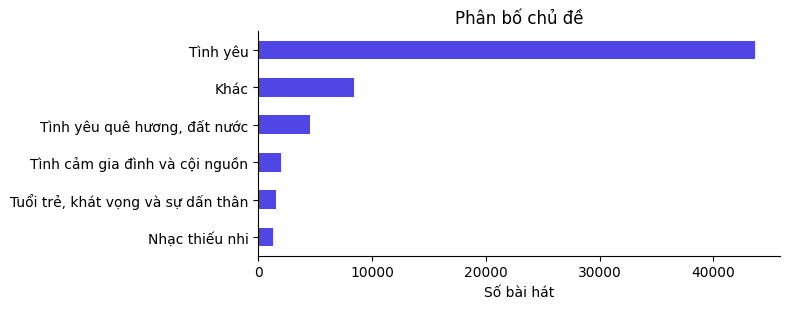

In [14]:
topic_counts = df_meaning["topic_meaning"].value_counts()
summary = topic_counts.rename("số bài hát").to_frame()
summary["tỷ lệ (%)"] = (topic_counts / len(df_meaning) * 100).round(1)
display(summary)

try:
    import matplotlib.pyplot as plt

    ax = topic_counts.sort_values().plot.barh(figsize=(8, 3.2), color="#4F46E5")
    ax.set_xlabel("Số bài hát")
    ax.set_ylabel("")
    ax.set_title("Phân bố chủ đề")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    plt.tight_layout()
    plt.show()
except ImportError:
    pass

## 14. Lưu file kết quả
Chỉ ghi những gì cần thiết và **đè lên file cũ cùng tên**, không tạo file mới:
- `final_dataset_with_topics_meaning.csv` luôn được cập nhật;
- `.xlsx` / `.parquet` cùng tên chỉ được cập nhật **nếu đã tồn tại** trong `data` (để các bản luôn đồng bộ);
- nếu file đang mở trong Excel, notebook báo để bạn đóng file rồi chạy lại cell này — không tạo bản sao `_updated`;
- chế độ demo (không có dữ liệu thật): không ghi file dữ liệu nào.

In [15]:
def write_table(path, writer, label):
    """Ghi đè file cũ cùng tên. Không tạo bản sao nếu ghi thất bại."""
    try:
        writer(path)
        print(f"Đã cập nhật {label}: {path}")
    except PermissionError:
        print(f"[CHƯA GHI ĐƯỢC] {path.name} đang được mở ở chương trình khác (Excel?). Hãy đóng file rồi chạy lại cell này.")
    except ImportError as exc:
        print(f"[BỎ QUA] {label}: thiếu thư viện '{exc.name or 'pyarrow/openpyxl'}'.")


if OUT_DIR is None:
    print("Chế độ demo: không ghi file dữ liệu.")
else:
    base = OUT_DIR / CFG.DATASET_NAME
    write_table(base.with_suffix(".csv"), lambda p: df_meaning.to_csv(p, index=False, encoding="utf-8-sig"), "CSV")
    for ext, writer in ((".xlsx", lambda p: df_meaning.to_excel(p, index=False)),
                        (".parquet", lambda p: df_meaning.to_parquet(p, index=False))):
        if base.with_suffix(ext).exists():            # chỉ đồng bộ file đã có, không tạo định dạng mới
            write_table(base.with_suffix(ext), writer, ext[1:].upper())

Đã cập nhật CSV: D:\Dự án CNTT\52300123\source_code\data\final_dataset_with_topics_meaning.csv


## 15. Tạo giao diện HTML
Một file HTML **độc lập** (`demo.html`, nằm ngoài thư mục `data`) (dữ liệu nhúng sẵn, mở bằng trình duyệt, không cần server). Giao diện cho phép:
- tra cứu bài hát theo **tên** hoặc **lời** (khớp chính xác / một đoạn / n‑gram);
- nếu lời **không có trong dataset** → ước lượng chủ đề bằng chính các mô hình ở bước 7–9 (kèm ghi chú đây là dự đoán), hoặc xếp vào **Khác** khi không đủ căn cứ;
- hiện thêm dòng **"Từ ngữ ẩn dụ / lóng"** — những từ không có trong bộ từ khóa nhưng gắn với chủ đề của bài;
- hiện **cảm xúc chủ đạo** (Vui tươi / Bình yên / Buồn / Mạnh mẽ) kèm những từ gợi cảm xúc; lời mới cũng được ước lượng cảm xúc;
- lấy bài ngẫu nhiên, hoặc bấm một chủ đề để xem thử một bài thuộc chủ đề đó;
- giao diện chỉ có nền tối, phối màu theo tranh sơn mài (mỗi chủ đề một sắc màu).

> Lời bài hát được nhúng đầy đủ để đối sánh chính xác, nên với dataset lớn (hàng chục nghìn bài) file HTML có thể nặng hàng chục MB.

In [16]:
HTML_TEMPLATE = r"""<!DOCTYPE html>
<html lang="vi">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<meta name="color-scheme" content="dark">
<title>Bài hát này nói về điều gì?</title>
<link rel="preconnect" href="https://fonts.googleapis.com">
<link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>
<link href="https://fonts.googleapis.com/css2?family=Be+Vietnam+Pro:wght@400;500;600;700&family=Noto+Serif+Display:wght@500;600&display=swap" rel="stylesheet">
<style>
/* Sơn mài: nền then, mỗi chủ đề một sắc màu phẳng, từ bằng chứng khảm trắng vỏ trứng. Chỉ có nền tối. */
:root {
  color-scheme: dark;
  --then: #0E0907; --rail: #150D0A; --surface: #1A110D; --line: #3A2A20; --line-2: #4A372B;
  --ink: #EFE7D6; --ink-2: #D6C9B6; --muted: #B9A996; --on-pigment: #1A0B10;
  --gold: #E0AE48; --gold-hi: #EBC06A; --gold-lo: #CF9C38; --on-gold: #1B1204; --alert: #F28A72;
  --t0: #E2533A; --t1: #E0AE48; --t2: #3FA9A0; --t3: #E58CA4; --t4: #A5C663; --t5: #BDB8AE;
  --display: 'Noto Serif Display', 'Noto Serif', Georgia, 'Times New Roman', serif;
  --ease: cubic-bezier(.16, 1, .3, 1);
}
*, *::before, *::after { box-sizing: border-box; }
html { background: var(--then); scrollbar-color: var(--line-2) var(--then); }
body {
  margin: 0; min-height: 100vh; display: grid; grid-template-columns: 300px minmax(0, 1fr);
  background: var(--then); color: var(--ink); caret-color: var(--gold);
  font: 400 16px/1.5 'Be Vietnam Pro', 'Segoe UI', system-ui, sans-serif; font-variant-numeric: tabular-nums;
}
::selection { background: var(--gold); color: var(--on-gold); }
:focus-visible { outline: 2px solid var(--gold); outline-offset: 2px; }

/* ---- Bình phong sáu chủ đề ---- */
.screen { position: sticky; top: 0; height: 100vh; overflow-y: auto; display: flex; flex-direction: column; background: var(--rail); border-right: 1px solid var(--line); }
h1 { margin: 0; padding: 30px 26px 24px; font: 600 1.7rem/1.12 var(--display); text-wrap: balance; }
.fold { flex: 1; display: flex; flex-direction: column; }
.leaf {
  flex: 1; display: grid; grid-template-columns: 14px minmax(0, 1fr); min-height: 76px; padding: 0;
  border: 0; border-top: 1px solid var(--line); background: transparent; color: var(--ink);
  font: inherit; text-align: left; cursor: pointer; transition: background-color .25s var(--ease), color .25s var(--ease);
}
.leaf::before { content: ""; background: var(--tc); }
.leaf-body { display: block; padding: 13px 18px; }
.leaf-name { display: block; font-weight: 600; font-size: .94rem; line-height: 1.25; text-wrap: balance; }
.leaf-count { display: block; margin-top: 3px; color: var(--muted); font-size: .81rem; }
.leaf-bar { display: block; height: 4px; min-width: 3px; margin-top: 9px; background: var(--tc); }
.leaf:hover:not(:disabled) { background: color-mix(in srgb, var(--tc) 16%, var(--rail)); }
.leaf[aria-pressed="true"], .leaf[aria-pressed="true"]:hover { background: var(--tc); color: var(--on-pigment); }
.leaf[aria-pressed="true"] .leaf-count { color: var(--on-pigment); }
.leaf[aria-pressed="true"] .leaf-bar { background: var(--on-pigment); }
.leaf:disabled { cursor: default; opacity: .45; }
.leaf:focus-visible { outline-offset: -3px; }
.leaf[aria-pressed="true"]:focus-visible { outline-color: var(--on-pigment); }
.screen-foot { margin: 0; padding: 14px 26px 18px; border-top: 1px solid var(--line); color: var(--muted); font-size: .81rem; }

/* ---- Vùng làm việc ---- */
.work { display: grid; grid-template-columns: minmax(320px, 460px) minmax(0, 1fr); gap: 28px; align-items: start; max-width: 1400px; padding: 30px 36px 48px; }
label { display: block; margin-bottom: 8px; font-weight: 600; font-size: .875rem; }
input, textarea {
  display: block; width: 100%; padding: 13px 14px; border: 1px solid var(--line-2); border-radius: 0;
  background: var(--surface); color: var(--ink); font: inherit;
}
input { margin-bottom: 22px; }
textarea { height: min(470px, 46vh); min-height: 200px; resize: vertical; line-height: 1.8; color: var(--ink-2); scrollbar-color: var(--line-2) var(--surface); }
::placeholder { color: var(--muted); opacity: 1; }
input:hover, textarea:hover { border-color: var(--muted); }
input:focus-visible, textarea:focus-visible { outline-offset: 0; border-color: var(--gold); }
.alert { margin: 12px 0 0; color: var(--alert); font-weight: 600; }
.alert:empty { display: none; }
.actions { display: flex; flex-wrap: wrap; gap: 10px; margin-top: 14px; }
.btn { padding: 13px 18px; border: 1px solid var(--line-2); background: transparent; color: var(--ink); font-family: inherit; font-weight: 700; font-size: .94rem; line-height: 1.2; cursor: pointer; }
.btn:hover { border-color: var(--ink); }
.btn:active { background: var(--surface); }
.btn.primary { flex: 1; background: var(--gold); border-color: var(--gold); color: var(--on-gold); }
.btn.primary:hover { background: var(--gold-hi); border-color: var(--gold-hi); }
.btn.primary:active { background: var(--gold-lo); border-color: var(--gold-lo); }
.btn.primary.busy { pointer-events: none; background: var(--line-2); border-color: var(--line-2); color: var(--ink); }
.hint { margin: 12px 0 0; color: var(--muted); font-size: .84rem; }

/* ---- Tấm sơn kết quả ---- */
.panel {
  display: flex; flex-direction: column; justify-content: space-between; gap: 40px; min-height: 372px;
  padding: 28px 32px 34px; background: var(--tc); color: var(--on-pigment); animation: lacquer .6s var(--ease);
}
@keyframes lacquer { from { clip-path: inset(0 100% 0 0); } to { clip-path: inset(0); } }
.panel-song { display: flex; flex-wrap: wrap; align-items: baseline; gap: 4px 14px; }
h2 { margin: 0; font-size: 1.5rem; font-weight: 700; line-height: 1.25; word-break: break-word; }
.by { font-weight: 600; font-size: 1.06rem; }
.stamp { margin-left: auto; padding: 3px 10px; border: 2px solid currentColor; font-weight: 700; font-size: .84rem; letter-spacing: .04em; text-transform: uppercase; transform: rotate(-2deg); }
.verdict { margin: 0; font: 600 clamp(2.5rem, 1.1rem + 4vw, 4.9rem)/1.02 var(--display); letter-spacing: -.015em; text-wrap: balance; }
.panel.blank { justify-content: flex-end; gap: 14px; background: var(--surface); color: var(--ink); box-shadow: inset 0 0 0 1px var(--line); animation: none; }
.panel.blank .verdict { font-size: clamp(2rem, 1.2rem + 2vw, 3rem); }
.blank-help { margin: 0; max-width: 46ch; color: var(--ink-2); }

dl { display: grid; grid-template-columns: 190px minmax(0, 1fr); margin: 0; }
dt, dd { margin: 0; padding: 17px 0; border-bottom: 1px solid var(--line); }
dt { padding-top: 20px; color: var(--muted); font-size: .875rem; }
dd { word-break: break-word; }
.inlay, .gilt { display: inline-block; margin: 0 6px 5px 0; padding: 3px 11px; font-size: .94rem; }
.inlay { background: var(--ink); color: #17100B; font-weight: 600; }
.gilt { padding: 2px 10px; border: 1px solid var(--gold); color: var(--gold); }
.none { color: var(--muted); }
.emo { margin-right: 12px; font-weight: 700; }
.emo-kw { color: var(--muted); }
a { color: var(--gold); text-underline-offset: 3px; }
a:hover { color: var(--gold-hi); }
.note { margin: 18px 0 0; max-width: 70ch; color: var(--ink-2); font-size: .94rem; }

@media (max-width: 1180px) {
  body { display: block; }
  .screen { position: static; height: auto; border-right: 0; border-bottom: 1px solid var(--line); }
  .fold { display: grid; grid-template-columns: repeat(3, minmax(0, 1fr)); }
  .leaf { border-right: 1px solid var(--line); }
  .work { padding: 24px 24px 40px; }
}
@media (max-width: 860px) {
  .work { grid-template-columns: minmax(0, 1fr); }
  textarea { height: 220px; }
  .panel { min-height: 0; }
}
@media (max-width: 620px) {
  h1 { padding: 22px 18px 18px; font-size: 1.45rem; }
  .fold { grid-template-columns: repeat(2, minmax(0, 1fr)); }
  .screen-foot { padding: 12px 18px 14px; }
  .work { padding: 18px 16px 36px; }
  .panel { padding: 22px 20px 26px; }
  dl { grid-template-columns: minmax(0, 1fr); }
  dt { padding: 14px 0 0; border-bottom: 0; }
  dd { padding-top: 4px; }
}
@media (prefers-reduced-motion: reduce) { *, *::before, *::after { animation: none !important; transition: none !important; } }
</style>
</head>
<body>
<aside class="screen">
  <h1>Bài hát này nói về điều gì?</h1>
  <nav class="fold" id="topics" aria-label="Chủ đề"></nav>
  <p class="screen-foot" id="corpusNote"></p>
</aside>

<main class="work">
  <section aria-label="Tra cứu">
    <label for="quickSearch">Tìm theo tên bài hát</label>
    <input type="text" id="quickSearch" list="songTitleList" autocomplete="off" placeholder="Gõ vài chữ của tên bài hát">
    <datalist id="songTitleList"></datalist>

    <label for="lyricBox">Hoặc dán lời bài hát</label>
    <textarea id="lyricBox" placeholder="Dán một đoạn hoặc toàn bộ lời bài hát" aria-describedby="formError"></textarea>
    <p class="alert" id="formError" role="alert"></p>
    <div class="actions">
      <button type="button" class="btn primary" id="analyzeBtn">Tra cứu</button>
      <button type="button" class="btn" id="randomBtn">Bài ngẫu nhiên</button>
      <button type="button" class="btn" id="clearBtn">Xóa</button>
    </div>
    <p class="hint">Nhấn Ctrl + Enter để tra cứu. Lời chưa có trong dữ liệu sẽ được ước lượng chủ đề.</p>
  </section>

  <section aria-live="polite" aria-label="Kết quả"><div id="outputArea"></div></section>
</main>

<script>
// Mỗi bài: [tiêu đề, tác giả, thể loại, url, lời, topic_id, topic_meaning, topic_keywords, topic_full_description, từ ẩn dụ/lóng, cảm xúc, từ gợi cảm xúc]
const SONGS = __SONGS_JSON__;
const TOPIC_NAMES = __TOPICS_JSON__;          // chủ đề cuối cùng là "Khác"
const PHRASES = new Set(__PHRASES_JSON__);
const SLANG = __SLANG_JSON__;                // {map: lóng -> chuẩn, tone: dấu thanh cũ -> mới}; khớp canon_text ở notebook
const EMB = __EMB_JSON__;                     // vector ngữ nghĩa + hệ số (null nếu tắt)
const IMPLICIT = __IMPLICIT_JSON__;           // thuật ngữ ẩn dụ / lóng -> [chủ đề, z]
const MODEL = __MODEL_JSON__;                 // mô hình Naive Bayes rút gọn (dùng cho lời chưa có trong dữ liệu)
const EMO = __EMOTION_JSON__;                 // bộ đoán cảm xúc rút gọn (null nếu tắt)
const F = { TITLE: 0, AUTHOR: 1, GENRE: 2, URL: 3, LYRICS: 4, TID: 5, TOPIC: 6, KW: 7, FULL: 8, IMPL: 9, EMO: 10, EMO_KW: 11 };

const $ = (id) => document.getElementById(id);
const esc = (v) => String(v ?? "").replace(/[&<>"']/g, (c) => ({ "&": "&amp;", "<": "&lt;", ">": "&gt;", '"': "&quot;", "'": "&#39;" }[c]));
const norm = (v) => String(v ?? "").normalize("NFC").toLowerCase()
  .replace(/\[.*?\]|\(.*?\)/g, " ").replace(/[^\p{L}\p{N}\s]/gu, " ").replace(/\s+/g, " ").trim();
const tcolor = (tid) => `style="--tc: var(--t${Math.min(Number(tid), 5)})"`;

const NORM_TITLES = SONGS.map((s) => norm(s[F.TITLE]));
const NORM_LYRICS = SONGS.map((s) => " " + norm(s[F.LYRICS]) + " ");
const BY_TOPIC = TOPIC_NAMES.map(() => []);
SONGS.forEach((s, i) => { if (BY_TOPIC[s[F.TID]]) BY_TOPIC[s[F.TID]].push(i); });
let selectedIdx = -1;
const SUGGEST = new Map();                                   // nhãn trong ô gợi ý -> chỉ số bài hát
const songLabel = (i) => `${SONGS[i][F.TITLE]} — ${SONGS[i][F.AUTHOR]}`;

/* ---------- Chủ đề ---------- */
const fmt = (n) => n.toLocaleString("vi-VN");
function renderTopics() {
  const max = Math.max(1, ...BY_TOPIC.map((a) => a.length));            // thanh dài theo số bài, so với chủ đề đông nhất
  $("topics").innerHTML = TOPIC_NAMES.map((name, tid) => {
    const n = BY_TOPIC[tid].length;
    return `<button type="button" class="leaf" ${tcolor(tid)} data-tid="${tid}" aria-pressed="false" ${n ? "" : "disabled"}>
      <span class="leaf-body"><span class="leaf-name">${esc(name)}</span><span class="leaf-count">${fmt(n)} bài</span><span class="leaf-bar" style="width:${(n / max * 100).toFixed(1)}%"></span></span></button>`;
  }).join("");
  $("corpusNote").textContent = `Tổng ${fmt(SONGS.length)} bài. Bấm một chủ đề để xem thử một bài.`;
}
function markTopic(active) {
  $("topics").querySelectorAll(".leaf").forEach((b) => b.setAttribute("aria-pressed", String(Number(b.dataset.tid) === active)));
}

/* ---------- Gợi ý tên bài ---------- */
function updateSuggestions(query) {
  const key = norm(query), list = $("songTitleList");
  if (key.length < 2) { list.innerHTML = ""; return; }
  let out = "", n = 0;
  for (let i = 0; i < SONGS.length && n < 50; i++) {
    if (!NORM_TITLES[i].includes(key)) continue;
    let label = songLabel(i);                                // "Tên bài — Tác giả" để phân biệt bài trùng tên
    if (SUGGEST.has(label) && SUGGEST.get(label) !== i) label += ` (${SONGS[i][F.GENRE]})`;
    for (let k = 2; SUGGEST.has(label) && SUGGEST.get(label) !== i; k++) label = `${songLabel(i)} #${k}`;
    SUGGEST.set(label, i);
    out += `<option value="${esc(label)}"></option>`;
    n++;
  }
  list.innerHTML = out;
}

/* ---------- Tìm bài khớp trong dataset ---------- */
function findMatch(raw) {
  if (selectedIdx >= 0 && raw.trim() === SONGS[selectedIdx][F.LYRICS].trim()) return { idx: selectedIdx, pct: "100.0" };
  const clean = norm(raw);
  if (!clean) return null;
  const padded = " " + clean + " ";
  const words = clean.split(" ").filter(Boolean);

  const byTitle = NORM_TITLES.indexOf(clean);
  if (byTitle !== -1) return { idx: byTitle, pct: "100.0" };

  if (words.length >= 4) {
    let best = -1, bestDiff = Infinity;
    for (let i = 0; i < SONGS.length; i++) {
      const lyr = NORM_LYRICS[i];
      if (lyr === padded) return { idx: i, pct: "100.0" };
      const contains = lyr.includes(padded);
      const contained = !contains && padded.includes(lyr) && lyr.length >= padded.length * 0.75;
      if (contains || contained) {
        const diff = Math.abs(lyr.length - padded.length);
        if (diff < bestDiff) { bestDiff = diff; best = i; }
      }
    }
    if (best !== -1) return { idx: best, pct: "100.0" };
  }

  const size = words.length >= 5 ? 4 : Math.max(2, words.length);
  const grams = [];
  for (let i = 0; i <= words.length - size; i++) grams.push(" " + words.slice(i, i + size).join(" ") + " ");
  if (!grams.length) return null;
  const step = Math.max(1, Math.floor(grams.length / 20));
  const anchors = grams.filter((_, i) => i % step === 0);

  const candidates = [];
  for (let i = 0; i < SONGS.length; i++) {
    let hits = 0;
    for (const a of anchors) if (NORM_LYRICS[i].includes(a)) hits++;
    if (hits) candidates.push({ i, hits });
  }
  candidates.sort((a, b) => b.hits - a.hits);

  let bestIdx = -1, bestScore = 0;
  for (const { i } of candidates.slice(0, 80)) {
    const lyr = NORM_LYRICS[i];
    let exact = 0;
    for (const g of grams) if (lyr.includes(g)) exact++;
    const coverage = exact / grams.length;
    const lenSim = Math.min(lyr.length, padded.length) / Math.max(lyr.length, padded.length);
    const score = coverage * 0.92 + lenSim * 0.08;
    if (coverage >= 0.55 && score > bestScore) { bestScore = score; bestIdx = i; }
  }
  return bestIdx === -1 ? null : { idx: bestIdx, pct: Math.min(100, bestScore * 100).toFixed(1) };
}

/* ---------- Ước lượng chủ đề cho lời mới (cùng mô hình với notebook) ---------- */
const MAX_PHRASE = Math.max(1, ...[...PHRASES].map((p) => p.split(" ").length));
const TONE_RE = new RegExp("(?:" + Object.keys(SLANG.tone).map((k) => (k[0] === "u" ? "(?<!q)" : "") + k).join("|") + ")(?!\\p{L})", "gu");
const canon = (t) => String(t ?? "").normalize("NFC").toLowerCase().replace(TONE_RE, (m) => SLANG.tone[m]).replace(/(\p{L})\1{2,}/gu, "$1");
function segment(text) {
  const toks = canon(text).replace(/[^\p{L}\p{N}_\s]/gu, " ").split(/\s+/).flatMap((t) => (SLANG.map[t] ?? t).split(" ")).filter((w) => w.length > 1);
  const out = [];
  let i = 0;
  while (i < toks.length) {
    let hit = false;
    for (let L = Math.min(MAX_PHRASE, toks.length - i); L >= 2; L--) {
      const cand = toks.slice(i, i + L).join(" ");
      if (PHRASES.has(cand)) { out.push(cand.replace(/ /g, "_")); i += L; hit = true; break; }
    }
    if (!hit) { out.push(toks[i]); i++; }
  }
  return out;
}

const logsumexp = (v) => { const m = Math.max(...v); return m + Math.log(v.reduce((s, x) => s + Math.exp(x - m), 0)); };
const logSoftmax = (v) => { const l = logsumexp(v); return v.map((x) => x - l); };

function classify(text) {
  const K = MODEL.K, other = K - 1;                  // "Khác" là lớp cuối của mô hình
  const seq = segment(text);
  const feats = [...new Set([...seq, ...seq.slice(1).map((w, i) => seq[i] + "|" + w)])];      // từ + cặp từ liền kề
  const none = { tid: other, name: TOPIC_NAMES[other], evidence: [], implicit: [] };
  const known = feats.filter((w) => MODEL.words[w]);
  if (known.length < MODEL.minFeatures) return none;
  const scale = Math.min(1, MODEL.nRef / Math.max(1, feats.length));
  const S = MODEL.const.map((c, k) => known.reduce((s, w) => s + MODEL.words[w][k], c) * scale);   // bằng chứng so với nền
  const T = S.map((s, k) => s + MODEL.logPrior[k]);
  const experts = [];
  if (MODEL.ctx) {                                    // chuyên gia ngữ cảnh
    experts.push(logSoftmax(MODEL.intercept.map((b, k) => b + scale * known.reduce((s, w) => s + MODEL.words[w][K + k], 0))));
  }
  if (EMB) {                                          // chuyên gia ngữ nghĩa ngầm: vector trung bình của các từ
    const vs = [...new Set(seq)].filter((w) => EMB.words[w]);
    const vec = new Array(EMB.dim).fill(0);
    vs.forEach((w) => EMB.words[w].forEach((x, d) => { vec[d] += x; }));
    const n = Math.max(1, vs.length);
    experts.push(logSoftmax(EMB.intercept.map((b, k) => b + EMB.coef[k].reduce((s, c, d) => s + c * vec[d] / n, 0))));
  }
  let best;
  if (experts.length) {                               // gộp: trung bình log-xác suất của mọi mô hình
    const all = [logSoftmax(T), ...experts];
    const pooled = T.map((_, k) => all.reduce((s, e) => s + e[k], 0) / all.length);
    const lp = logsumexp(pooled);
    best = pooled.indexOf(Math.max(...pooled));
    if (S[best] + MODEL.logPrior[best] - MODEL.logPriorOther < MODEL.minLogOdds || Math.exp(pooled[best] - lp) < MODEL.minPooled) return none;
  } else {                                            // chỉ mô hình từ khóa/EM
    best = T.indexOf(Math.max(...T));
    const runnerUp = Math.max(...S.filter((_, k) => k !== best));
    if (S[best] + MODEL.logPrior[best] - MODEL.logPriorOther < MODEL.minLogOdds || S[best] - runnerUp < MODEL.minBfNext) return none;
  }
  const evidence = [];
  const covered = new Set();
  for (const [w] of known.map((w) => [w, MODEL.words[w][best]]).filter(([, r]) => r > 0).sort((a, b) => b[1] - a[1])) {
    const parts = w.replace(/_/g, " ").split("|");
    if (parts.every((p) => covered.has(p))) continue;
    evidence.push(parts.join(" "));
    parts.forEach((p) => covered.add(p));
    if (evidence.length >= 8) break;
  }
  const implicit = feats.filter((w) => IMPLICIT[w] && IMPLICIT[w][0] === best)
    .sort((a, b) => IMPLICIT[b][1] - IMPLICIT[a][1]).slice(0, 5).map((w) => w.replace(/_/g, " ").replace(/\|/g, " "));
  return { tid: best, name: TOPIC_NAMES[best], evidence, implicit };
}

/* ---------- Cảm xúc chủ đạo (mô hình nhẹ học lại từ PhoBERT, cùng đặc trưng từ + cặp từ như notebook) ---------- */
function classifyEmotion(text) {
  if (!EMO) return null;
  const seq = segment(text);
  const feats = [...new Set([...seq, ...seq.slice(1).map((w, i) => seq[i] + "|" + w)])];
  const known = feats.filter((w) => EMO.words[w]);
  const scale = Math.min(1, MODEL.nRef / Math.max(1, feats.length));
  const z = EMO.intercept.map((b, k) => b + scale * known.reduce((s, w) => s + EMO.words[w][k], 0));
  const best = z.indexOf(Math.max(...z));
  const words = known.filter((w) => EMO.words[w][best] > 0).sort((a, b) => EMO.words[b][best] - EMO.words[a][best])
    .slice(0, 4).map((w) => w.replace(/_/g, " ").replace(/\|/g, " "));
  return { name: EMO.labels[best], words };
}

/* ---------- Hiển thị ---------- */
function linkHtml(u) {
  const first = String(u || "").split(",")[0].trim();
  return /^https?:\/\//i.test(first)
    ? `<a href="${esc(first)}" target="_blank" rel="noopener noreferrer">${esc(first)}</a>` : `<span class="none">Không có đường dẫn</span>`;
}
const row = (k, v) => `<dt>${k}</dt><dd>${v}</dd>`;
const emotionHtml = (name, kw) => `<strong class="emo">${esc(name)}</strong>${kw ? `<span class="emo-kw">gợi từ: ${esc(kw)}</span>` : ""}`;
const words = (text, cls) => /^không có/i.test(String(text).trim()) ? `<span class="none">${esc(text)}</span>`
  : String(text).split(",").map((w) => w.trim()).filter(Boolean).map((w) => `<span class="${cls}">${esc(w)}</span>`).join("");

function show(html, tid) {
  $("outputArea").innerHTML = html;
  $("formError").textContent = "";
  markTopic(tid);
}

// Tấm sơn màu chủ đề: tên bài ở trên, tên chủ đề cỡ lớn ở dưới; "dấu" ghi trạng thái (ước lượng, chưa đủ căn cứ, độ khớp)
const panel = (tid, title, by, verdict, stamp) => `
  <div class="panel" ${tcolor(tid)}>
    <div class="panel-song"><h2>${esc(title)}</h2>${by ? `<span class="by">${esc(by)}</span>` : ""}${stamp ? `<span class="stamp">${esc(stamp)}</span>` : ""}</div>
    <p class="verdict">${esc(verdict)}</p>
  </div>`;

function renderSong(idx, pct) {
  const s = SONGS[idx];
  show(panel(s[F.TID], s[F.TITLE], s[F.AUTHOR], s[F.TOPIC], pct !== "100.0" ? `Khớp ${pct.replace(".", ",")}%` : "") + `
    <dl>
      ${row("Thể loại", esc(s[F.GENRE]))}
      ${s[F.EMO] ? row("Cảm xúc", emotionHtml(s[F.EMO], s[F.EMO_KW])) : ""}
      ${row("Từ khóa chủ đề", words(s[F.KW], "inlay"))}
      ${s[F.IMPL] ? row("Từ ngữ ẩn dụ / lóng", words(s[F.IMPL], "gilt")) : ""}
      ${row("Đường dẫn", linkHtml(s[F.URL]))}
    </dl>`, s[F.TID]);
}

function renderPrediction(p, emo) {
  const other = p.tid === TOPIC_NAMES.length - 1;
  show(panel(p.tid, "Lời chưa có trong dữ liệu", "", p.name, other ? "Chưa đủ căn cứ" : "Ước lượng") + `
    <dl>${emo ? row("Cảm xúc", emotionHtml(emo.name, emo.words.join(", "))) : ""}${p.evidence.length ? row("Từ khóa nổi bật", words(p.evidence.join(","), "inlay")) : ""}${p.implicit.length ? row("Từ ngữ ẩn dụ / lóng", words(p.implicit.join(","), "gilt")) : ""}</dl>
    <p class="note">${other
      ? "Nội dung chưa chứa đủ dấu hiệu rõ ràng của một chủ đề nào, nên được xếp vào nhóm Khác."
      : "Không tìm thấy bài nào khớp trong dữ liệu, nên chủ đề được ước lượng từ nội dung lời và có thể kém chính xác hơn các bài đã có sẵn."}</p>`, p.tid);
}

const showError = (msg) => { $("formError").textContent = msg; $("lyricBox").focus(); };
const showEmpty = () => show(`
  <div class="panel blank">
    <p class="verdict">Chưa chọn bài nào</p>
    <p class="blank-help">Gõ tên bài hoặc dán lời rồi bấm Tra cứu. Bấm một chủ đề để xem thử một bài thuộc chủ đề đó.</p>
  </div>`, -1);

/* ---------- Hành động ---------- */
function runAnalysis(raw) {
  const match = findMatch(raw);
  if (match) { $("quickSearch").value = songLabel(match.idx); return renderSong(match.idx, match.pct); }
  renderPrediction(classify(raw), classifyEmotion(raw));
}

function analyze() {
  const raw = $("lyricBox").value.trim();
  if (!raw) return showError("Chưa có lời bài hát. Hãy dán lời vào ô trên, hoặc chọn một bài theo tên.");
  const btn = $("analyzeBtn");
  btn.classList.add("busy");                               // cho trình duyệt vẽ trạng thái chờ trước khi tìm
  btn.textContent = "Đang tra cứu";
  setTimeout(() => { try { runAnalysis(raw); } finally { btn.classList.remove("busy"); btn.textContent = "Tra cứu"; } }, 30);
}

function open_(idx) {
  selectedIdx = idx;
  $("quickSearch").value = songLabel(idx);
  $("lyricBox").value = SONGS[idx][F.LYRICS];
  renderSong(idx, "100.0");
}
const pickRandom = (pool) => { const a = pool || SONGS.map((_, i) => i); if (a.length) open_(a[Math.floor(Math.random() * a.length)]); };

function selectByTitle(value) {
  let idx = SUGGEST.get(value);                              // chọn từ gợi ý: đúng bài đã chọn
  if (idx === undefined) idx = NORM_TITLES.indexOf(norm(value));   // gõ tay: lấy bài đầu tiên trùng tên
  if (idx !== -1) open_(idx);
}
function clearAll() { selectedIdx = -1; $("quickSearch").value = ""; $("lyricBox").value = ""; showEmpty(); }

$("quickSearch").addEventListener("input", (e) => updateSuggestions(e.target.value));
$("quickSearch").addEventListener("change", (e) => selectByTitle(e.target.value));
$("lyricBox").addEventListener("input", () => { selectedIdx = -1; $("formError").textContent = ""; });
$("lyricBox").addEventListener("keydown", (e) => { if (e.key === "Enter" && (e.ctrlKey || e.metaKey)) analyze(); });
$("analyzeBtn").addEventListener("click", analyze);
$("randomBtn").addEventListener("click", () => pickRandom());
$("clearBtn").addEventListener("click", clearAll);
$("topics").addEventListener("click", (e) => {
  const b = e.target.closest(".leaf");
  if (b && !b.disabled) pickRandom(BY_TOPIC[Number(b.dataset.tid)]);
});
renderTopics();
showEmpty();
</script>
</body>
</html>

"""


def nfc(value) -> str:
    return unicodedata.normalize("NFC", str(value).strip())


def to_js_json(obj) -> str:
    """JSON an toàn để nhúng trong <script> (tránh chuỗi '</script>')."""
    return json.dumps(obj, ensure_ascii=False, separators=(",", ":")).replace("</", "<\\/")


def export_model_for_js(model, ctx, vocab, max_words):
    """Rút gọn mô hình để nhúng vào web. Mỗi từ: K mức đẩy (từ khóa/EM) + K hệ số (ngữ cảnh, nếu có)."""
    p, q = model["p"], model["q"]
    K = p.shape[0]
    ratio, const = evidence_ratio(model)                                 # K x V, K
    pi = np.exp(model["log_pi"])
    info = (pi[:K, None] * p * np.abs(ratio)).sum(axis=0)                # từ nào mang nhiều thông tin nhất
    keep = set(np.argsort(-info)[:max_words].tolist())
    coef = ctx["coef"] if ctx else np.zeros_like(ratio)
    if ctx:
        keep |= set(np.argsort(-np.abs(coef).max(axis=0))[:max_words].tolist())
    words = {str(vocab[j]): [round(float(x), 2) for x in ratio[:, j]] + [round(float(x), 2) for x in coef[:, j]] for j in keep}
    return {
        "K": K,
        "words": words,
        "const": [round(float(x), 3) for x in const],
        "logPrior": [round(float(x), 3) for x in model["log_pi"][:K]],
        "nRef": model["n_ref"],
        "ctx": bool(ctx),
        "intercept": [round(float(x), 3) for x in (ctx["intercept"] if ctx else np.zeros(K))],
        "logPriorOther": round(float(model["log_pi"][K]), 3),
        "minLogOdds": CFG.MIN_LOG_ODDS_VS_OTHER,
        "minBfNext": CFG.MIN_LOG_BF_RUNNER_UP,
        "minPooled": CFG.MIN_POOLED_POSTERIOR,
        "minFeatures": CFG.MIN_FEATURES,
    }


def export_embedding_for_js(emb):
    """Vector ngữ nghĩa của các từ KHÔNG phải hạt giống + hệ số hồi quy (khớp với cách huấn luyện ở bước 9)."""
    if emb is None or emb["expert"] is None:
        return None
    W, keep, ex = emb["W"], emb["keep"], emb["expert"]
    return {
        "dim": int(W.shape[1]),
        "words": {str(vocab[emb_cols[p]]): [round(float(x), 2) for x in W[p]] for p in range(len(emb_cols)) if keep[p] > 0},
        "coef": [[round(float(x), 3) for x in row] for row in ex["coef"]],
        "intercept": [round(float(x), 3) for x in ex["intercept"]],
    }


def build_html(df: pd.DataFrame) -> str:
    songs_db = [
        [
            nfc(r.title), nfc(r.author), nfc(r.genre),
            nfc(r.urls).split(",")[0].strip(), nfc(r.lyrics),
            int(r.topic_id), nfc(r.topic_meaning), nfc(r.topic_keywords), nfc(r.topic_full_description), nfc(r.topic_implicit),
            nfc(r.emotion), nfc(r.emotion_keywords),
        ]
        for r in df.fillna("").itertuples(index=False)
    ]
    replacements = {
        "__SONGS_JSON__": to_js_json(songs_db),
        "__TOPICS_JSON__": to_js_json(ALL_TOPICS),
        "__PHRASES_JSON__": to_js_json(sorted(PHRASES)),
        "__SLANG_JSON__": to_js_json({"map": SLANG_MAP, "tone": TONE_OLD_TO_NEW}),
        "__EMB_JSON__": to_js_json(export_embedding_for_js(emb_main)),
        "__IMPLICIT_JSON__": to_js_json({str(vocab[j]): [k, round(z, 1)] for k, d in enumerate(IMPLICIT) for j, z in d.items()}),
        "__MODEL_JSON__": to_js_json(export_model_for_js(nb_model, ctx_model, vocab, CFG.EXPORT_WORDS)),
        "__EMOTION_JSON__": to_js_json(export_emotion_for_js(emo_light, vocab, CFG.EMOTION_EXPORT_WORDS)),
    }
    page = HTML_TEMPLATE
    for placeholder, value in replacements.items():
        page = page.replace(placeholder, value)
    return page


HTML_PATH = HTML_DIR / CFG.HTML_NAME
HTML_PATH.write_text(build_html(df_meaning), encoding="utf-8")
print(f"Đã tạo giao diện ({len(df_meaning):,} bài, {HTML_PATH.stat().st_size / 1e6:.2f} MB): {HTML_PATH}")

if CFG.OPEN_HTML:
    import webbrowser
    webbrowser.open(HTML_PATH.as_uri())
else:
    print("Mở file trên bằng trình duyệt để dùng (hoặc đặt CFG.OPEN_HTML = True).")

Đã tạo giao diện (61,525 bài, 120.81 MB): D:\Dự án CNTT\52300123\source_code\demo.html
Mở file trên bằng trình duyệt để dùng (hoặc đặt CFG.OPEN_HTML = True).


## 16. Kiểm tra nhanh
Xác nhận bảng kết quả hợp lệ và các file đã được tạo đúng.

In [17]:
assert list(df_meaning.columns) == REQUIRED_COLS, "Thiếu hoặc sai thứ tự cột"
assert not df_meaning.isna().any().any(), "Còn giá trị rỗng (NaN)"
assert df_meaning["topic_id"].between(0, OTHER_ID).all(), "topic_id ngoài phạm vi"
assert (df_meaning["topic_meaning"] == df_meaning["topic_id"].map(dict(enumerate(ALL_TOPICS)))).all(), "topic_id và topic_meaning không khớp"
assert df_meaning["emotion"].isin(EMOTIONS + [""]).all(), "cảm xúc ngoài danh sách"
assert HTML_PATH.exists() and "__SONGS_JSON__" not in HTML_PATH.read_text(encoding="utf-8"), "HTML chưa được điền dữ liệu"

print("Tất cả kiểm tra đều đạt.")
for path in ([OUT_DIR / f"{CFG.DATASET_NAME}.csv"] if OUT_DIR else []) + [HTML_PATH]:
    print(f"  {path}  ({path.stat().st_size / 1024:,.0f} KB)")

# --- Tự kiểm chuẩn hóa lóng / dấu thanh / chữ kéo dài (phải khớp với bộ tách của web) ---
_got = normalize_for_matching("Anh k yêuuuu em, hoà bình thuý khoẻ, quý hoàng")
assert _got == "anh không yêu em hòa bình thúy khỏe quý hoàng", _got
assert normalize_for_matching("dzô nhìu wá ny") == "vô nhiều quá người yêu"
assert all(canon_text(kw) == kw for kws in TOPIC_RULES.values() for kw in kws), "từ khóa chưa ở dạng chuẩn"
print("Chuẩn hóa lóng / dấu thanh: OK")


Tất cả kiểm tra đều đạt.
  D:\Dự án CNTT\52300123\source_code\data\final_dataset_with_topics_meaning.csv  (100,365 KB)
  D:\Dự án CNTT\52300123\source_code\demo.html  (117,976 KB)
Chuẩn hóa lóng / dấu thanh: OK
